# Sistema de alerta de estaciones sin bicis con aprendizaje en flujo de datos

### Detección de *data drift* y *concept drift* en el sistema de bicicletas compartidas de Toulouse

**Asignatura:** Aprendizaje Automático en Series Temporales y Flujos de Datos · Máster en Inteligencia Artificial Aplicada · Universidad Carlos III de Madrid · Curso 2026-2027

**Autores:** Álvaro Alonso Haya · Antonio Ángel Bello Castro · Martín Hernández Tonzán

**Profesor:** José Antonio Iglesias Martínez

---

**Índice**

1. Introducción y motivación
2. Objetivo e hipótesis
3. Trabajos similares
4. Desarrollo
   - 4.1 Flujo de sensores: origen, calidad y construcción
   - 4.2 Análisis del comportamiento del flujo de sensores
   - 4.3 Estrategia de aprendizaje y evaluación
   - 4.4 Elección razonada del modelo de alerta
   - 4.5 *Concept drift* en el flujo real (H2)
   - 4.6 *Data drift* en el flujo real (H1, H3 y H4)
   - 4.7 *Concept drift* controlado y estrategias de adaptación
   - 4.8 Flujo de avisos de usuarios: clasificación de texto online (H5 y H6)
   - 4.9 Unión de los dos subsistemas: ¿llega la alerta antes que las quejas?
5. Resultados
6. Análisis crítico y conclusiones
7. Referencias

## Cómo ejecutar este cuaderno

- **En Google Colab:** *Entorno de ejecución → Ejecutar todas*. La primera celda instala River 0.26.1 (la versión con la que se obtuvieron los resultados). Si al instalarla cambia la versión de `numpy`, la celda reinicia la sesión automáticamente: basta con volver a pulsar *Ejecutar todas*.
- **No hay que subir ningún fichero.** El flujo de sensores se construye a partir del dataset `Bikes`, que River descarga solo, y el flujo de avisos de usuarios se genera dentro del cuaderno con una semilla fija. Los dos se guardan como CSV y se leen con `river.stream.iter_csv`, simulando la llegada de los datos.
- **Duración:** unos 15 minutos en Colab. Lo más lento es repetir el *Adaptive Random Forest* con 10 semillas, que hacemos para no sacar conclusiones de una sola ejecución.
- Los modelos aleatorios usan semillas fijas, pero los resultados pueden variar ligeramente con otras versiones de las librerías.

In [1]:
# Instalación de River (versión fija para que los resultados sean reproducibles)
import importlib.metadata as metadata
import os
import sys

numpy_antes = metadata.version("numpy")
%pip install -q river==0.26.1
if "google.colab" in sys.modules and metadata.version("numpy") != numpy_antes:
    print("numpy ha cambiado: se reinicia la sesión. Vuelve a pulsar 'Ejecutar todas'.")
    os.kill(os.getpid(), 9)
else:
    print("River instalado")

River instalado


In [2]:
# Librerías y estilo de las gráficas
import collections
import math
import re
import time
import unicodedata
import warnings
from itertools import islice

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import river
from river import (compose, datasets, drift, evaluate, feature_extraction, forest, linear_model, metrics,
                   multiclass, naive_bayes, optim, preprocessing, stats, stream, tree)

warnings.filterwarnings("ignore")
print("River:", river.__version__)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 100)

# Paleta y estilo de las gráficas
AZUL, NARANJA, VERDE, ROJO, MORADO, GRIS, SOMBRA, TINTA = ("#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a5cc2",
                                                          "#8a8985", "#e6e5e0", "#2b2b2a")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": SOMBRA, "grid.linewidth": 0.6,
    "axes.edgecolor": GRIS, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5,
})

River: 0.26.1


# 1. Introducción y motivación

En los sistemas de bicicletas compartidas el servicio falla de dos formas: un usuario llega a una estación y **no encuentra ninguna bici**, o quiere devolverla y **la estación está llena**. Los operadores intentan evitarlo redistribuyendo bicis entre estaciones con camiones (*rebalancing*), pero esa operación es cara y suele hacerse tarde, por lo que muchas estaciones se quedan vacías o llenas durante horas [1]. Cuando eso ocurre, el operador se entera sobre todo por las **quejas de los usuarios**, que llegan mezcladas con avisos de averías, problemas de la aplicación o simples consultas, y que alguien tiene que leer y enviar al equipo adecuado.

Este proyecto plantea un sistema para la estación ***pomme*** de Toulouse que aprende de **dos flujos de datos** con un mismo fin, que la estación no se quede sin servicio:

1. **Flujo de sensores (real).** Cada 30 minutos llega el estado de la estación (bicis disponibles), el calendario y el tiempo. Con él, el sistema predice si **dentro de 2 horas** la estación tendrá **2 bicis o menos**, con margen para reponer bicis o avisar a los usuarios antes de que la estación se vacíe.
2. **Flujo de avisos de los usuarios (texto).** Los mensajes que los usuarios envían por la aplicación o las redes sociales se **clasifican online por tipo de incidencia** (sin bicis, estación llena, avería de una bici, avería de la estación, aplicación y pagos, otros) para enviarlos al equipo que debe atenderlos.

**¿Por qué flujos de datos?** Los datos llegan de forma continua y el comportamiento de los usuarios cambia con el tiempo: entre laborables y fines de semana, con las vacaciones, con la vuelta a clase o con el tiempo; y los avisos cambian con los turistas del verano o cuando el operador reorganiza sus categorías. Un modelo entrenado una vez con datos históricos se queda desactualizado. Por eso los modelos **aprenden instancia a instancia, en una sola pasada y con memoria acotada**, y pueden predecir en cualquier momento.

En este contexto aparece el *model drift* [2]: la degradación del modelo porque cambian los datos de entrada (***data drift***) o la relación entre las variables y la etiqueta (***concept drift***). Por eso el objetivo no es solo predecir, sino **detectar cuándo cambia el comportamiento y cuándo el modelo deja de ser fiable, y decidir cómo reaccionar**.

# 2. Objetivo e hipótesis

**Objetivo general.** Diseñar, evaluar y analizar críticamente un sistema de aprendizaje en flujo de datos que ayude a mantener en servicio la estación *pomme*, combinando la **predicción de que se va a quedar sin bicis** (flujo de sensores) con la **clasificación automática de los avisos de los usuarios** (flujo de texto), y que **detecte los cambios** en ambos flujos y **se adapte** a ellos.

**Objetivos específicos:**
1. **Construir los flujos** y comprobar que están bien construidos: un flujo regular a partir de lecturas irregulares y un flujo de avisos ligado al estado real de la estación.
2. **Predecir cada 30 minutos** si dentro de 2 horas habrá 2 bicis o menos, con modelos online que mejoren un *baseline* sin aprendizaje (persistencia) teniendo en cuenta que la etiqueta llega 2 horas tarde.
3. **Detectar *data drift*** sin esperar a las etiquetas: en el uso de la estación, en la meteorología y en el vocabulario de los avisos.
4. **Detectar *concept drift*** vigilando el error de los modelos, y comparar los detectores del temario por retardo y falsas alarmas.
5. **Comparar estrategias de adaptación** (reiniciar, modelo en segundo plano, árboles adaptativos, ensembles, olvido) ante cambios conocidos.
6. **Clasificar los avisos online** mejor que unas reglas de palabras clave, y **medir el valor conjunto** del sistema: qué parte de las quejas por falta de bicis llega con la alerta ya emitida.

**Hipótesis que guían el trabajo** (salen del análisis exploratorio de los apartados 4.2 y 4.8.2):

| | Hipótesis | Flujo | Dónde se comprueba |
|---|---|---|---|
| **H1** | Las vacaciones y la vuelta a clase cambian el uso de la estación (*data drift*) | sensores | 4.6 |
| **H2** | Ese cambio de uso degrada el modelo de alerta (*concept drift*) | sensores | 4.5 |
| **H3** | El ciclo diario y semanal es un cambio recurrente que no debería disparar alarmas | sensores | 4.6 |
| **H4** | La bajada de temperatura de septiembre es *data drift* que no afecta al modelo | sensores | 4.6 |
| **H5** | La llegada de turistas en verano cambia el vocabulario de los avisos (*data drift*), y se puede detectar sin etiquetas | avisos | 4.8.5 |
| **H6** | Cuando el operador reorganiza sus categorías, un Naive Bayes que no olvida sigue clasificando con las categorías antiguas (*concept drift*) | avisos | 4.8.6 |

# 3. Trabajos similares

**Predicción de la disponibilidad en sistemas de bicicletas compartidas.** La redistribución de bicis es el principal problema operativo de estos sistemas, y predecir qué estaciones se van a quedar vacías o llenas permite anticiparla. BRAVO [1] predice el rango de bicis que necesitará cada estación para planificar la redistribución y muestra que la operación es cara y poco anticipada en la práctica. El dataset que usamos procede del *OpenBikes 2016 Challenge* [3], un concurso de predicción del número de bicis en las estaciones de Toulouse. Estos trabajos son en general por lotes; aquí el problema se plantea **online**, con el modelo actualizándose en cada instancia y vigilando su propia degradación.

**Aprendizaje en flujos de datos y *model drift*.** Gama et al. [2] revisan la adaptación al *concept drift* y distinguen entre detectar el cambio y reaccionar (reentrenar, sustituir partes del modelo, ensembles dinámicos, olvido). Usamos la librería River [4] y los modelos del temario: el **Hoeffding Tree** [5], que decide cada división con la cota de Hoeffding; el **Hoeffding Adaptive Tree** [6], con un ADWIN en cada nodo; el **Extremely Fast Decision Tree** [7], que reevalúa las divisiones ya hechas; y el **Adaptive Random Forest** [8], un ensemble con un detector de drift por árbol. Para detectar *concept drift* sobre el error se usan **DDM** [9], **EDDM** [10], **HDDM** [11] y **Page-Hinkley** [12]; para *data drift* sobre las variables de entrada, **ADWIN** [13] y **KSWIN** [14]. La evaluación *prequential* (predecir y después aprender) viene de Dawid [15], y Gama et al. [16] analizan sus variantes con ventana deslizante y factor de olvido.

**Clasificación de texto en flujos.** Naive Bayes es el clasificador de referencia para texto: McCallum y Nigam [17] comparan el modelo multinomial (conteos de palabras) con el de Bernoulli (presencia o ausencia) y Rennie et al. [18] proponen el *Complement Naive Bayes* para clases desequilibradas. Katakis et al. [19] estudian la clasificación de correos como flujo con *concept drift* y muestran que el vocabulario y el significado de las clases cambian con el tiempo. En transporte, Anand et al. [20] clasifican tuits de quejas sobre transporte público con regresión logística a partir de palabras clave.

**Qué aporta este trabajo.** No hemos encontrado datos públicos de avisos de usuarios de un sistema de bicis, y los trabajos anteriores tratan la predicción de la disponibilidad y la clasificación de quejas por separado y, en general, por lotes. Aquí los dos problemas se tratan **como flujos, con un objetivo común y con etiquetas que llegan con retraso**, y se evalúan los detectores y las estrategias de adaptación con cambios cuya fecha se conoce, para medir su retardo y sus falsas alarmas.

# 4. Desarrollo

El sistema tiene dos subsistemas que aprenden online, cada uno de su flujo:

| | Subsistema 1: alerta de estación sin bicis | Subsistema 2: clasificación de avisos |
|---|---|---|
| **Flujo** | Estado de *pomme* cada 30 minutos (real, dataset `Bikes`) | Mensajes de los usuarios (texto generado a partir del estado real de *pomme*) |
| **Instancias** | 5.980 (1 jun - 5 oct 2016) | ≈ 2.500 en el mismo periodo |
| **Tarea** | Clasificación binaria: ¿2 bicis o menos dentro de 2 h? | Clasificación multiclase del tipo de incidencia |
| **Etiqueta** | Llega 2 horas después | Llega cuando el operador atiende el aviso (1 hora) |
| ***Baseline*** | Persistencia y clase mayoritaria | Reglas de palabras clave y clase mayoritaria |
| **Modelo elegido (razonado y comprobado)** | *Adaptive Random Forest*, frente a un Hoeffding Tree y una regresión logística | Regresión logística One-vs-Rest con TF-IDF, frente a un Naive Bayes multinomial |
| ***Data drift*** | Uso, nivel de bicis y temperatura (ADWIN, KSWIN, Page-Hinkley) | Idioma de los avisos y volumen por tipo (ADWIN, Page-Hinkley) |
| ***Concept drift*** | Error del modelo (DDM, EDDM, HDDM, Page-Hinkley, ADWIN) | Error del modelo con la reorganización de categorías |

Los apartados 4.1 a 4.7 desarrollan el subsistema 1; el 4.8, el subsistema 2; y el 4.9 los une.

## Conceptos clave y cómo leer el desarrollo

**Flujo de datos y aprendizaje online.** En un flujo, los datos llegan **de uno en uno y sin fin**: no se pueden guardar todos ni recorrer varias veces. Por eso el modelo se usa y se actualiza a la vez: con cada instancia *x* primero **predice** (`predict_one(x)`) y, cuando conoce la etiqueta *y*, **aprende** (`learn_one(x, y)`). En River todos los modelos tienen estos dos métodos.

**Evaluación *prequential* (*test-then-train*).** Como no hay un conjunto de test separado, cada instancia sirve primero para evaluar (se compara la predicción con la etiqueta) y después para entrenar. La métrica se va acumulando a lo largo del flujo y muestra cómo evoluciona el modelo. En nuestro caso **la etiqueta llega tarde** (2 horas en los sensores, 1 hora en los avisos), así que el modelo predice ahora y solo aprende cuando llega la etiqueta (apartado 4.3.1).

***Baseline*.** Un modelo de referencia sin aprendizaje (por ejemplo, "dentro de 2 horas la estación seguirá como ahora"). Un modelo solo aporta si lo supera.

***Model drift*: los dos tipos de cambio.** Si *X* son las variables de entrada e *y* la etiqueta:
- ***Data drift***: cambia la distribución de las entradas, **P(X)** (por ejemplo, en vacaciones se usa menos la estación, o en verano llegan avisos en inglés). Se puede vigilar **sin etiquetas**, mirando directamente las variables. No siempre perjudica al modelo.
- ***Concept drift***: cambia la relación entre entradas y etiqueta, **P(y \| X)** (las mismas condiciones llevan a otro resultado; por ejemplo, el mismo texto pasa a tener otra categoría). El modelo empeora. Se detecta vigilando **su error**, que solo se conoce cuando llega la etiqueta.
- Según su forma, un cambio puede ser **abrupto** (de un día para otro), **gradual**, **incremental** o **recurrente** (se repite, como el ciclo diario).

**Detectores de drift.** Reciben una señal observación a observación (una variable de entrada o el bit de error del modelo, 1 = fallo) y dan una **alarma** cuando su estadístico supera un umbral. Algunos tienen además un nivel previo de ***warning***. Un detector es bueno si detecta los cambios reales con **poco retardo** y da **pocas falsas alarmas**; las dos cosas compiten, y los parámetros del detector deciden el equilibrio.

**Estrategias de adaptación.** Cuando hay *concept drift* se puede: seguir aprendiendo online sin más; reiniciar el modelo cuando salta un detector; entrenar un modelo nuevo en segundo plano y cambiarlo; sustituir solo la parte afectada (Hoeffding Adaptive Tree); usar ensembles que renuevan sus miembros (ARF); u olvidar progresivamente lo antiguo (factor de olvido).

**Cómo está escrito cada apartado:** primero **para qué** se hace, después el código (cada celda empieza con un comentario que dice qué hace), y al final **qué vemos** y la **conclusión**, que es lo que se usa en los apartados siguientes y en las conclusiones finales.

## 4.1 Flujo de sensores: origen, calidad y construcción

**Origen:** dataset `Bikes` de River (*OpenBikes 2016 Challenge* [3]): lecturas reales del número de bicis de 5 estaciones de Toulouse, recogidas consultando periódicamente las APIs de las estaciones y completadas con el tiempo meteorológico de la ciudad.

### 4.1.1 Descarga y descripción del dataset

River descarga el CSV la primera vez y lo guarda en la carpeta `river_data/Bikes`.

In [3]:
# Descarga del dataset Bikes de River (solo la primera vez)
dataset = datasets.Bikes()
dataset.download()
print(dataset)
print("CSV en:", dataset.path)

Bike sharing station information from the city of Toulouse.

The goal is to predict the number of bikes in 5 different bike stations from the city of
Toulouse.

References
----------
[^1]: [A short introduction and conclusion to the OpenBikes 2016 Challenge](https://maxhalford.github.io/blog/openbikes-challenge/)

      Name  Bikes                                                         
      Task  Regression                                                    
   Samples  182,470                                                       
  Features  8                                                             
    Sparse  False                                                         
      Path  /root/river_data/Bikes/toulouse_bikes.csv                     
       URL  https://maxhalford.github.io/files/datasets/toulouse_bikes.zip
      Size  12.52 MiB                                                     
Downloaded  True                                                          
CSV en: /

Para el análisis cargamos el CSV completo con pandas. Cada fila es una **lectura** del estado de una estación:

| Columna | Significado |
|---|---|
| `moment` | fecha y hora de la lectura |
| `station` | estación (5 en total) |
| `bikes` | número de bicis disponibles en ese momento |
| `clouds`, `description`, `humidity`, `pressure`, `temperature`, `wind` | tiempo meteorológico en Toulouse en ese momento (nubosidad %, descripción, humedad %, presión hPa, temperatura °C, viento m/s) |

In [4]:
# Carga del CSV completo con pandas, solo para analizarlo (los modelos lo leerán como flujo)
df = pd.read_csv(dataset.path, parse_dates=["moment"])
print(df.shape)
df.head()

(182470, 9)


,moment,bikes,station,clouds,description,humidity,pressure,temperature,wind
0,2016-04-01 00:00:07,1,metro-canal-du-midi,75,light rain,81,1017.0,6.54,9.3
1,2016-04-01 00:00:16,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
2,2016-04-01 00:00:35,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
3,2016-04-01 00:04:50,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3
4,2016-04-01 00:05:29,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3


### 4.1.2 Calidad del CSV original

Antes de construir el flujo comprobamos: valores ausentes, duplicados, orden temporal, cuántas lecturas tiene cada estación y si hay cortes en la recogida de datos.

In [5]:
# Calidad del CSV: ausentes, duplicados, orden temporal y lecturas por estación y mes
print("Valores ausentes por columna:", df.isna().sum().to_dict())
print("Filas duplicadas:", df.duplicated().sum())
print("¿Ordenado por fecha?", df["moment"].is_monotonic_increasing)
print("Periodo:", df["moment"].min(), "->", df["moment"].max())
print()
print("Lecturas por estación y mes:")
pd.crosstab(df["station"], df["moment"].dt.month.rename("mes"), margins=True)

Valores ausentes por columna: {'moment': 0, 'bikes': 0, 'station': 0, 'clouds': 0, 'description': 0, 'humidity': 0, 'pressure': 0, 'temperature': 0, 'wind': 0}


Filas duplicadas: 19
¿Ordenado por fecha? True
Periodo: 2016-04-01 00:00:07 -> 2016-10-05 09:57:18

Lecturas por estación y mes:


mes,4,5,6,7,8,9,10,All
station,,,,,,,,
metro-canal-du-midi,3970,2186,5161,4775,4817,4687,733,26329
place-des-carmes,6851,3404,4945,4913,5004,5310,700,31127
place-esquirol,10550,5322,7730,7799,8354,8294,1187,49236
place-jeanne-darc,4550,2564,4480,4299,4200,4468,685,25246
pomme,7916,4252,9617,9458,8717,9265,1307,50532
All,33837,17728,31933,31244,31092,32024,4612,182470


In [6]:
# Intervalo entre lecturas consecutivas de cada estación (minutos)
df = df.sort_values(["station", "moment"])
df["intervalo_min"] = df.groupby("station")["moment"].diff().dt.total_seconds() / 60
print("Intervalo entre lecturas (minutos):")
print(df.groupby("station")["intervalo_min"].describe(percentiles=[.25, .5, .75, .9]).round(1))

Intervalo entre lecturas (minutos):
                       count  mean    std  min  25%   50%   75%   90%      max
station                                                                       
metro-canal-du-midi  26328.0  10.3   99.6  0.0  5.5  10.0  10.1  10.1  10530.1
place-des-carmes     31126.0   8.7   91.1  0.0  2.2   5.8  10.1  13.7  10531.1
place-esquirol       49235.0   5.5   72.4  0.0  1.6   3.0   6.4  10.1  10528.6
place-jeanne-darc    25245.0  10.7  101.2  0.0  4.3  10.0  10.1  14.8  10530.6
pomme                50531.0   5.3   71.3  0.0  1.7   3.0   7.4  10.1  10527.9


In [7]:
# Cortes en la recogida: huecos de más de 2 horas sin ninguna lectura (de ninguna estación)
todas = df.sort_values("moment")["moment"].reset_index(drop=True)
hueco = todas.diff()
cortes = pd.DataFrame({"desde": todas.shift()[hueco > pd.Timedelta(hours=2)],
                       "hasta": todas[hueco > pd.Timedelta(hours=2)],
                       "duracion": hueco[hueco > pd.Timedelta(hours=2)]}).reset_index(drop=True)
print(f"{len(cortes)} cortes de más de 2 h; tiempo total sin datos: {cortes['duracion'].sum()}")
cortes

13 cortes de más de 2 h; tiempo total sin datos: 29 days 06:00:19


,desde,hasta,duracion
0,2016-04-06 13:14:05,2016-04-10 01:18:13,3 days 12:04:08
1,2016-04-12 22:38:12,2016-04-16 01:57:16,3 days 03:19:04
2,2016-04-21 00:16:18,2016-04-21 02:19:01,0 days 02:02:43
3,2016-04-21 21:07:04,2016-04-24 00:19:43,2 days 03:12:39
4,2016-04-25 23:58:10,2016-04-26 09:24:12,0 days 09:26:02
5,2016-05-04 07:15:57,2016-05-09 22:58:11,5 days 15:42:14
6,2016-05-11 08:52:11,2016-05-13 13:54:05,2 days 05:01:54
7,2016-05-14 17:20:05,2016-05-16 00:34:14,1 days 07:14:09
8,2016-05-18 06:53:42,2016-05-25 14:16:52,7 days 07:23:10
9,2016-05-26 03:36:44,2016-05-28 00:17:51,1 days 20:41:07


**Qué vemos:**
- No hay valores ausentes y solo hay 19 filas duplicadas exactas (se eliminan). El CSV está ordenado por fecha, pero **mezcla las 5 estaciones** en orden de llegada: para tener el flujo de una estación hay que filtrarlo.
- **Las lecturas no llegan a intervalos regulares.** En las estaciones con más movimiento llega una cada 1-4 minutos; en las tranquilas, cada ~10. El recolector original parece guardar una lectura cuando cambia algo y, si no, cada ~10 minutos.
- **Hay cortes en la recogida de datos**, casi todos en **abril y mayo** (de horas a 7 días seguidos) y uno de ~1 día en septiembre. Octubre solo tiene 5 días.

### 4.1.3 Selección de la estación y del periodo

- **Estación *pomme*:** es la que más lecturas tiene y la que más veces se queda sin bicis (ver tabla siguiente), así que el problema de alerta tiene sentido.
- **Periodo: del 1 de junio al 5 de octubre de 2016.** Abril y mayo tienen tantos cortes que el flujo tendría saltos de varios días; un detector de drift los confundiría con cambios reales.

In [8]:
# Comparación de las 5 estaciones para elegir una
resumen_est = df.groupby("station").agg(
    lecturas=("bikes", "size"),
    bicis_media=("bikes", "mean"),
    bicis_max=("bikes", "max"),
    pct_lecturas_vacia=("bikes", lambda s: 100 * (s == 0).mean()),
).round(1).sort_values("lecturas", ascending=False)
resumen_est

,lecturas,bicis_media,bicis_max,pct_lecturas_vacia
station,,,,
pomme,50532,8.3,18,11.5
place-esquirol,49236,16.0,34,9.2
place-des-carmes,31127,7.5,20,13.2
metro-canal-du-midi,26329,9.6,25,4.1
place-jeanne-darc,25246,5.7,25,9.2


In [9]:
# Lecturas de la estación elegida en el periodo elegido
ESTACION = "pomme"
INICIO = "2016-06-01"

pomme = (df[(df["station"] == ESTACION) & (df["moment"] >= INICIO)]
         .drop(columns=["station", "intervalo_min"]).drop_duplicates()
         .sort_values("moment").reset_index(drop=True))
print(f"Lecturas de {ESTACION} desde {INICIO}: {len(pomme):,}")
print("Periodo:", pomme["moment"].min(), "->", pomme["moment"].max())

Lecturas de pomme desde 2016-06-01: 38,358
Periodo: 2016-06-01 00:07:07 -> 2016-10-05 09:57:18


**¿Reponen las bicis cuando la estación se queda vacía?** Si un camión repusiera bicis a menudo, quedarse sin bicis dependería de la empresa y no de los usuarios. Lo comprobamos mirando cómo sale la estación de cada episodio con 0 bicis: si sube de 1 en 1, las devuelve un usuario; si sube 5 o más de golpe, es una reposición.

In [10]:
# ¿Cómo sale la estación de estar vacía? (usuario que devuelve una bici o camión que repone)
def episodios_vacia(lecturas):
    """Episodios con 0 bicis: duración y cuántas bicis aparecen al salir de él."""
    l = lecturas.reset_index(drop=True)
    vacia = l["bikes"].eq(0)
    grupo = (vacia != vacia.shift()).cumsum()
    filas = []
    for _, e in l[vacia].groupby(grupo[vacia]):
        fin = e.index[-1] + 1
        if fin >= len(l):
            continue
        duracion = (l.loc[fin, "moment"] - e["moment"].iloc[0]).total_seconds() / 60
        if duracion > 24 * 60:          # episodios que cruzan un corte de datos
            continue
        filas.append({"inicio": e["moment"].iloc[0], "duracion_min": duracion, "bicis_al_salir": l.loc[fin, "bikes"]})
    return pd.DataFrame(filas)

ep = episodios_vacia(pomme)
print(f"Episodios con la estación vacía: {len(ep)}")
print(f"Duración (min): mediana {ep['duracion_min'].median():.0f} | p75 {ep['duracion_min'].quantile(.75):.0f} | "
      f"p90 {ep['duracion_min'].quantile(.9):.0f} | máx {ep['duracion_min'].max():.0f}")
print("Cómo sale de vacía:")
print(pd.cut(ep["bicis_al_salir"], [0, 1, 4, 100], labels=["+1 bici (usuario)", "+2 a +4", "+5 o más (reposición)"])
      .value_counts(normalize=True).mul(100).round(1).to_string())

Episodios con la estación vacía: 1033
Duración (min): mediana 12 | p75 43 | p90 101 | máx 440
Cómo sale de vacía:
bicis_al_salir
+1 bici (usuario)        79.1
+2 a +4                  20.6
+5 o más (reposición)     0.3


Casi siempre sale de vacía con **una bici que devuelve un usuario**; las reposiciones son excepcionales. Quedarse sin bicis depende del **comportamiento de los usuarios**, que es justo lo que el modelo tiene que aprender (y lo que puede cambiar con el tiempo).

### 4.1.4 Construcción del flujo regular: una instancia cada 30 minutos

Las lecturas originales llegan a intervalos irregulares (de segundos a 10 minutos). Construimos un flujo **regular**: cada 30 minutos llega una instancia con el **estado de la estación en ese momento** (la última lectura de la media hora). En el apartado 4.1.5 justificamos esta decisión con un experimento.

**Variables de cada instancia** (solo información disponible en el instante *t*):

| Variable | Descripción |
|---|---|
| `momento` | instante *t* (solo para registro; no se usa como variable del modelo) |
| `bicis` | bicis disponibles en *t* |
| `tendencia_1h` | `bicis(t) − bicis(t − 1 h)`: si la estación se está vaciando o llenando |
| `hora` | hora del día en decimal (8.5 = 8:30) |
| `dia_semana`, `es_finde`, `es_festivo` | calendario (festivos en Francia en el periodo: 14 de julio y 15 de agosto) |
| `temperatura`, `humedad`, `viento`, `nubes`, `llueve` | tiempo meteorológico en *t* (`llueve` = la descripción incluye lluvia, llovizna o tormenta) |

**Etiqueta:** `pocas_bicis_2h` = 1 si en *t* + 2 h hay **2 bicis o menos**. **La etiqueta llega con 2 horas de retraso** (4 instancias después): en el instante *t* el sistema predice, y solo en *t* + 2 h sabe si acertó. Esto es importante para evaluar los modelos y los detectores (apartado 4.3).

**¿Por qué 2 horas y no 30 minutos?** Con 30 minutos el estado actual casi determina el futuro: el *baseline* "si ahora hay 2 o menos, dentro de 30 minutos también" acierta el 89 % y ningún modelo lo mejora. Con 2 horas hay margen para que el modelo aporte (se justifica con un experimento en el apartado 4.3.3) y la alerta es más útil, porque da tiempo a reaccionar.

**`movimientos_30min`:** bicis que han entrado o salido en la última media hora (suma de los cambios entre lecturas consecutivas). Mide el **uso** de la estación y se calcula con las lecturas originales, porque en el flujo de 30 minutos se perderían los movimientos dentro de cada intervalo. Es información disponible en *t* (pasado).

También guardamos `bicis_2h` (el número de bicis en *t* + 2 h) por si se quiere plantear el problema como regresión. **No es una variable de entrada:** es el futuro.

**Intervalos sin ninguna lectura** (cortes del recolector): no se rellenan. Se descartan las instancias de esos intervalos y las que no tienen etiqueta porque no hay datos 2 horas después.

In [11]:
# Construcción del flujo regular: una instancia cada 30 minutos con su etiqueta a 2 horas
FREQ = "30min"
HORIZONTE = "2h"
UMBRAL_POCAS = 2
FESTIVOS = pd.to_datetime(["2016-07-14", "2016-08-15"])
METEO = {"temperature": "temperatura", "humidity": "humedad", "wind": "viento", "clouds": "nubes"}

serie = pomme.set_index("moment")
# Estado al final de cada intervalo (t-30min, t]: la última lectura
reg = serie.resample(FREQ, label="right", closed="right").last()
reg["n_lecturas"] = serie["bikes"].resample(FREQ, label="right", closed="right").count()
hay_dato = reg["n_lecturas"] > 0

flujo = pd.DataFrame(index=reg.index)
flujo["bicis"] = reg["bikes"].where(hay_dato)
flujo["tendencia_1h"] = flujo["bicis"] - flujo["bicis"].shift(2)
flujo["hora"] = flujo.index.hour + flujo.index.minute / 60
flujo["dia_semana"] = flujo.index.dayofweek            # 0 = lunes
flujo["es_finde"] = (flujo.index.dayofweek >= 5).astype(int)
flujo["es_festivo"] = flujo.index.normalize().isin(FESTIVOS).astype(int)
for original, nuevo in METEO.items():
    flujo[nuevo] = reg[original].where(hay_dato)
flujo["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)

# Uso: bicis que entran o salen en la última media hora (con las lecturas originales)
movimientos = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum()
flujo["movimientos_30min"] = movimientos.where(hay_dato)

# Etiqueta: estado dentro de 2 horas (t + HORIZONTE)
flujo["bicis_2h"] = flujo["bicis"].reindex(flujo.index + pd.Timedelta(HORIZONTE)).to_numpy()
flujo["pocas_bicis_2h"] = (flujo["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(flujo["bicis_2h"].notna())

n_total = len(flujo)
flujo = flujo.dropna(subset=["bicis", "pocas_bicis_2h"])
flujo.index.name = "momento"
print(f"Intervalos de 30 min en el periodo: {n_total:,}")
print(f"Intervalos sin ninguna lectura: {(~hay_dato).sum()}")
print(f"Instancias del flujo (con datos y con etiqueta): {len(flujo):,}")
flujo.head()

Intervalos de 30 min en el periodo: 6,068
Intervalos sin ninguna lectura: 65
Instancias del flujo (con datos y con etiqueta): 5,980


,bicis,tendencia_1h,hora,dia_semana,es_finde,es_festivo,temperatura,humedad,viento,nubes,llueve,movimientos_30min,bicis_2h,pocas_bicis_2h
momento,,,,,,,,,,,,,,
2016-06-01 00:30:00,3.0,NaN,0.5,2,0,0,17.36,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 01:00:00,0.0,NaN,1.0,2,0,0,17.36,77.0,9.8,90.0,0.0,3.0,0.0,1.0
2016-06-01 01:30:00,0.0,-3.0,1.5,2,0,0,17.22,77.0,9.8,90.0,0.0,0.0,0.0,1.0
2016-06-01 02:00:00,0.0,0.0,2.0,2,0,0,12.79,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 02:30:00,0.0,0.0,2.5,2,0,0,16.94,76.0,8.2,90.0,0.0,0.0,0.0,1.0


**Qué vemos:** el periodo tiene 6.068 medias horas; en 65 no llegó ninguna lectura (cortes del recolector) y se descartan, igual que las últimas instancias, que no tienen etiqueta porque no hay datos 2 horas después. Quedan **5.980 instancias**. En las primeras filas se ve cómo funciona la etiqueta: a las 0:30 hay 3 bicis, pero `pocas_bicis_2h` = 1 porque a las 2:30 hay 0 (`bicis_2h`).

### 4.1.5 ¿Por qué un flujo regular y no las lecturas tal cual?

Los detectores de *concept drift* (DDM, EDDM, HDDM…) reciben un flujo de aciertos y fallos del modelo y **suponen que los fallos son independientes**. Con lecturas cada pocos minutos, cuando el modelo se equivoca lo hace en muchas lecturas seguidas (la situación apenas cambia en 2 minutos), y los fallos llegan **en rachas**.

Experimento: el mismo problema (¿habrá 2 bicis o menos dentro de 2 horas?), el mismo modelo (`HoeffdingTreeClassifier`) y el mismo detector (DDM con sus parámetros por defecto), sobre **las lecturas tal cual** y sobre **el flujo regular de 30 minutos**.

In [12]:
# Experimento: mismo modelo y mismo detector sobre las lecturas tal cual y sobre el flujo regular
VARIABLES = ["bicis", "hora", "dia_semana", "es_finde", "temperatura", "humedad", "viento", "nubes"]


def lecturas_crudas_con_etiqueta(lecturas, horizonte=HORIZONTE, max_espera="2h15min"):
    """Etiqueta cada lectura con las bicis de la primera lectura posterior a t + horizonte."""
    l = lecturas.reset_index(drop=True)
    t = l["moment"].to_numpy()
    j = np.searchsorted(t, t + pd.Timedelta(horizonte).to_timedelta64())
    valido = j < len(l)
    futuro = np.full(len(l), np.nan)
    futuro[valido] = l["bikes"].to_numpy()[j[valido]]
    espera = np.full(len(l), np.inf)
    espera[valido] = (t[j[valido]] - t[valido]) / np.timedelta64(1, "m")
    l = l[espera <= pd.Timedelta(max_espera).total_seconds() / 60].copy()
    l["y"] = futuro[espera <= pd.Timedelta(max_espera).total_seconds() / 60] <= UMBRAL_POCAS
    l = l.rename(columns={"bikes": "bicis", **METEO})
    l["hora"] = l["moment"].dt.hour + l["moment"].dt.minute / 60
    l["dia_semana"] = l["moment"].dt.dayofweek
    l["es_finde"] = (l["dia_semana"] >= 5).astype(int)
    return l


def prequential_ddm(tabla, y_col):
    """Predecir -> evaluar -> aprender, con DDM sobre el bit de error."""
    modelo, ddm, acc = tree.HoeffdingTreeClassifier(), drift.binary.DDM(), metrics.Accuracy()
    errores, n_drifts = [], 0
    for fila in tabla[VARIABLES + [y_col]].to_dict("records"):
        y = bool(fila.pop(y_col))
        y_pred = modelo.predict_one(fila)
        if y_pred is not None:
            acc.update(y, y_pred)
            errores.append(int(y_pred != y))
            ddm.update(errores[-1])
            n_drifts += ddm.drift_detected
        modelo.learn_one(fila, y)
    e = pd.Series(errores)
    rachas = e.groupby((e != e.shift()).cumsum()).sum()
    return {"instancias": len(tabla), "accuracy_%": round(100 * acc.get(), 1),
            "drifts_DDM": n_drifts, "autocorrelacion_error": round(e.autocorr(1), 2),
            "racha_media_fallos": round(rachas[rachas > 0].mean(), 1)}


crudas = lecturas_crudas_con_etiqueta(pomme)
comparacion = pd.DataFrame({
    "Lecturas tal cual": prequential_ddm(crudas, "y"),
    "Flujo regular 30 min": prequential_ddm(flujo, "pocas_bicis_2h"),
}).T
comparacion

,instancias,accuracy_%,drifts_DDM,autocorrelacion_error,racha_media_fallos
Lecturas tal cual,37920.0,81.9,165.0,0.82,6.8
Flujo regular 30 min,5980.0,75.6,1.0,0.53,2.8


**Conclusión.** Con las lecturas tal cual, los fallos están muy autocorrelacionados (0,82) y llegan en rachas largas, y DDM "detecta" drift **165 veces en 4 meses**: son **falsas alarmas** provocadas por la forma de muestrear, no por un cambio real. Con el flujo regular de 30 minutos la autocorrelación del error baja a 0,53 y DDM salta **1 vez**.

(La accuracy es mayor con las lecturas tal cual porque el árbol ve 6 veces más instancias, casi repetidas entre sí. En este experimento todavía no se tiene en cuenta que la etiqueta llega 2 horas tarde; eso se trata en el apartado 4.3. La autocorrelación del error sigue siendo apreciable, 0,53, porque con un horizonte de 2 horas un fallo suele repetirse en las instancias siguientes: hay que tenerlo en cuenta al interpretar los detectores.) Además, el flujo regular encaja con el planteamiento del proyecto: **los datos llegan cada 30 minutos**.

### 4.1.6 Guardar el flujo y simular la llegada de los datos

Guardamos el flujo en `flujo_pomme_30min.csv` y lo recorremos con `river.stream.iter_csv`, que lo lee **fila a fila sin cargarlo entero en memoria** (como en `Simular_FlujoDeDatos_From_CSV_River.ipynb`). Con `time.sleep(DELAY)` simulamos que cada instancia llega `DELAY` segundos después de la anterior: en el sistema real serían 30 minutos.

In [13]:
# El flujo se guarda como CSV para leerlo después fila a fila, como si llegara en tiempo real
CSV_FLUJO = "flujo_pomme_30min.csv"
flujo.to_csv(CSV_FLUJO, date_format="%Y-%m-%d %H:%M:%S")
print(f"Guardado {CSV_FLUJO}: {len(flujo):,} instancias, {flujo.shape[1]} columnas")

Guardado flujo_pomme_30min.csv: 5,980 instancias, 14 columnas


In [14]:
# Lector del flujo con river.stream.iter_csv: devuelve (x, y) instancia a instancia
def a_numero(v):
    return float(v) if v != "" else None

CONVERTIDORES = {c: a_numero for c in ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
                                         "temperatura", "humedad", "viento", "nubes", "llueve",
                                         "movimientos_30min"]}
CONVERTIDORES["pocas_bicis_2h"] = lambda v: float(v) == 1


def flujo_bicis(ruta=CSV_FLUJO, delay=0.0):
    """Simula la llegada de una instancia cada `delay` segundos (en la realidad, cada 30 minutos).
    Devuelve pares (x, y). `x["momento"]` es solo para registro: hay que quitarlo antes de pasarlo al modelo."""
    lector = stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                             parse_dates={"momento": "%Y-%m-%d %H:%M:%S"},
                             drop=["bicis_2h"])          # bicis_2h es el futuro: nunca entra en x
    for x, y in lector:
        x = {k: v for k, v in x.items() if v is not None}  # valores ausentes: la clave no se incluye
        yield x, y
        time.sleep(delay)

Ejemplo: las primeras 5 instancias llegando cada segundo.

In [15]:
# Simulación de la llegada: 5 instancias, una por segundo (en la realidad, una cada 30 minutos)
DELAY = 1
for x, y in islice(flujo_bicis(delay=DELAY), 5):
    print(f"{x['momento']:%Y-%m-%d %H:%M} | bicis={x['bicis']:.0f} tendencia_1h={x.get('tendencia_1h', '—')} "
          f"| {x['temperatura']:.1f} °C | ¿2 o menos dentro de 2 h? {y}")

2016-06-01 00:30 | bicis=3 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True


2016-06-01 01:00 | bicis=0 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True


2016-06-01 01:30 | bicis=0 tendencia_1h=-3.0 | 17.2 °C | ¿2 o menos dentro de 2 h? True


2016-06-01 02:00 | bicis=0 tendencia_1h=0.0 | 12.8 °C | ¿2 o menos dentro de 2 h? True


2016-06-01 02:30 | bicis=0 tendencia_1h=0.0 | 16.9 °C | ¿2 o menos dentro de 2 h? True


Cada par (*x*, *y*) es una instancia tal como la recibirá el sistema: *x* es un diccionario con las variables del instante *t* e *y* la etiqueta. En el sistema real, en el instante *t* solo se conoce *x*; la *y* llega 2 horas después. Los bucles de evaluación del apartado 4.3 respetan ese retraso.

## 4.2 Análisis del comportamiento del flujo de sensores

### 4.2.1 ¿Está bien construido el flujo?

Leemos el CSV del flujo con pandas (solo para analizarlo) y comprobamos que cumple lo que necesita un flujo de datos: orden temporal, sin duplicados, intervalo regular, sin fugas del futuro y con las clases razonablemente equilibradas.

In [16]:
# Comprobaciones del flujo: orden, intervalo, saltos, ausentes y equilibrio de clases
f = pd.read_csv(CSV_FLUJO, parse_dates=["momento"]).set_index("momento")

paso = f.index.to_series().diff().dropna()
print("Instancias:", len(f), "| periodo:", f.index.min(), "->", f.index.max())
print("¿Orden temporal estricto?", f.index.is_monotonic_increasing and f.index.is_unique)
print("Intervalo entre instancias:", paso.value_counts().head(4).to_dict())
print("Saltos de más de 30 min (instantes perdidos por cortes):", (paso > pd.Timedelta("30min")).sum())
print("Valores ausentes:", f.isna().sum()[f.isna().sum() > 0].to_dict())
print(f"Clase positiva (2 bicis o menos dentro de 2 h): {f['pocas_bicis_2h'].mean():.1%}")

Instancias: 5980 | periodo: 2016-06-01 00:30:00 -> 2016-10-05 08:00:00
¿Orden temporal estricto? True
Intervalo entre instancias: {Timedelta('0 days 00:30:00'): 5952, Timedelta('0 days 01:00:00'): 21, Timedelta('0 days 01:30:00'): 5, Timedelta('1 days 03:00:00'): 1}
Saltos de más de 30 min (instantes perdidos por cortes): 27
Valores ausentes: {'tendencia_1h': 19}
Clase positiva (2 bicis o menos dentro de 2 h): 43.0%


In [17]:
# Comprobación de que la etiqueta no está desplazada: la etiqueta de t debe coincidir con las bicis de t + 2 h
siguiente = f["bicis"].reindex(f.index + pd.Timedelta(HORIZONTE)).to_numpy()
coinciden = (siguiente[~np.isnan(siguiente)] == f["bicis_2h"].to_numpy()[~np.isnan(siguiente)]).mean()
print(f"La etiqueta coincide con las bicis de 2 horas después en el {coinciden:.1%} de los casos")

La etiqueta coincide con las bicis de 2 horas después en el 100.0% de los casos


**Qué vemos:**
- El flujo está en **orden temporal estricto** y casi siempre con 30 minutos entre instancias: hay 27 saltos (21 de 1 hora, 5 de 1,5 horas y 1 de 27 horas, el 15-16 de septiembre). No se rellenan: en un sistema real, si la fuente se cae, el flujo simplemente salta.
- Solo falta `tendencia_1h` en 19 instancias (las que siguen a un salto); River admite instancias sin alguna variable, así que no hay que imputar.
- **Clases razonablemente equilibradas:** el 43 % de las instancias son alerta.
- **No hay fugas del futuro:** la etiqueta coincide en el 100 % de los casos con las bicis de 2 horas después.

#### Anomalías en los datos

Dos comprobaciones más, porque cualquier anomalía puede hacer saltar un detector de drift sin que haya un cambio real:
1. **Días en que la estación no se mueve en todo el horario diurno** (posible avería o estación fuera de servicio).
2. **Picos aislados en la temperatura**: la temperatura sube o baja más de 3 °C en media hora y vuelve al valor anterior en la media hora siguiente (un error de la fuente meteorológica, no un cambio real del tiempo).

In [18]:
# Anomalías: días con la estación 'congelada' y picos aislados de temperatura
diurno = f[(f["hora"] >= 8) & (f["hora"] <= 21)]
quieta = diurno.groupby(diurno.index.date)["bicis"].agg(["min", "max", "count"])
quieta = quieta[(quieta["max"] == quieta["min"]) & (quieta["count"] >= 20)]
print("Días con las bicis congeladas de 8:00 a 21:00:")
print(quieta.rename(columns={"min": "bicis", "count": "instancias"})[["bicis", "instancias"]] if len(quieta) else "ninguno")

dt = f["temperatura"].diff()
picos = (dt.abs() > 3) & (dt.shift(-1).abs() > 3) & (dt * dt.shift(-1) < 0)
print(f"\nPicos aislados de temperatura (> 3 °C en 30 min, ida y vuelta): {picos.sum()}")
print("Ejemplo (1 de junio, madrugada):", f["temperatura"]["2016-06-01 01:00":"2016-06-01 04:00"].tolist())

Días con las bicis congeladas de 8:00 a 21:00:
            bicis  instancias
2016-06-02    0.0          27

Picos aislados de temperatura (> 3 °C en 30 min, ida y vuelta): 59
Ejemplo (1 de junio, madrugada): [17.36, 17.22, 12.79, 16.94, 16.75, 11.97, 16.83]


**Qué vemos:** el **2 de junio** la estación marca 0 bicis todo el día (probablemente estaba fuera de servicio) y la **temperatura tiene 59 picos aislados** de más de 3 °C que vuelven al valor anterior en la siguiente media hora (por ejemplo, 17,2 → 12,8 → 16,9 °C de madrugada): son errores de la fuente meteorológica. No los corregimos, pero hay que tenerlos en cuenta: un detector sensible podría tomarlos por cambios.

### 4.2.2 Distribución de las variables

In [19]:
# Estadísticos descriptivos de las variables del flujo
f.drop(columns=["dia_semana", "es_finde", "es_festivo", "llueve"]).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
bicis,5980.0,6.46,6.38,0.00,1.00,4.00,12.00,18.00
tendencia_1h,5961.0,-0.00,3.93,-17.00,-2.00,0.00,2.00,16.00
hora,5980.0,11.74,6.93,0.00,5.50,11.50,17.50,23.50
temperatura,5980.0,22.14,4.44,8.62,18.96,21.71,24.99,35.52
humedad,5980.0,64.88,18.92,19.00,50.00,67.00,82.00,99.00
viento,5980.0,2.83,1.79,0.10,1.50,2.51,4.10,10.30
nubes,5980.0,27.75,36.25,0.00,0.00,0.00,68.00,100.00
movimientos_30min,5980.0,4.31,4.14,0.00,1.00,3.00,7.00,23.00
bicis_2h,5980.0,6.46,6.38,0.00,1.00,4.00,12.00,18.00
pocas_bicis_2h,5980.0,0.43,0.50,0.00,0.00,0.00,1.00,1.00


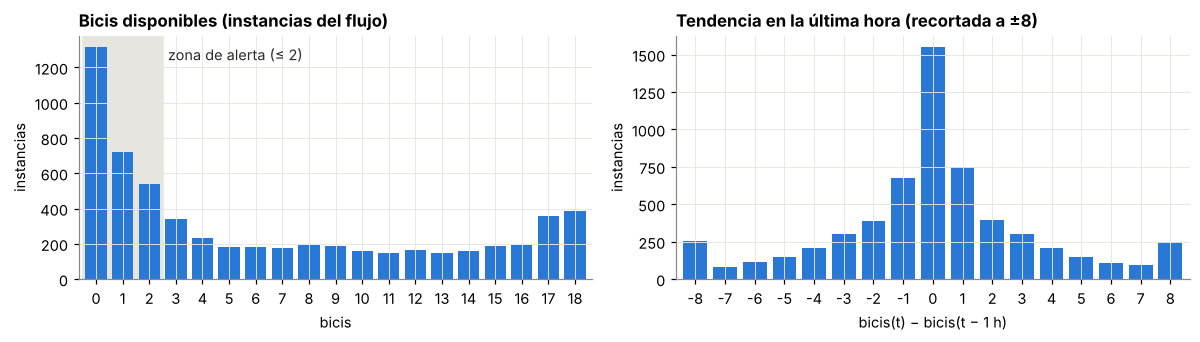

In [20]:
# Distribución de las bicis disponibles y de la tendencia en la última hora
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
f["bicis"].astype(int).value_counts().sort_index().plot.bar(ax=axes[0], color=AZUL, width=0.8)
axes[0].axvspan(-0.5, UMBRAL_POCAS + 0.5, color=SOMBRA, zorder=0)
axes[0].set_title("Bicis disponibles (instancias del flujo)")
axes[0].set_xlabel("bicis"); axes[0].set_ylabel("instancias")
axes[0].text(UMBRAL_POCAS + 0.7, axes[0].get_ylim()[1] * 0.9, "zona de alerta (≤ 2)", color=TINTA)
axes[0].tick_params(axis="x", rotation=0)

f["tendencia_1h"].dropna().clip(-8, 8).astype(int).value_counts().sort_index().plot.bar(ax=axes[1], color=AZUL, width=0.8)
axes[1].set_title("Tendencia en la última hora (recortada a ±8)")
axes[1].set_xlabel("bicis(t) − bicis(t − 1 h)"); axes[1].set_ylabel("instancias")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Qué vemos:** la distribución de las bicis tiene **dos modos**: la estación está muy a menudo vacía o casi (0-2 bicis, la zona de alerta) y muy a menudo llena (17-18 bicis, su capacidad). La tendencia en la última hora suele ser pequeña (la mitad de las veces cambia 1 bici o menos), pero hay cambios bruscos de hasta 17 bicis en una hora: la estación se vacía o se llena en poco tiempo. La temperatura media es de 22 °C y llueve en el 12 % de las instancias.

### 4.2.3 Patrones diarios y semanales: un *drift* recurrente y esperado

Si el uso de la estación depende de la hora y del tipo de día, la distribución de los datos **cambia varias veces al día y vuelve a cambiar el fin de semana**. Es un cambio previsible y recurrente: hay que tenerlo en cuenta para no confundirlo con un drift "de verdad".

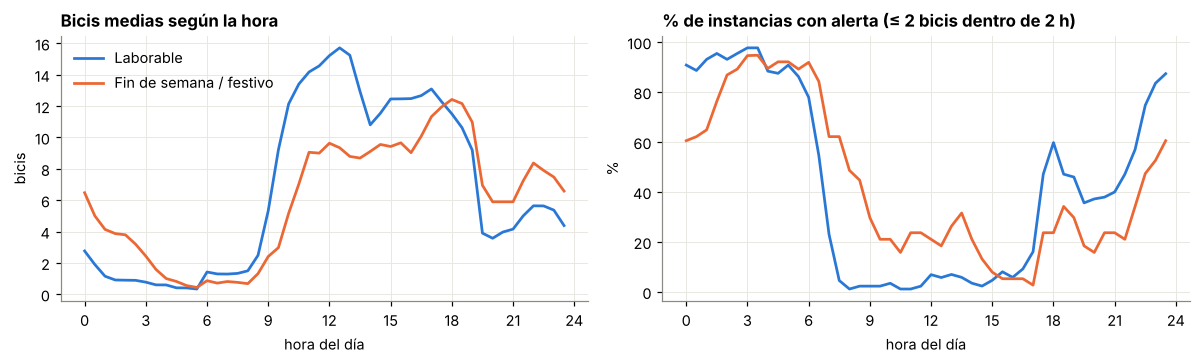

In [21]:
# Ciclo diario: bicis medias y % de alertas por hora, en laborables y en fines de semana
f["tipo_dia"] = np.where((f["es_finde"] == 1) | (f["es_festivo"] == 1), "Fin de semana / festivo", "Laborable")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for tipo, color in [("Laborable", AZUL), ("Fin de semana / festivo", NARANJA)]:
    g = f[f["tipo_dia"] == tipo].groupby("hora")
    axes[0].plot(g["bicis"].mean(), color=color, lw=1.8, label=tipo)
    axes[1].plot(100 * g["pocas_bicis_2h"].mean(), color=color, lw=1.8, label=tipo)
axes[0].set_title("Bicis medias según la hora"); axes[0].set_ylabel("bicis")
axes[1].set_title("% de instancias con alerta (≤ 2 bicis dentro de 2 h)"); axes[1].set_ylabel("%")
for ax in axes:
    ax.set_xlabel("hora del día"); ax.set_xticks(range(0, 25, 3))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [22]:
# Ciclo semanal: bicis medias y % de alertas por día de la semana
por_dia = f.groupby("dia_semana").agg(bicis_media=("bicis", "mean"), pct_alerta=("pocas_bicis_2h", "mean"))
por_dia.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia["pct_alerta"] *= 100
por_dia.round(1).T

,lun,mar,mié,jue,vie,sáb,dom
bicis_media,6.1,6.6,6.5,6.8,7.3,8.0,4.1
pct_alerta,45.3,44.1,44.4,44.9,35.9,34.3,52.1


**Qué vemos:**
- **Ciclo diario muy marcado.** En laborables la estación está casi vacía de 0:00 a 8:00, se llena a partir de las 9:00 (hasta unas 16 bicis de media a las 12:30) y se vacía otra vez a partir de las 19:00. Por eso las alertas superan el 85 % de 23:00 a 6:00, casi desaparecen entre las 7:30 y las 17:00 y vuelven a partir de las 17:30.
- **Fin de semana distinto:** se llena más tarde y menos, y el **domingo** es el día con más alertas (52 %) y menos bicis (4,1 de media).
- Esto es un **cambio recurrente y esperado**: si un detector se aplicara directamente sobre `bicis`, detectaría este ciclo cada día, no un cambio real (hipótesis H3).

### 4.2.4 Evolución a lo largo del periodo: ¿cambia el uso de la estación?

Medimos el **uso** de la estación como el número de bicis que entran o salen al día (la suma de `movimientos_30min`).

In [23]:
# Uso diario de la estación (laborables completos) y su media por mes
uso_diario = f["movimientos_30min"].resample("D").sum()
instancias_dia = f["bicis"].resample("D").count()
dias_completos = instancias_dia[instancias_dia >= 44].index      # al menos 44 de las 48 medias horas
print("Días incompletos que se descartan:", [d.strftime("%d-%m") for d in instancias_dia.index.difference(dias_completos)])
uso_diario = uso_diario[uso_diario.index.isin(dias_completos)]

diario = pd.DataFrame({
    "uso": uso_diario,
    "pct_alerta": 100 * f["pocas_bicis_2h"].resample("D").mean(),
    "bicis_media": f["bicis"].resample("D").mean(),
    "temperatura": f["temperatura"].resample("D").mean(),
}).dropna()
diario["laborable"] = (diario.index.dayofweek < 5) & ~diario.index.isin(FESTIVOS)
print(f"Días completos: {len(diario)}")

mensual = diario[diario["laborable"]].groupby(diario[diario["laborable"]].index.month).mean(numeric_only=True)
mensual.index = ["jun", "jul", "ago", "sep", "oct"][:len(mensual)]
print("Días LABORABLES, media por mes:")
mensual.drop(columns="laborable").round(1)

Días incompletos que se descartan: ['05-08', '15-09', '16-09', '05-10']
Días completos: 123
Días LABORABLES, media por mes:


,uso,pct_alerta,bicis_media,temperatura
jun,234.0,47.6,6.3,21.4
jul,221.6,40.2,7.1,23.0
ago,194.8,33.0,7.7,23.3
sep,232.2,49.6,5.7,21.9
oct,250.5,50.0,6.3,20.6


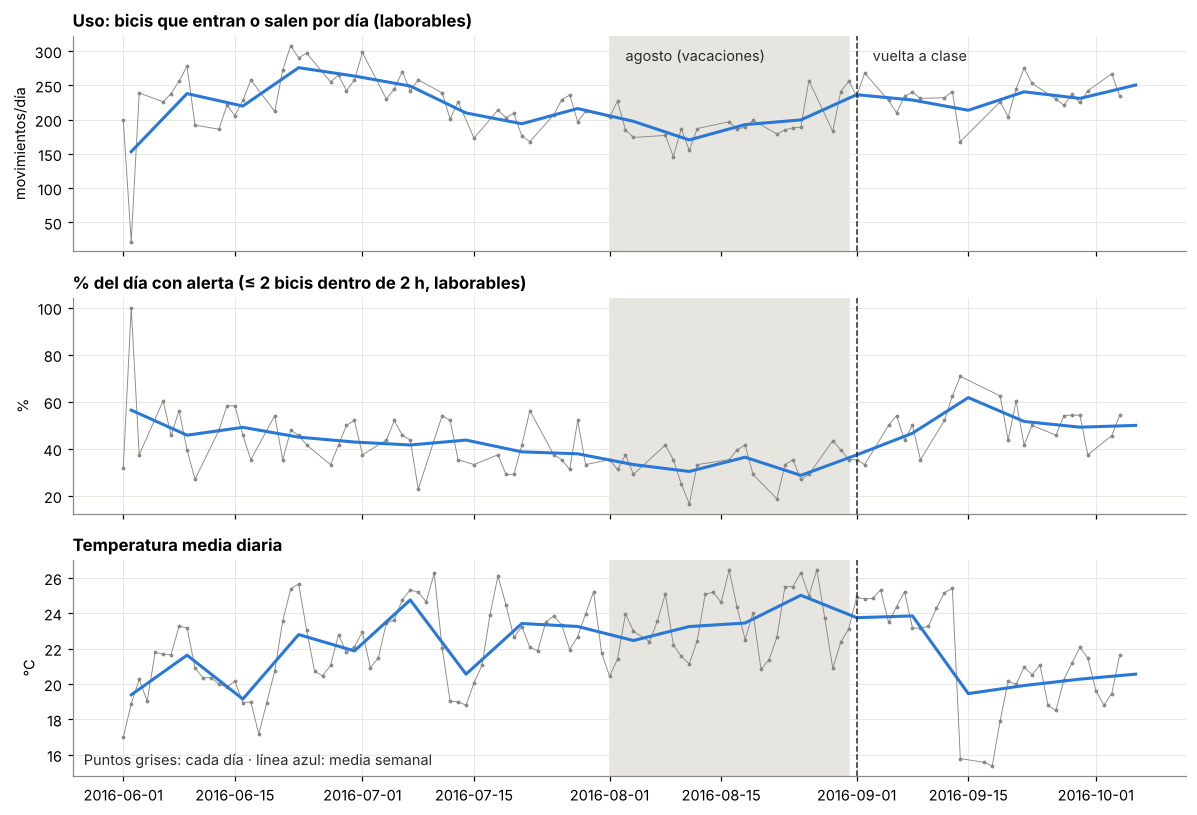

In [24]:
# Media semanal, dibujada en el centro de cada semana (lunes a domingo)
semanal = diario[diario["laborable"]].resample("W-SUN").mean(numeric_only=True)
semanal.index = semanal.index - pd.Timedelta(days=3)
paneles = [("uso", "Uso: bicis que entran o salen por día (laborables)", "movimientos/día"),
           ("pct_alerta", "% del día con alerta (≤ 2 bicis dentro de 2 h, laborables)", "%"),
           ("temperatura", "Temperatura media diaria", "°C")]

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, (col, titulo, unidad) in zip(axes, paneles):
    serie_d = diario[col] if col == "temperatura" else diario.loc[diario["laborable"], col]
    ax.plot(serie_d.index, serie_d, color=GRIS, lw=0.6, marker=".", ms=3)
    if col == "temperatura":
        serie_s = diario[col].resample("W-SUN").mean()
        serie_s.index = serie_s.index - pd.Timedelta(days=3)
    else:
        serie_s = semanal[col]
    ax.plot(serie_s.index, serie_s, color=AZUL, lw=2)
    ax.axvspan(pd.Timestamp("2016-08-01"), pd.Timestamp("2016-08-31"), color=SOMBRA, zorder=0)
    ax.axvline(pd.Timestamp("2016-09-01"), color=TINTA, ls="--", lw=1)
    ax.set_title(titulo); ax.set_ylabel(unidad)
axes[0].text(pd.Timestamp("2016-08-03"), axes[0].get_ylim()[1] * 0.95, "agosto (vacaciones)", va="top", color=TINTA)
axes[0].text(pd.Timestamp("2016-09-03"), axes[0].get_ylim()[1] * 0.95, "vuelta a clase", va="top", color=TINTA)
axes[2].text(0.01, 0.05, "Puntos grises: cada día · línea azul: media semanal", transform=axes[2].transAxes, color=TINTA)
plt.tight_layout(); plt.show()

**Qué vemos:**
- **El uso cambia con las vacaciones** (laborables): 234 movimientos al día en junio, 222 en julio, **195 en agosto** (−17 %) y vuelta a 232 en septiembre. En agosto la estación se queda **menos veces sin bicis** (33 % del día con alerta frente al 48 % de junio) y en septiembre sube al 50 %. Es un candidato a *data drift* (H1) y, si cambia la relación entre variables y etiqueta, a *concept drift* (H2).
- **La temperatura baja de golpe unos 5 °C a mediados de septiembre**, justo cuando suben las alertas por la vuelta a la universidad: habrá que separar los dos efectos (H4).

### 4.2.5 Influencia del tiempo meteorológico

¿Se usan menos bicis cuando llueve? Comparamos el uso por media hora (movimientos de bicis en cada intervalo) con y sin lluvia, separando laborables y fines de semana y en horario diurno (8:00-21:00), para que la hora del día no enmascare el efecto.

In [25]:
# ¿Se usan menos bicis cuando llueve? Movimientos medios por media hora, de 8:00 a 21:00
m = f.rename(columns={"movimientos_30min": "movimientos"})
m = m[(m["hora"] >= 8) & (m["hora"] <= 21)]
tabla_lluvia = m.groupby(["tipo_dia", m["llueve"].map({0: "sin lluvia", 1: "con lluvia"})])["movimientos"].agg(["mean", "size"])
tabla_lluvia.columns = ["movimientos medios por 30 min", "instancias"]
print(f"Instancias con lluvia: {f['llueve'].mean():.1%} del flujo")
tabla_lluvia.round(2)

Instancias con lluvia: 11.6% del flujo


movimientos medios por 30 min  instancias
tipo_dia                llueve                                               
Fin de semana / festivo con lluvia                           4.11         126
                        sin lluvia                           4.92         896
Laborable               con lluvia                           5.93         239
                        sin lluvia                           7.20        2101

**Qué vemos:** con lluvia hay un **18 % menos de movimientos** en laborables (5,9 frente a 7,2 por media hora) y un **16 % menos** en fin de semana. El tiempo influye, pero mucho menos que la hora o el tipo de día.

### 4.2.6 Autocorrelación

Los detectores de drift (KSWIN, ADWIN, DDM…) suponen observaciones **independientes**. Si una variable está muy autocorrelacionada o tiene un ciclo diario, un detector puede confundir el ciclo con un cambio.

In [26]:
# Autocorrelación de las bicis, la temperatura y la etiqueta a distintos retardos
retardos = {"30 min": 1, "1 h": 2, "6 h": 12, "12 h": 24, "1 día": 48, "1 semana": 336}
autocorr = pd.DataFrame({
    var: {nombre: f[var].asfreq(FREQ).autocorr(k) for nombre, k in retardos.items()}
    for var in ["bicis", "temperatura", "pocas_bicis_2h"]
}).round(2)
autocorr.index.name = "retardo"
autocorr

,bicis,temperatura,pocas_bicis_2h
retardo,,,
30 min,0.91,0.96,0.77
1 h,0.81,0.94,0.66
6 h,0.06,0.33,0.01
12 h,-0.39,-0.25,-0.34
1 día,0.55,0.78,0.47
1 semana,0.69,0.56,0.56


**Qué vemos:** las bicis están muy correlacionadas con su valor de hace 30 minutos (0,91) y de hace 1 hora (0,81): el estado actual dice mucho del futuro cercano, así que **la persistencia será un *baseline* difícil de batir**. La correlación a 1 día (0,55) y a 1 semana (0,69) confirma el ciclo diario y semanal. Para los detectores es un problema: suponen observaciones **independientes**, y aquí no lo son.

### 4.2.7 Resumen del exploratorio e hipótesis de drift

#### ¿Está bien construido el flujo?

Sí, con matices que hay que tener en cuenta:
- **5.980 instancias, una cada 30 minutos**, del 1 de junio al 5 de octubre de 2016, en orden estricto y sin duplicados. La etiqueta coincide en el 100 % de los casos con las bicis de 2 horas después, así que **no hay fugas del futuro**.
- **27 saltos** en el flujo: los intervalos sin lecturas por cortes del recolector y las instancias que se quedan sin etiqueta porque no hay datos 2 horas después. El mayor es del 15 al 16 de septiembre (~27 h); los demás son de 30-60 minutos. No se rellenan: el flujo simplemente salta, igual que en un sistema real cuando se cae la fuente.
- **Clases equilibradas:** el 43 % de las instancias son alerta (2 bicis o menos dentro de 2 horas).
- **Anomalías:** el **2 de junio** la estación marca 0 bicis todo el día (probablemente fuera de servicio) y la **temperatura tiene 59 picos aislados** de más de 3 °C que vuelven al valor anterior en la siguiente media hora (errores de la fuente meteorológica). Hay que recordarlo al aplicar detectores sobre la temperatura: un detector sensible, como Page-Hinkley, puede reaccionar a estos picos.
- La estación tiene capacidad para unas **18 bicis**: además de vaciarse, a menudo se llena (17-18 bicis), lo que también limita su uso.

#### Qué patrones tiene el flujo

- **Ciclo diario muy marcado (drift recurrente).** En laborables la estación está casi vacía de 0:00 a 8:00, se llena a partir de las 9:00 (hasta ~16 bicis de media a las 12:30) y se vacía otra vez a partir de las 19:00. Por eso las alertas (que miran 2 horas adelante) están por encima del 85 % de 23:00 a 6:00, casi desaparecen entre las 7:30 y las 17:00 y vuelven a partir de las 17:30. En fin de semana se llena más tarde y menos, y el **domingo** es el día con más alertas (52 %). La autocorrelación de las bicis es 0,55 a un día y 0,69 a una semana. **Un detector aplicado directamente sobre `bicis` detectaría este ciclo, no un cambio real.**
- **Cambio de uso en vacaciones y a la vuelta (laborables):**

| Mes | Movimientos/día | % del día con alerta | Bicis medias |
|---|---|---|---|
| Junio | 234 | 48 % | 6,3 |
| Julio | 222 | 40 % | 7,1 |
| Agosto | 195 (−17 % frente a junio) | 33 % | 7,7 |
| Septiembre | 232 | 50 % | 5,7 |

En agosto se usa menos la estación y **se queda menos veces sin bicis**; en septiembre el uso vuelve al nivel de junio y las alertas suben del 33 % al 50 %. (Octubre solo tiene 3 días laborables completos y no se usa para conclusiones.)
- **El tiempo influye, pero menos:** con lluvia hay un 18 % menos de movimientos en laborables y un 16 % menos en fin de semana. A mediados de septiembre la temperatura baja ~5 °C de golpe, justo cuando suben las alertas: habrá que separar ambos efectos.

#### Hipótesis de drift que vamos a comprobar

| | Hipótesis | Señal que se vigila | Métodos | Para qué |
|---|---|---|---|---|
| **H1** | ***Data drift*** **en el uso** al empezar agosto (vacaciones) y al volver en septiembre | uso y nivel de bicis, quitando antes el ciclo diario y semanal | ADWIN, KSWIN, Page-Hinkley | Avisar de un cambio de comportamiento **sin esperar a las etiquetas** |
| **H2** | ***Concept drift*** **en septiembre**: a la misma hora y el mismo día, cambia la probabilidad de quedarse sin bicis | error del modelo (acierto/fallo) | DDM, EDDM, HDDM_A, HDDM_W, Page-Hinkley, ADWIN | Saber **cuándo el modelo de alerta deja de ser fiable** y hay que adaptarlo |
| **H3** | El **ciclo diario y semanal** es un drift recurrente y esperado: no debería disparar alarmas | `bicis` tal cual frente a desestacionalizada | ADWIN, KSWIN, Page-Hinkley | Justificar que hay que quitar la estacionalidad antes de vigilar una variable |
| **H4** | La **bajada de temperatura** de mediados de septiembre es *data drift* en la meteorología, que no tiene por qué afectar al modelo | temperatura (media diaria, para evitar los picos) | ADWIN, KSWIN | Contrastar *data drift* y *concept drift*: un cambio en los datos no siempre obliga a reentrenar |

#### Implicaciones para la modelización

- El estado actual (`bicis`, `tendencia_1h`) y el calendario (`hora`, `dia_semana`) son las variables clave. **Hay que comparar siempre con el *baseline* de persistencia** ("si ahora hay 2 o menos, dentro de 2 horas también"): la autocorrelación de las bicis es alta (0,81 a 1 hora), así que no será fácil de batir.
- La evaluación será **prequential** (predecir, evaluar y después aprender) sobre este flujo, sin usar nunca información futura y **teniendo en cuenta que la etiqueta llega 2 horas tarde**.

#### Lectura del flujo para los modelos

Los modelos recorren el CSV con `flujo_bicis()` (apartado 4.1.6), sin esperas entre instancias (`delay=0`), porque el flujo se recorre muchas veces: una por modelo y experimento. La etiqueta de cada instante se conoce 2 horas después (`HORIZONTE`).

In [27]:
# Constantes del problema y primera instancia del flujo tal como la recibe el modelo
HORIZONTE = pd.Timedelta("2h")      # la etiqueta de t se conoce en t + 2 h
COLUMNAS_X = ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
              "temperatura", "humedad", "viento", "nubes", "llueve", "movimientos_30min"]
x, y = next(flujo_bicis())
print(x, "->", y)

{'momento': datetime.datetime(2016, 6, 1, 0, 30), 'bicis': 3.0, 'hora': 0.5, 'dia_semana': 2.0, 'es_finde': 0.0, 'es_festivo': 0.0, 'temperatura': 17.36, 'humedad': 77.0, 'viento': 9.8, 'nubes': 90.0, 'llueve': 0.0, 'movimientos_30min': 2.0} -> True


## 4.3 Estrategia de aprendizaje y evaluación

### 4.3.1 Evaluación *prequential* con retraso de la etiqueta

En un flujo de datos no hay partición train/test: el modelo **predice cada instancia antes de aprender de ella** (*test-then-train* o evaluación *prequential*), como en los cuadernos del tema (`predict_one` → `learn_one` → `detector.update`).

Pero en nuestro problema hay un detalle importante: **la etiqueta llega 2 horas tarde**. A las 10:00 el sistema predice si a las 12:00 habrá 2 bicis o menos, y solo a las 12:00 sabe si ha acertado. Si aprendiéramos de la etiqueta en el mismo instante en que predecimos, estaríamos usando información del futuro y los resultados serían optimistas.

Por eso el bucle de evaluación funciona así cada vez que llega una instancia *x(t)*:
1. **Llegan las etiquetas** de las predicciones hechas hace 2 horas (o más): se comprueba si se acertó, se actualizan las métricas y **los detectores de drift**, y el modelo aprende de esas instancias.
2. **Se predice** *x(t)* y la predicción queda pendiente hasta *t* + 2 h.

Las detecciones de drift se fechan en el momento en que el sistema puede verlas (cuando llega la etiqueta), no en el de la predicción.

In [28]:
# Bucle prequential con la etiqueta retrasada (lo usan todos los experimentos del subsistema 1)
def variables_modelo(x):
    """Variables que recibe el modelo: todas menos el momento, más la hora en forma cíclica (23:30 está cerca de 0:00)."""
    xm = {k: v for k, v in x.items() if k != "momento"}
    xm["hora_sin"] = math.sin(2 * math.pi * x["hora"] / 24)
    xm["hora_cos"] = math.cos(2 * math.pi * x["hora"] / 24)
    return xm


def prequential(modelo, instancias, retraso=HORIZONTE, detectores=None, congelar_desde=None):
    """Evaluación test-then-train con la etiqueta retrasada `retraso`.
    detectores: dict nombre -> detector de River, que recibe el bit de error (1 = fallo).
    congelar_desde: a partir de esa fecha el modelo deja de aprender (para el experimento del apartado 4.5).
    Devuelve (registro por instancia, fechas de detección por detector)."""
    retraso = pd.Timedelta(retraso)
    detectores = detectores or {}
    pendientes = collections.deque()
    registros, detecciones = [], {nombre: [] for nombre in detectores}
    for x, y in instancias:
        t = x["momento"]
        # 1) Llegan las etiquetas de las predicciones hechas hace `retraso`
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, y0, p0, error))
            for nombre, det in detectores.items():
                det.update(error)
                if det.drift_detected:
                    detecciones[nombre].append(t)
            if congelar_desde is None or t < congelar_desde:
                modelo.learn_one(x0, y0)
        # 2) Llega x(t): se predice y queda pendiente
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "y", "y_pred", "error"]).set_index("momento")
    return registro, detecciones


def resumen(registro):
    acc, f1 = metrics.Accuracy(), metrics.F1()
    for y, p in zip(registro["y"], registro["y_pred"]):
        acc.update(y, p)
        f1.update(y, p)
    return {"accuracy_%": round(100 * acc.get(), 1), "F1_alerta_%": round(100 * f1.get(), 1)}

**Qué devuelve `prequential`:** un registro con una fila por predicción evaluada (momento de la predicción, momento en que llegó la etiqueta, etiqueta real, predicción y bit de error) y, si se le pasan detectores, las fechas en que detectó drift cada uno. Todo lo que sigue (accuracy por meses, gráficas semanales, detectores) se calcula a partir de este registro.

#### Comprobación con `evaluate.progressive_val_score`

River ya trae la evaluación *prequential*: `evaluate.progressive_val_score` (la de `EvaluacionProgressiveValScore.ipynb`). Con `delay > 0` hace la **validación progresiva retardada**: cada predicción queda pendiente y la etiqueta se revela `delay` después, momento en que se actualiza la métrica y el modelo aprende. Para que el retraso sea de 2 horas *de reloj* (y no de un número de instancias), se le indica la columna de tiempo con `moment="momento"`.

Comprobamos que nuestro bucle `prequential` da **el mismo resultado** que la función de River con un Hoeffding Tree. El bucle propio es necesario porque, además de medir, tiene que **actualizar los detectores de drift con cada bit de error**, **congelar el modelo** en una fecha (apartado 4.5) y **guardar cada predicción** para calcular el error por meses y semanas; `progressive_val_score` solo devuelve la métrica final.

In [29]:
# Comprobación: la misma evaluación con la función de River evaluate.progressive_val_score
def flujo_para_river():
    """Mismo flujo, con las variables del modelo y el momento (que el modelo descarta)."""
    for x, y in flujo_bicis():
        xm = variables_modelo(x)
        xm["momento"] = x["momento"]
        yield xm, y


acc_river = metrics.Accuracy()
evaluate.progressive_val_score(
    dataset=flujo_para_river(),
    model=compose.Discard("momento") | tree.HoeffdingTreeClassifier(),   # el momento no es una variable del modelo
    metric=acc_river,
    moment="momento",          # columna de tiempo del flujo
    delay=HORIZONTE,           # la etiqueta se revela 2 horas después (validación progresiva retardada)
    print_every=1000,
)

reg_ht, _ = prequential(tree.HoeffdingTreeClassifier(), flujo_bicis())
print(f"\nprogressive_val_score                     : {100 * acc_river.get():.2f} % ({int(acc_river.cm.total_weight)} predicciones)")
print(f"Bucle prequential                         : {100 * (1 - reg_ht['error'].mean()):.2f} % ({len(reg_ht)} predicciones)")
print(f"Bucle sin las 4 primeras (modelo sin datos): {100 * (1 - reg_ht['error'].iloc[4:].mean()):.2f} % ({len(reg_ht) - 4} predicciones)")

[1,000] Accuracy: 78.01%


[2,000] Accuracy: 78.06%


[3,000] Accuracy: 78.70%


[4,000] Accuracy: 79.38%


[5,000] Accuracy: 80.16%


[5,980] Accuracy: 80.32%



progressive_val_score                     : 80.32 % (5976 predicciones)
Bucle prequential                         : 80.25 % (5976 predicciones)
Bucle sin las 4 primeras (modelo sin datos): 80.31 % (5972 predicciones)


**Los dos métodos coinciden.** La pequeña diferencia se debe solo a dos convenciones en los extremos del flujo:
- **Al principio:** durante las 2 primeras horas el modelo aún no ha recibido ninguna etiqueta y no predice nada (`None`). River no cuenta esas 4 predicciones; nuestro bucle las cuenta como "sin alerta". Si las quitamos, la diferencia baja a una centésima.
- **Al final:** al terminar el CSV, River revela las etiquetas de las 4 últimas predicciones; nuestro bucle no, porque en la realidad aún no habrían llegado.

### 4.3.2 *Baselines*

Un modelo solo tiene sentido si mejora lo que se consigue sin aprender nada:
- **Clase mayoritaria:** predice siempre la clase más frecuente vista hasta el momento.
- **Persistencia:** "si ahora hay 2 bicis o menos, dentro de 2 horas también". Es el *baseline* natural en series temporales y aquí es muy exigente, porque el estado de la estación cambia despacio.

In [30]:
# Baselines sin aprendizaje, con la misma interfaz que un modelo de River (predict_one / learn_one)
class ClaseMayoritaria:
    def __init__(self):
        self.conteo = collections.Counter()
    def predict_one(self, x):
        return self.conteo.most_common(1)[0][0] if self.conteo else False
    def learn_one(self, x, y):
        self.conteo[y] += 1


class Persistencia:
    def predict_one(self, x):
        return x["bicis"] <= UMBRAL_POCAS
    def learn_one(self, x, y):
        pass

### 4.3.3 ¿Por qué un horizonte de 2 horas?

Comparamos la persistencia con un modelo online (`ARFClassifier`, ver 4.4) para distintos horizontes de predicción. Las etiquetas de cada horizonte se calculan a partir de la columna `bicis` del flujo, y en cada caso la etiqueta llega con el retraso de su horizonte.

In [31]:
# Experimento: persistencia frente a ARF para horizontes de 30 min a 3 h
base = pd.read_csv(CSV_FLUJO, parse_dates=["momento"]).set_index("momento")


def instancias_con_horizonte(horizonte):
    futuro = base["bicis"].reindex(base.index + pd.Timedelta(horizonte)).to_numpy()
    tabla = base.assign(y=futuro <= UMBRAL_POCAS)[~np.isnan(futuro)]
    for t, fila in tabla.iterrows():
        x = {k: fila[k] for k in COLUMNAS_X if pd.notna(fila[k])}
        x["momento"] = t
        yield x, bool(fila["y"])


filas = []
for h in ["30min", "1h", "2h", "3h"]:
    fila = {"horizonte": h}
    for nombre, fab in {"Persistencia": Persistencia,
                        "ARF": lambda: forest.ARFClassifier(n_models=10, seed=42)}.items():
        registro, _ = prequential(fab(), instancias_con_horizonte(h), retraso=h)
        fila[f"{nombre} accuracy_%"] = resumen(registro)["accuracy_%"]
    fila["mejora ARF (puntos)"] = round(fila["ARF accuracy_%"] - fila["Persistencia accuracy_%"], 1)
    filas.append(fila)
pd.DataFrame(filas).set_index("horizonte")

,Persistencia accuracy_%,ARF accuracy_%,mejora ARF (puntos)
horizonte,,,
30min,88.6,88.1,-0.5
1h,83.1,85.2,2.1
2h,75.3,82.3,7.0
3h,69.4,80.8,11.4


**Conclusión.** A 30 minutos el modelo no supera a la persistencia (−0,5 puntos): el estado actual casi determina el futuro y no hay nada que aprender. Al alargar el horizonte, la persistencia pierde fuerza (del 88,6 % al 69,4 %) y el modelo aporta cada vez más: +7 puntos a 2 horas y +11,4 a 3 horas.

Elegimos **2 horas**: el modelo aporta claramente y es un margen útil para avisar a los usuarios o reponer bicis. A 3 horas el modelo aportaría más, pero la etiqueta tardaría más en llegar y el sistema reaccionaría más tarde a los cambios.

### 4.3.4 Efecto del retraso de la etiqueta

Mismo modelo y mismo horizonte (2 h), evaluado de dos formas: aprendiendo de la etiqueta en el mismo instante en que predice (**incorrecto**: usa el futuro) y aprendiendo cuando la etiqueta llega de verdad, 2 horas después.

In [32]:
# Experimento: el mismo ARF evaluado sin retraso (incorrecto) y con el retraso real de 2 h
filas = {}
for nombre, retraso in [("Sin retraso (optimista, incorrecto)", "0min"), ("Retraso de 2 h (realista)", "2h")]:
    registro, _ = prequential(forest.ARFClassifier(n_models=10, seed=42), flujo_bicis(), retraso=retraso)
    filas[nombre] = resumen(registro)
pd.DataFrame(filas).T

,accuracy_%,F1_alerta_%
"Sin retraso (optimista, incorrecto)",84.4,81.3
Retraso de 2 h (realista),82.6,79.1


**Conclusión.** Ignorar el retraso infla la accuracy en 1,8 puntos (84,4 % frente a 82,6 %) y el F1 en 2,2. Todos los resultados que siguen usan el retraso realista de 2 horas.

El retraso también afecta a los detectores de *concept drift*: como el error se conoce 2 horas tarde, **cualquier detección llega como mínimo 2 horas después del cambio**.

### 4.3.5 Métricas y evaluación de los detectores

**Métricas del modelo:**
- **Accuracy** prequential: % de aciertos.
- **F1 de la clase alerta**: la alerta es la clase que interesa y está algo desequilibrada (43 %).
- **Accuracy semanal**: para ver la evolución en el tiempo y si el modelo se degrada.

**¿Cómo se evalúa un detector de drift si no sabemos dónde está el drift real?** En los cuadernos del tema se usan flujos sintéticos con el cambio en una posición conocida. En un flujo real no existe esa verdad, así que:
1. Se comparan las detecciones con **eventos conocidos** del calendario de Toulouse en 2016: inicio de las vacaciones escolares de verano (**6 de julio**), festivos (**14 de julio** y **15 de agosto**), vuelta a clase en los colegios (**1 de septiembre**) y en la universidad (mediados de septiembre), y la bajada de temperatura del **14 de septiembre** (apartado 4.2).
2. Se cuentan las **alarmas por mes**: un detector que salta continuamente no sirve para tomar decisiones.
3. Se comprueba si una alarma de *concept drift* va acompañada de una **subida real del error** (si el error no sube, es una falsa alarma).
4. Se ignoran las detecciones de las **2 primeras semanas**, mientras el modelo aún está aprendiendo y su error baja.

In [33]:
# Fechas de evaluación, eventos del calendario y función para dibujar señales y detecciones
INICIO_EVALUACION = pd.Timestamp("2016-06-15")     # 2 semanas de aprendizaje inicial
VACACIONES = (pd.Timestamp("2016-07-06"), pd.Timestamp("2016-08-31"))
EVENTOS = {"6 jul: vacaciones": "2016-07-06", "14 jul: festivo": "2016-07-14", "15 ago: festivo": "2016-08-15",
           "1 sep: vuelta a clase": "2016-09-01", "14 sep: baja la temperatura": "2016-09-14"}
EVENTOS = {k: pd.Timestamp(v) for k, v in EVENTOS.items()}


def dibujar_detecciones(senal, detecciones, titulo, ylabel, desde=None):
    """Arriba la señal vigilada; abajo una fila por detector con sus detecciones ( | )."""
    nombres = list(detecciones)
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 2.8 + 0.32 * len(nombres)),
                                 gridspec_kw={"height_ratios": [2.4, 0.32 * len(nombres) + 0.3], "hspace": 0.08})
    a1.plot(senal.index, senal.values, color=AZUL, lw=1.4)
    for ax in (a1, a2):
        ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
        for nombre, fecha in EVENTOS.items():
            ax.axvline(fecha, color=GRIS, ls=":", lw=1)
        if desde is not None:
            ax.axvspan(senal.index.min(), desde, color="#f4f3ef", lw=0, zorder=0)
    a1.text(VACACIONES[0] + pd.Timedelta(days=1), a1.get_ylim()[1], "vacaciones escolares", va="top", color=TINTA, fontsize=8.5)
    for j, nombre in enumerate(nombres):
        fechas = [d for d in detecciones[nombre] if desde is None or d >= desde]
        a2.scatter(fechas, [j] * len(fechas), marker="|", s=180, lw=2, color=TINTA)
    a2.set_yticks(range(len(nombres)))
    a2.set_yticklabels([f"{n} ({len([d for d in detecciones[n] if desde is None or d >= desde])})" for n in nombres])
    a2.set_ylim(len(nombres) - 0.5, -0.5)
    a2.grid(axis="y", visible=False)
    a1.set_title(titulo)
    a1.set_ylabel(ylabel)
    plt.show()

## 4.4 Elección razonada del modelo de alerta

No vamos a probar todos los clasificadores del tema para quedarnos con el que mejor salga. Partimos de lo que sabemos del problema (apartados 4.1 a 4.3), deducimos qué modelo debería funcionar mejor y lo comprobamos frente a los *baselines* y frente a las alternativas que ponen a prueba cada parte del razonamiento.

**Qué exige el problema:**

| Característica del problema (dónde se ve) | Qué exige al modelo |
|---|---|
| La probabilidad de quedarse sin bicis depende de **interacciones**: la misma hora significa cosas distintas en laborable y en fin de semana, y con 3 bicis que con 15 (apartado 4.2.3) | capturar relaciones **no lineales** con interacciones entre variables |
| El uso cambia con las vacaciones y la vuelta a clase (4.2.4), así que puede haber *concept drift* | **adaptarse** a los cambios sin intervención |
| Hay ruido: días de lluvia, festivos, anomalías de los sensores (4.2.1) | **estabilidad**: que una racha rara no cambie mucho el modelo |
| La alerta es una decisión con costes (una alerta de más frente a usuarios sin bici, apartado 4.9) | dar **probabilidades**, no solo la clase, para poder ajustar el umbral |
| Llega una instancia cada 30 minutos | el tiempo por instancia **no es una restricción** (la memoria sí, si se quisiera un modelo por estación en toda la red) |

**Candidato: el *Adaptive Random Forest* (ARF) [8].** Cumple los cinco requisitos. Sus árboles de Hoeffding capturan las interacciones; al combinar 10 árboles entrenados con muestras y variables distintas, los errores de unos compensan los de otros (estabilidad); cada árbol tiene un detector ADWIN que lo sustituye si empeora (adaptación); la votación da una probabilidad; y su coste es asumible con una instancia cada 30 minutos.

**Cómo lo comprobamos.** Además de los dos *baselines* (clase mayoritaria y persistencia, apartado 4.3.2), lo enfrentamos solo a los modelos que ponen a prueba cada parte del razonamiento:
- **Hoeffding Tree** (un solo árbol, que no se adapta): si el ARF no lo supera, el ensemble y la adaptación no aportan y bastaría con el árbol, que es más simple, más interpretable y ocupa mucho menos.
- **Regresión logística** (lineal, con la hora en forma de seno y coseno): si iguala a los árboles, las interacciones no eran tan importantes y bastaría con un modelo lineal.
- Como el ARF es aleatorio, el resultado se repite con **10 semillas**.

**Modelos del tema que descartamos de entrada:** Gaussian Naive Bayes, porque supone variables independientes y aquí `bicis`, `tendencia_1h` y la hora están muy relacionadas; el perceptrón, porque no da probabilidades. El Hoeffding Adaptive Tree y el EFDT, árboles que se adaptan sin ser ensembles, se usan en el apartado 4.7, donde lo que se compara son precisamente las formas de adaptarse a un cambio.

**Cómo funcionan los tres modelos:**
- **Hoeffding Tree** [5]: árbol de decisión que crece mientras llegan los datos. Cada hoja acumula estadísticas de las instancias que le llegan y, cada `grace_period` instancias (200), compara los dos mejores atributos para dividirla. Solo divide si la diferencia de ganancia de información entre el mejor y el segundo supera la **cota de Hoeffding** ε = √(*R*² ln(1/δ) / 2*n*): con *n* instancias vistas, la probabilidad de equivocarse al elegir el atributo es como mucho δ. Así decide con seguridad sin ver todos los datos. No se adapta al drift: lo que divide, lo deja dividido.
- **ARF** [8]: 10 árboles de Hoeffding entrenados con *online bagging* (cada instancia se usa en cada árbol un número aleatorio de veces, según una Poisson) y con un subconjunto aleatorio de variables en cada división, lo que hace que los árboles se equivoquen en sitios distintos y sus errores se compensen. Cada árbol tiene un detector ADWIN de *warning* (empieza a entrenar un árbol de reserva) y otro de *drift* (lo sustituye por el de reserva). Predice por votación, lo que da también una probabilidad. Usamos los 10 árboles por defecto: con una instancia cada 30 minutos el coste no obliga a menos.
- **Regresión logística**: modelo lineal que ajusta un peso por variable con cada instancia (descenso por gradiente). Necesita variables en la misma escala, por eso va detrás de un `StandardScaler` online. Recibe la hora como seno y coseno, que es lo máximo que puede hacer un modelo lineal con un ciclo.

**Cómo leer la tabla:** `accuracy_%` y `F1_alerta_%` sobre todo el flujo (el F1 mide lo bien que se detecta la clase alerta); `jun`…`oct`, la *accuracy* de cada mes, para ver si el modelo se degrada; `segundos` y `ms/instancia`, el coste de procesar el flujo; `memoria (KB)`, lo que ocupa el modelo al final.

In [34]:
# Comprobación de la hipótesis: ARF frente a Hoeffding Tree, regresión logística y baselines (accuracy, F1, accuracy mensual, tiempo y memoria)
MODELOS = {
    "Clase mayoritaria": ClaseMayoritaria,
    "Persistencia": Persistencia,
    "Hoeffding Tree": lambda: tree.HoeffdingTreeClassifier(),
    "ARF (10 árboles)": lambda: forest.ARFClassifier(n_models=10, seed=42),
    "Regresión logística": lambda: preprocessing.StandardScaler() | linear_model.LogisticRegression(),
}

def memoria_kb(modelo):
    """Memoria que ocupa el modelo de River al final del flujo (los baselines propios no la miden)."""
    return round(modelo._raw_memory_usage / 1024, 1) if hasattr(modelo, "_raw_memory_usage") else np.nan


registros, filas = {}, {}
for nombre, fab in MODELOS.items():
    t0 = time.time()
    modelo = fab()
    registros[nombre], _ = prequential(modelo, flujo_bicis())
    r = registros[nombre]
    filas[nombre] = {**resumen(r),
                     **{f"acc_{m}": round(100 * (1 - e.mean()), 1)
                        for m, e in r["error"].groupby(r.index.month)},
                     "segundos": round(time.time() - t0, 1),
                     "ms/instancia": round(1000 * (time.time() - t0) / len(r), 2),
                     "memoria (KB)": memoria_kb(modelo)}
tabla_modelos = pd.DataFrame(filas).T
tabla_modelos.columns = [c.replace("acc_6", "jun").replace("acc_7", "jul").replace("acc_8", "ago")
                         .replace("acc_9", "sep").replace("acc_10", "oct") for c in tabla_modelos.columns]
tabla_modelos

,accuracy_%,F1_alerta_%,jun,jul,ago,sep,oct,segundos,ms/instancia,memoria (KB)
Clase mayoritaria,56.0,13.2,50.1,60.1,64.1,50.1,49.8,0.8,0.13,NaN
Persistencia,75.3,71.3,75.7,73.5,75.6,75.8,80.1,0.7,0.12,NaN
Hoeffding Tree,80.3,75.0,78.7,78.6,82.5,80.4,86.1,1.4,0.23,291.2
ARF (10 árboles),82.6,79.1,80.0,80.9,85.1,83.9,87.1,12.2,2.05,24779.5
Regresión logística,80.0,77.2,78.3,78.2,80.5,82.8,81.6,1.2,0.20,5.0


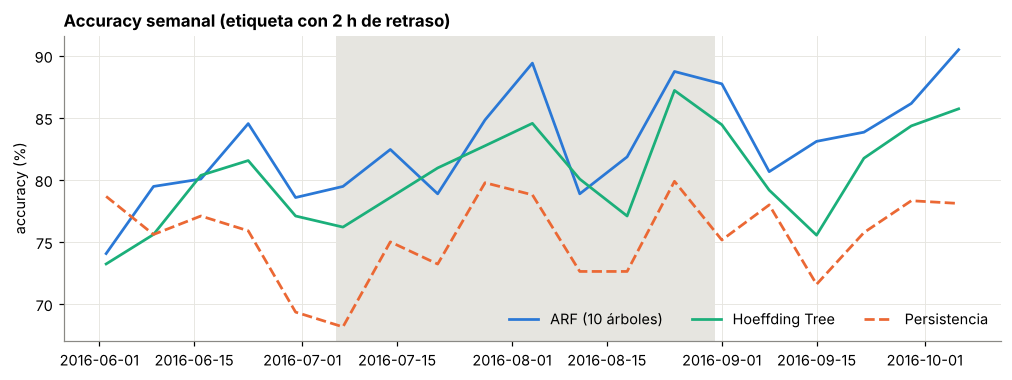

In [35]:
# Accuracy semanal del ARF, el Hoeffding Tree y la persistencia
fig, ax = plt.subplots(figsize=(11, 3.6))
for nombre, color, ls in [("ARF (10 árboles)", AZUL, "-"), ("Hoeffding Tree", VERDE, "-"), ("Persistencia", NARANJA, "--")]:
    acc_sem = 100 * (1 - registros[nombre]["error"].resample("W-SUN").mean())
    acc_sem.index = acc_sem.index - pd.Timedelta(days=3)
    ax.plot(acc_sem.index, acc_sem.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
ax.set_title("Accuracy semanal (etiqueta con 2 h de retraso)")
ax.set_ylabel("accuracy (%)")
ax.legend(frameon=False, ncol=3, loc="lower right")
plt.show()

**Robustez.** El ARF toma decisiones aleatorias (qué variables mira cada árbol, cuándo sustituye un árbol). Con otra semilla, u otro ordenador, el resultado cambia un poco. Para no sacar conclusiones de una sola ejecución, repetimos el ARF con **10 semillas** (unos 90 segundos). Estas 10 ejecuciones se reutilizan en el apartado 4.5.

In [36]:
# Robustez: el ARF con 10 semillas distintas
SEMILLAS = range(1, 11)
t0 = time.time()
reg_semillas = {s: prequential(forest.ARFClassifier(n_models=10, seed=s), flujo_bicis())[0] for s in SEMILLAS}
acc_semillas = pd.Series({s: 100 * (1 - r["error"].mean()) for s, r in reg_semillas.items()})
f1_semillas = pd.Series({s: resumen(r)["F1_alerta_%"] for s, r in reg_semillas.items()})
print(f"ARF con {len(SEMILLAS)} semillas ({time.time() - t0:.0f} s):")
print(f"  accuracy: media {acc_semillas.mean():.1f} %, desv. típica {acc_semillas.std():.1f}, de {acc_semillas.min():.1f} a {acc_semillas.max():.1f}")
print(f"  F1 alerta: media {f1_semillas.mean():.1f} %, de {f1_semillas.min():.1f} a {f1_semillas.max():.1f}")

ARF con 10 semillas (113 s):
  accuracy: media 82.2 %, desv. típica 0.3, de 81.8 a 82.6
  F1 alerta: media 78.8 %, de 78.4 a 79.3


**Conclusión: se confirma la hipótesis. El ARF es el mejor modelo y cada parte del razonamiento se sostiene.**
- **ARF: 82,6 % de *accuracy* y 79,1 % de F1, 7,3 puntos por encima de la persistencia** y mejor que ella todos los meses. Con 10 semillas obtiene un 82,2 % de media (de 81,8 % a 82,6 %) y un 78,8 % de F1: el resultado es estable.
- **¿Aporta el ensemble? Sí.** El Hoeffding Tree se queda en el 80,3 %: el ARF le saca 2,3 puntos y es mejor **todos los meses** (de 1 a 3,5 puntos). Un solo árbol no revisa sus divisiones y es sensible al ruido; combinar 10 árboles distintos lo compensa.
- **¿Hacen falta las no linealidades? Sí, pero un árbol solo no basta para aprovecharlas.** La regresión logística (80,0 %) casi iguala al Hoeffding Tree, porque la hora en seno y coseno ya recoge buena parte del ciclo diario, pero queda 2,6 puntos por debajo del ARF.
- **Coste:** con una instancia cada 30 minutos el tiempo no importa (el ARF tarda unos 2 ms por instancia). La **memoria** sí marca diferencias: al final del flujo el ARF ocupa unos **24 MB**, frente a 0,3 MB del Hoeffding Tree y 5 KB de la regresión logística. Para una estación es irrelevante, pero un ARF por estación en toda la red de Toulouse (del orden de 280 estaciones) necesitaría unos 7 GB, frente a unos 80 MB con Hoeffding Trees. Es el precio de los 2 puntos que el ARF saca al árbol.
- La *accuracy* semanal oscila entre el 75 % y el 90 %, sin tendencia a empeorar.

**Elegimos el ARF** como modelo del sistema de alerta para el resto del proyecto.

## 4.5 *Concept drift* en el flujo real (H2): ¿deja de ser fiable el modelo?

**Para qué:** en producción, un detector de *concept drift* vigila el error del modelo y avisa cuando el modelo deja de acertar como antes, para reentrenarlo o sustituirlo. Su entrada es el **bit de error** (1 = fallo, 0 = acierto) de cada predicción, que se conoce 2 horas después.

Se aplican los 6 detectores del tema (`river.drift`) con sus parámetros por defecto:
- **Binarios** (`drift.binary`: DDM, EDDM, HDDM_A, HDDM_W): esperan un flujo de 0 y 1 y tienen **zona de *warning*** antes del drift.
- **No binarios aplicados al error** (Page-Hinkley y ADWIN), sin zona de *warning*. A Page-Hinkley se le pone `mode="up"`: solo interesa que el error **suba**.

#### Cómo funciona cada detector

Todos reciben, una a una, las observaciones de una señal (aquí, el bit de error *e<sub>t</sub>* ∈ {0, 1}) y en cada paso dicen si hay *warning* (posible cambio) o *drift* (cambio confirmado):

| Detector | Qué vigila | Cuándo salta | Parámetros por defecto en River |
|---|---|---|---|
| **DDM** [9] | La tasa de error *p<sub>t</sub>* y su desviación típica *s<sub>t</sub>* = √(*p<sub>t</sub>*(1 − *p<sub>t</sub>*)/*t*). Guarda el mínimo histórico *p<sub>min</sub>* + *s<sub>min</sub>* | *Warning* si *p<sub>t</sub>* + *s<sub>t</sub>* ≥ *p<sub>min</sub>* + 2·*s<sub>min</sub>*; *drift* si ≥ *p<sub>min</sub>* + 3·*s<sub>min</sub>* | `warm_start=30`, `warning_threshold=2`, `drift_threshold=3` |
| **EDDM** [10] | La **distancia entre dos errores consecutivos** (cuántas instancias pasan entre fallos), su media *p'* y su desviación *s'*. Si los errores se acercan, el modelo empeora | *Warning* si (*p'* + 2*s'*)/(*p'<sub>max</sub>* + 2*s'<sub>max</sub>*) < α; *drift* si < β. Pensado para cambios graduales | `alpha=0.95`, `beta=0.9` |
| **HDDM_A** [11] | La media del error, comparando la media hasta un punto de corte con la media reciente mediante la **desigualdad de Hoeffding** (la misma cota de los árboles de Hoeffding) | Cuando la diferencia de medias supera la cota para la confianza fijada | `drift_confidence=0.001`, `warning_confidence=0.005` |
| **HDDM_W** [11] | Igual que HDDM_A, pero con una **media ponderada exponencialmente** (los errores recientes pesan más) | Igual que HDDM_A; reacciona antes a cambios recientes | además, `lambda_val=0.05` (peso de lo reciente) |
| **Page-Hinkley** [12] | La suma acumulada de las desviaciones respecto a la media: *m<sub>T</sub>* = Σ (*x<sub>t</sub>* − *x̄<sub>T</sub>* − δ) | Cuando *m<sub>T</sub>* − min(*m<sub>t</sub>*) > λ (el umbral). No tiene *warning* | `delta=0.005`, `threshold=50`, `min_instances=30` |
| **ADWIN** [13] | Una **ventana de tamaño variable** con las últimas observaciones. Prueba todos los cortes en dos subventanas | Cuando las medias de las dos subventanas difieren más de lo que permite la cota estadística (que depende de δ): descarta la parte antigua. No tiene *warning* | `delta=0.002` |

Los cuatro primeros son **binarios** (esperan 0 y 1); Page-Hinkley y ADWIN sirven para cualquier variable numérica, por eso se usan también para *data drift* en el apartado 4.6.

### 4.5.1 Una ejecución de ejemplo (semilla 42), como en los cuadernos del tema

Primero se ejecuta el ARF y se guarda su flujo de errores **en el orden en que se conocen** (2 horas después de cada predicción). Después, cada detector recorre ese flujo con el mismo bucle que `DeteccionDrift_DDM.ipynb`: se actualiza con el bit de error y se imprime cuándo entra en zona de *warning* (solo la primera vez de cada zona, como con `en_warning` en los cuadernos) y cuándo detecta drift. No se cuentan las 2 primeras semanas (aprendizaje inicial).

In [37]:
# Flujo de errores del ARF (semilla 42), en el orden en que se conocen las etiquetas
reg_arf, _ = prequential(forest.ARFClassifier(n_models=10, seed=42), flujo_bicis())
errores = list(zip(reg_arf["revelada"], reg_arf["error"]))
print(f"{len(errores)} predicciones evaluadas · error medio {100 * reg_arf['error'].mean():.1f} %")


def vigilar(detector, nombre, errores, desde=INICIO_EVALUACION, imprimir=True):
    """Bucle de los cuadernos del tema: el detector se actualiza con cada bit de error
    (1 = fallo, 0 = acierto) y se anota cuándo entra en zona de warning y cuándo detecta drift."""
    en_warning = False                 # control para no repetir el mismo warning
    avisos, drifts = [], []
    for i, (t, error) in enumerate(errores, start=1):
        # Se utiliza si la predicción ha sido o no correcta para actualizar el detector
        detector.update(error)
        if t < desde:                  # aprendizaje inicial: no se cuenta
            continue
        # Si se detecta drift, se imprime por pantalla
        if detector.drift_detected:
            drifts.append(t)
            if imprimir:
                print(f"i = {i:>5} ({t:%d-%m %H:%M}) --> Drift detectado ({nombre}).")
            en_warning = False
        # Si se entra en zona de warning, se imprime por pantalla (solo los detectores binarios la tienen)
        elif getattr(detector, "warning_detected", False):
            if not en_warning:
                avisos.append(t)
                if imprimir:
                    print(f"i = {i:>5} ({t:%d-%m %H:%M}) --> Warning detectado ({nombre}).")
                en_warning = True
        else:
            en_warning = False
    if imprimir:
        print(f"Total {nombre}: {len(avisos)} zonas de warning y {len(drifts)} drifts")
    return avisos, drifts

5976 predicciones evaluadas · error medio 17.4 %


In [38]:
# DDM: detector de drift a utilizar (por defecto: warm_start=30, warning_threshold=2, drift_threshold=3)
ddm = drift.binary.DDM()
res_ddm = vigilar(ddm, "DDM", errores)

i =   911 (20-06 01:30) --> Warning detectado (DDM).
i =  3622 (15-08 16:00) --> Warning detectado (DDM).
i =  3631 (15-08 20:30) --> Warning detectado (DDM).
i =  3636 (15-08 23:00) --> Warning detectado (DDM).
i =  3638 (16-08 00:00) --> Warning detectado (DDM).
i =  3655 (16-08 08:30) --> Warning detectado (DDM).
Total DDM: 6 zonas de warning y 0 drifts


In [39]:
# EDDM: detector de drift a utilizar (por defecto: warm_start=30, alpha=0.95, beta=0.9)
eddm = drift.binary.EDDM()
res_eddm = vigilar(eddm, "EDDM", errores)

i =   760 (16-06 22:00) --> Warning detectado (EDDM).
i =   764 (17-06 00:00) --> Drift detectado (EDDM).
i =   890 (19-06 15:00) --> Drift detectado (EDDM).
i =  1096 (23-06 22:00) --> Drift detectado (EDDM).
i =  1250 (27-06 03:00) --> Drift detectado (EDDM).
i =  1430 (30-06 21:00) --> Drift detectado (EDDM).
i =  1554 (03-07 11:00) --> Drift detectado (EDDM).
i =  1737 (07-07 06:30) --> Warning detectado (EDDM).
i =  1774 (08-07 01:00) --> Drift detectado (EDDM).
i =  1899 (10-07 15:30) --> Drift detectado (EDDM).
i =  2060 (14-07 00:00) --> Drift detectado (EDDM).
i =  2232 (17-07 14:00) --> Drift detectado (EDDM).
i =  2366 (20-07 09:00) --> Drift detectado (EDDM).
i =  2512 (23-07 10:00) --> Drift detectado (EDDM).
i =  2680 (26-07 22:00) --> Drift detectado (EDDM).
i =  2909 (31-07 16:30) --> Warning detectado (EDDM).
i =  2930 (01-08 03:00) --> Warning detectado (EDDM).
i =  2968 (01-08 22:00) --> Warning detectado (EDDM).
i =  2987 (02-08 07:30) --> Drift detectado (EDDM).
i 

In [40]:
# HDDM_A: detector de drift a utilizar (por defecto: drift_confidence=0.001, warning_confidence=0.005)
# En River 0.26 la clase se llama HDDMA (no HDDM_A)
hddm_a = drift.binary.HDDMA()
res_hddm_a = vigilar(hddm_a, "HDDM_A", errores)

i =   761 (16-06 22:30) --> Warning detectado (HDDM_A).
i =   763 (16-06 23:30) --> Warning detectado (HDDM_A).
i =   765 (17-06 00:30) --> Drift detectado (HDDM_A).
i =   820 (18-06 04:00) --> Warning detectado (HDDM_A).
i =   822 (18-06 05:00) --> Warning detectado (HDDM_A).
i =   884 (19-06 12:00) --> Warning detectado (HDDM_A).
i =   886 (19-06 13:00) --> Drift detectado (HDDM_A).
i =   999 (21-06 21:30) --> Warning detectado (HDDM_A).
i =  1224 (26-06 14:00) --> Warning detectado (HDDM_A).
i =  1256 (27-06 06:00) --> Warning detectado (HDDM_A).
i =  1260 (27-06 08:00) --> Warning detectado (HDDM_A).
i =  1433 (30-06 22:30) --> Warning detectado (HDDM_A).
i =  1434 (30-06 23:00) --> Drift detectado (HDDM_A).
i =  1528 (02-07 22:00) --> Warning detectado (HDDM_A).
i =  1529 (02-07 22:30) --> Drift detectado (HDDM_A).
i =  1826 (09-07 03:00) --> Warning detectado (HDDM_A).
i =  1827 (09-07 03:30) --> Drift detectado (HDDM_A).
i =  2355 (20-07 03:30) --> Warning detectado (HDDM_A).
i 

In [41]:
# HDDM_W: detector de drift a utilizar (por defecto: drift_confidence=0.001, warning_confidence=0.005, lambda_val=0.05)
# En River 0.26 la clase se llama HDDMW (no HDDM_W)
hddm_w = drift.binary.HDDMW()
res_hddm_w = vigilar(hddm_w, "HDDM_W", errores)

i =   819 (18-06 03:30) --> Warning detectado (HDDM_W).
i =   822 (18-06 05:00) --> Drift detectado (HDDM_W).
i =  1224 (26-06 14:00) --> Warning detectado (HDDM_W).
i =  1253 (27-06 04:30) --> Warning detectado (HDDM_W).
i =  1256 (27-06 06:00) --> Warning detectado (HDDM_W).
i =  1435 (30-06 23:30) --> Warning detectado (HDDM_W).
i =  1531 (02-07 23:30) --> Warning detectado (HDDM_W).
i =  1558 (03-07 13:00) --> Warning detectado (HDDM_W).
i =  1563 (03-07 15:30) --> Drift detectado (HDDM_W).
i =  1673 (05-07 22:30) --> Warning detectado (HDDM_W).
i =  1675 (05-07 23:30) --> Warning detectado (HDDM_W).
i =  1900 (10-07 16:00) --> Warning detectado (HDDM_W).
i =  1907 (10-07 19:30) --> Warning detectado (HDDM_W).
i =  1919 (11-07 01:30) --> Warning detectado (HDDM_W).
i =  2233 (17-07 14:30) --> Warning detectado (HDDM_W).
i =  2235 (17-07 15:30) --> Drift detectado (HDDM_W).
i =  2597 (25-07 04:30) --> Warning detectado (HDDM_W).
i =  3413 (11-08 07:30) --> Warning detectado (HDDM_W)

In [42]:
# Page-Hinkley: solo subidas del error (mode="up"); resto por defecto: min_instances=30, delta=0.005, threshold=50
ph = drift.PageHinkley(mode="up")
res_ph = vigilar(ph, "Page-Hinkley", errores)

Total Page-Hinkley: 0 zonas de warning y 0 drifts


In [43]:
# ADWIN: por defecto (delta=0.002)
adwin = drift.ADWIN()
res_adwin = vigilar(adwin, "ADWIN", errores)

i =  4480 (02-09 18:00) --> Drift detectado (ADWIN).
Total ADWIN: 0 zonas de warning y 1 drifts


In [44]:
# Resumen de los 6 detectores en la ejecución de ejemplo
resultados_42 = {"DDM": res_ddm, "EDDM": res_eddm, "HDDM_A": res_hddm_a, "HDDM_W": res_hddm_w,
                 "Page-Hinkley": res_ph, "ADWIN": res_adwin}
tabla_42 = pd.DataFrame({n: {"zonas de warning": len(w), "drifts": len(d),
                             "fechas de los drifts": ", ".join(x.strftime("%d-%m") for x in d) or "—"}
                         for n, (w, d) in resultados_42.items()}).T
tabla_42

,zonas de warning,drifts,fechas de los drifts
DDM,6,0,—
EDDM,15,22,"17-06, 19-06, 23-06, 27-06, 30-06, 03-07, 08-07, 10-07, 14-07, 17-07, 20-07, 23-07, 26-07, 02-08, 08-08, 13-08, 15-08, 21-08, 27-08, 02-09, 06-09, 11-09"
HDDM_A,23,10,"17-06, 19-06, 30-06, 02-07, 09-07, 20-07, 11-08, 13-08, 14-08, 21-08"
HDDM_W,24,6,"18-06, 03-07, 17-07, 14-08, 11-09, 25-09"
Page-Hinkley,0,0,—
ADWIN,0,1,02-09


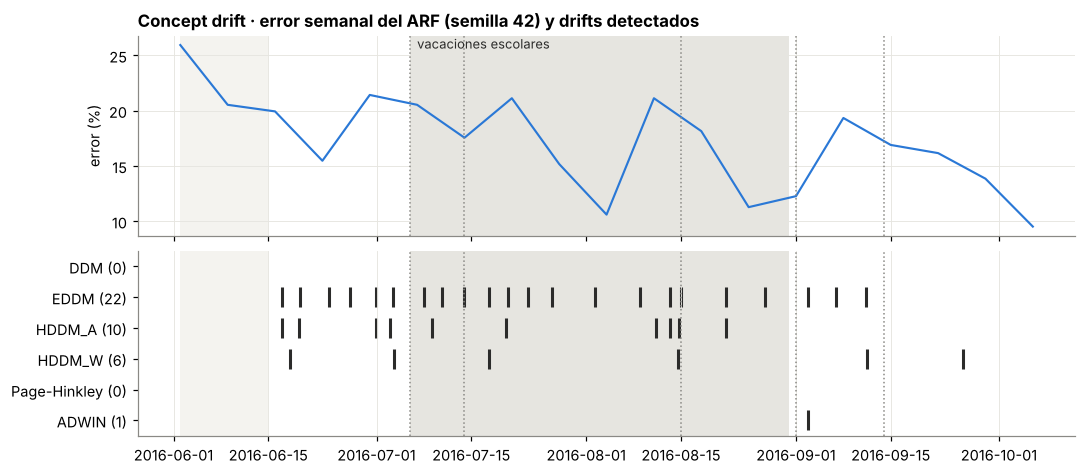

In [45]:
# Error semanal del ARF y detecciones de cada detector
error_semanal = reg_arf["error"].resample("W-SUN").mean()
error_semanal.index = error_semanal.index - pd.Timedelta(days=3)
dibujar_detecciones(100 * error_semanal, {n: d for n, (w, d) in resultados_42.items()},
                    "Concept drift · error semanal del ARF (semilla 42) y drifts detectados", "error (%)", desde=INICIO_EVALUACION)

**Cómo leer estas detecciones.** Que un detector "detecte drift" no significa que haya *concept drift*: significa que su estadístico ha superado un umbral. Un detector es una **alarma**, y una alarma puede ser falsa. Dos indicios de que aquí casi todas lo son:
- EDDM y HDDM_A ya saltan el **17 y el 19 de junio**, antes de cualquier evento del calendario, y después siguen saltando cada pocos días: con un error medio del 17 % que sube y baja de forma natural (días de lluvia, festivos, fines de semana), los detectores sensibles confunden esas oscilaciones con cambios.
- Los detectores no se ponen de acuerdo: con el mismo flujo de errores, EDDM da 22 drifts, HDDM_A 10, HDDM_W 6, ADWIN 1, y DDM y Page-Hinkley ninguno. Si hubiera un cambio claro, la mayoría coincidirían en la fecha (como ocurre en el apartado 4.7, con un cambio real).

Para decidir si hay *concept drift* de verdad no basta con contar alarmas: hay que **comprobar si el modelo empeora realmente** (apartado 4.5.3) y **repetir con varias semillas** (apartado 4.5.2).

### 4.5.2 ¿Son robustas estas detecciones? 10 semillas

Las detecciones dependen mucho de la ejecución: con otra semilla del ARF, u otro ordenador, salen otras fechas. Repetimos el análisis con las 10 ejecuciones del apartado 4.4 y medimos, para cada detector, cuántos drifts da y en qué porcentaje de ejecuciones salta cerca de cada evento del calendario.

In [46]:
# Los 6 detectores sobre los errores de las 10 ejecuciones del ARF
FABRICAS = {"DDM": drift.binary.DDM, "EDDM": drift.binary.EDDM, "HDDM_A": drift.binary.HDDMA,
            "HDDM_W": drift.binary.HDDMW, "Page-Hinkley": lambda: drift.PageHinkley(mode="up"), "ADWIN": drift.ADWIN}
VENTANAS = {"inicio de vacaciones (6-20 jul)": ("2016-07-06", "2016-07-21"),
            "agosto (1-15 ago)": ("2016-08-01", "2016-08-16"),
            "vuelta a clase (29 ago-12 sep)": ("2016-08-29", "2016-09-13")}

filas = []
for s, reg in reg_semillas.items():
    errs = list(zip(reg["revelada"], reg["error"]))
    for nombre, fab in FABRICAS.items():
        avisos, drifts = vigilar(fab(), nombre, errs, imprimir=False)
        fila = {"semilla": s, "detector": nombre, "warnings": len(avisos), "drifts": len(drifts)}
        for v, (a, b) in VENTANAS.items():
            fila[v] = any(pd.Timestamp(a) <= d < pd.Timestamp(b) for d in drifts)
        filas.append(fila)
rob = pd.DataFrame(filas)

g = rob.groupby("detector", sort=False)
tabla_rob = pd.DataFrame({
    "drifts (media)": g["drifts"].mean(),
    "drifts (mín.-máx.)": g["drifts"].agg(lambda x: f"{x.min()}-{x.max()}"),
    "warnings (media)": g["warnings"].mean(),
    **{f"% ejecuciones con drift: {v}": 100 * g[v].mean() for v in VENTANAS},
}).round(1)
tabla_rob

,drifts (media),drifts (mín.-máx.),warnings (media),% ejecuciones con drift: inicio de vacaciones (6-20 jul),% ejecuciones con drift: agosto (1-15 ago),% ejecuciones con drift: vuelta a clase (29 ago-12 sep)
detector,,,,,,
DDM,1.5,0-9,19.1,20.0,0.0,0.0
EDDM,23.2,0-28,14.5,90.0,90.0,90.0
HDDM_A,10.6,3-18,27.4,50.0,90.0,80.0
HDDM_W,7.6,5-10,20.7,90.0,100.0,70.0
Page-Hinkley,0.0,0-0,0.0,0.0,0.0,0.0
ADWIN,0.6,0-1,0.0,0.0,0.0,40.0


**Cómo leer la tabla:** para cada detector, el número medio de drifts por ejecución (y el mínimo y el máximo entre las 10), cuántas zonas de *warning* da, y en qué porcentaje de las 10 ejecuciones salta cerca de cada evento del calendario. Un detector que salta cerca de **todos** los eventos no los está detectando: está saltando continuamente.

### 4.5.3 ¿Hay *concept drift* de verdad? Modelo congelado, 10 semillas

Las detecciones por sí solas no demuestran que haya *concept drift*. Experimento directo: un **modelo congelado** que aprende hasta el 1 de agosto y después deja de aprender (sigue prediciendo con lo aprendido en junio y julio). Si la relación entre las variables y la etiqueta cambia en agosto o en septiembre, **el modelo congelado empeorará** respecto al que sigue aprendiendo. Se repite con las 10 semillas (unos 90 segundos).

In [47]:
# Experimento: ARF que sigue aprendiendo frente a ARF congelado el 1 de agosto (10 semillas)
CONGELAR = pd.Timestamp("2016-08-01")
t0 = time.time()
reg_congelado_semillas = {s: prequential(forest.ARFClassifier(n_models=10, seed=s), flujo_bicis(), congelar_desde=CONGELAR)[0]
                          for s in SEMILLAS}
print(f"{time.time() - t0:.0f} s")

error_mes = lambda reg: 100 * reg["error"].groupby(reg.index.month).mean()
online = pd.DataFrame({s: error_mes(r) for s, r in reg_semillas.items()})
congelado = pd.DataFrame({s: error_mes(r) for s, r in reg_congelado_semillas.items()})
diferencia = congelado - online
comparacion = pd.DataFrame({
    "error online (%, media)": online.mean(axis=1),
    "error congelado (%, media)": congelado.mean(axis=1),
    "diferencia (puntos, media)": diferencia.mean(axis=1),
    "diferencia (desv. típica)": diferencia.std(axis=1),
    "semillas en que el congelado es peor": (diferencia > 0).sum(axis=1).astype(str) + f" de {len(SEMILLAS)}",
}).round(1)
comparacion.index = ["jun", "jul", "ago", "sep", "oct"][:len(comparacion)]
comparacion

62 s


,"error online (%, media)","error congelado (%, media)","diferencia (puntos, media)",diferencia (desv. típica),semillas en que el congelado es peor
jun,20.4,20.4,0.0,0.0,0 de 10
jul,19.3,19.3,0.0,0.0,0 de 10
ago,15.4,16.6,1.2,0.8,10 de 10
sep,16.8,17.0,0.2,0.8,6 de 10
oct,12.9,13.6,0.6,1.7,4 de 10


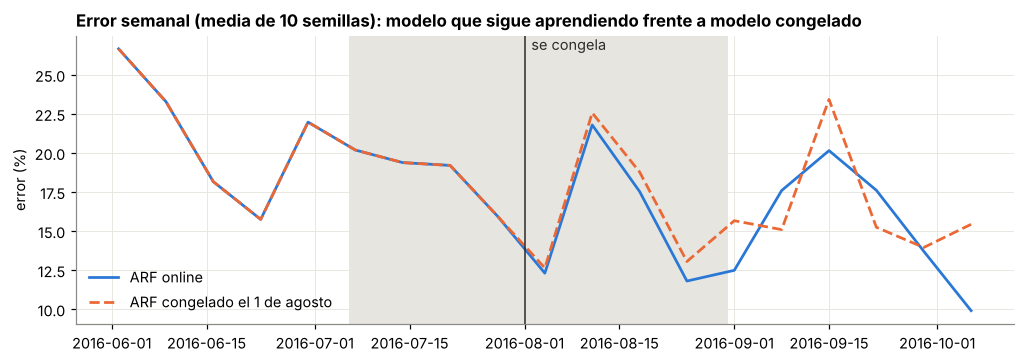

In [48]:
# Error semanal medio del modelo online y del congelado
def error_semanal_medio(registros):
    semanas = pd.DataFrame({s: r["error"].resample("W-SUN").mean() for s, r in registros.items()})
    semanas.index = semanas.index - pd.Timedelta(days=3)
    return 100 * semanas.mean(axis=1)

fig, ax = plt.subplots(figsize=(11, 3.4))
for regs, nombre, color, ls in [(reg_semillas, "ARF online", AZUL, "-"),
                                (reg_congelado_semillas, "ARF congelado el 1 de agosto", NARANJA, "--")]:
    e = error_semanal_medio(regs)
    ax.plot(e.index, e.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvline(CONGELAR, color=TINTA, lw=1)
ax.text(CONGELAR + pd.Timedelta(days=1), ax.get_ylim()[1], "se congela", va="top", color=TINTA)
ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
ax.set_title("Error semanal (media de 10 semillas): modelo que sigue aprendiendo frente a modelo congelado")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, loc="lower left")
plt.show()

**Conclusión (H2): los detectores dan muchas alarmas, pero solo hay un *concept drift* real, muy leve, en agosto, y ningún detector lo detecta de forma fiable.**

La aparente contradicción entre las muchas detecciones del apartado 4.5.1 y esta conclusión se resuelve separando **alarma** de ***concept drift* real**: el modelo congelado mide directamente si la relación entre las variables y la etiqueta ha cambiado, y las detecciones solo cuentan si coinciden con ese cambio.

- **Modelo congelado:** en agosto falla 1,2 puntos más que el online, y eso pasa **en las 10 semillas**: con las vacaciones cambia un poco la relación entre las variables y la etiqueta. En septiembre la diferencia es de solo 0,2 puntos (el congelado es peor en 6 de 10 semillas), así que **no hay evidencia de *concept drift* con la vuelta a clase**. El ARF online absorbe el cambio en todos los casos.
- **DDM y Page-Hinkley** prácticamente no saltan (DDM da 1,5 drifts de media, casi todos en el aprendizaje inicial; Page-Hinkley ninguno): con un cambio tan pequeño no acumulan evidencia suficiente.
- **EDDM (23 drifts de media), HDDM_A (11) y HDDM_W (8) saltan cada pocos días**, igual que sus zonas de *warning* (15-27 por ejecución). Por eso aparecen "cerca" de cualquier evento en el 70-100 % de las ejecuciones: no es que detecten los eventos, es que saltan continuamente. Son falsas alarmas.
- **ADWIN** da 0 o 1 drift por ejecución. Cuando salta, en 4 de cada 10 ejecuciones lo hace en la vuelta a clase, un cambio que el modelo congelado no confirma, y nunca detecta el de agosto, que es el único confirmado.
- **La ejecución de ejemplo (semilla 42) es engañosa:** en ella ADWIN salta el 2 de septiembre y parece detectar la vuelta a clase, pero eso solo ocurre en 4 de 10 semillas. **Con una sola ejecución se pueden sacar conclusiones erróneas sobre los detectores.**
- **Para qué sirve aquí:** en este flujo basta con el aprendizaje online (el ARF ya lleva un ADWIN dentro de cada árbol). Un detector externo que dispare reentrenamientos no aporta y, con EDDM o HDDM, provocaría reentrenamientos innecesarios. Para evaluar los detectores y las estrategias de adaptación hace falta un drift claro y conocido: apartado 4.7.

## 4.6 *Data drift* en el flujo real (H1, H3 y H4): ¿cambian los datos que llegan?

**Para qué:** los detectores de *data drift* vigilan las variables de entrada **sin necesitar etiquetas**, así que pueden avisar antes que los de *concept drift* (que esperan 2 horas a la etiqueta) y señalan **qué variable** ha cambiado. Su limitación: no dicen si el cambio afecta al modelo.

Detectores del tema para una variable numérica:
- **ADWIN**: ventana adaptativa; detecta cambios en la **media**.
- **KSWIN**: test de Kolmogorov-Smirnov entre una ventana reciente y otra de referencia; detecta cambios en la **distribución** completa.
- **Page-Hinkley**: suma acumulada de desviaciones respecto a la media; detecta cambios de **media** rápido, pero su umbral depende de la escala de la variable.

**KSWIN en detalle** (es el que mejor funciona en este apartado): guarda una ventana con las últimas `window_size` observaciones; compara las `stat_size` más recientes con una muestra de las anteriores mediante el **test de Kolmogorov-Smirnov**, que mide la máxima distancia entre sus dos distribuciones acumuladas. Si esa distancia supera el valor crítico para el nivel de significación `alpha`, hay *drift*. Al comparar distribuciones completas, detecta también cambios de forma o de dispersión, no solo de media.

**Por qué no basta con aplicarlos sobre las variables tal cual:** los tres suponen observaciones **independientes**, y nuestras variables tienen un ciclo diario muy fuerte y mucha autocorrelación (apartados 4.2.3 y 4.2.6). Por eso primero se desestacionalizan (4.6.1) y después se agregan por día (4.6.3).

### 4.6.1 Desestacionalización online

El exploratorio mostró un ciclo diario y semanal muy marcado (H3). Para no confundirlo con un cambio real, a cada valor le restamos la **media de su misma franja horaria y tipo de día** (laborable o fin de semana/festivo), calculada **solo con los datos que ya han llegado** (`river.stats.Mean` por franja). El resultado es una **anomalía**: cuánto se aparta el valor de lo normal para ese momento.

Todo se calcula en **una sola pasada** por el flujo.

In [49]:
# Desestacionalización online: anomalía = valor − media de su franja (hora y tipo de día) hasta ese momento
MIN_OBS = 4      # observaciones de una franja antes de empezar a calcular su anomalía

medias = collections.defaultdict(stats.Mean)
filas = []
for x, y in flujo_bicis():
    t = x["momento"]
    tipo = "finde" if x["es_finde"] or x["es_festivo"] else "laborable"
    franja = (t.hour * 2 + t.minute // 30, tipo)
    fila = {"momento": t, "temperatura": x["temperatura"]}
    for var in ["bicis", "movimientos_30min"]:
        m = medias[(var, franja)]
        fila[var] = x[var]
        fila[f"{var}_anomalia"] = x[var] - m.get() if m.n >= MIN_OBS else np.nan
        m.update(x[var])
    filas.append(fila)
senales = pd.DataFrame(filas).set_index("momento")

print("Desviación típica y autocorrelación a 30 min:")
pd.DataFrame({c: {"desv. típica": senales[c].std(), "autocorrelación (30 min)": senales[c].autocorr(1)}
              for c in ["bicis", "bicis_anomalia", "movimientos_30min", "movimientos_30min_anomalia"]}).round(2).T

Desviación típica y autocorrelación a 30 min:


,desv. típica,autocorrelación (30 min)
bicis,6.38,0.91
bicis_anomalia,4.13,0.81
movimientos_30min,4.14,0.64
movimientos_30min_anomalia,2.80,0.24


In [50]:
# Función auxiliar: pasa una serie por un detector y devuelve las fechas de detección
def ejecutar(detector, serie):
    """Pasa una serie por un detector y devuelve las fechas en que detecta drift."""
    fechas = []
    for t, v in serie.dropna().items():
        detector.update(float(v))
        if detector.drift_detected:
            fechas.append(t)
    return fechas


def detectores_datos():
    return {"ADWIN": drift.ADWIN(), "KSWIN": drift.KSWIN(seed=42), "Page-Hinkley": drift.PageHinkley()}

### 4.6.2 H3: ¿salta el detector con el ciclo diario?

Aplicamos los tres detectores, con sus parámetros por defecto, a las señales de 30 minutos: tal cual y desestacionalizadas.

In [51]:
# H3: detectores con parámetros por defecto sobre las señales de 30 minutos, tal cual y desestacionalizadas
meses = (senales.index.max() - senales.index.min()).days / 30.4
filas = {}
for col, etiqueta in [("bicis", "bicis tal cual"), ("bicis_anomalia", "bicis desestacionalizada"),
                      ("movimientos_30min", "uso tal cual"), ("movimientos_30min_anomalia", "uso desestacionalizado"),
                      ("temperatura", "temperatura tal cual")]:
    filas[etiqueta] = {nombre: round(len(ejecutar(det, senales[col])) / meses, 1) for nombre, det in detectores_datos().items()}
tabla_h3 = pd.DataFrame(filas).T
tabla_h3.columns = [f"{c} (alarmas/mes)" for c in tabla_h3.columns]
tabla_h3

,ADWIN (alarmas/mes),KSWIN (alarmas/mes),Page-Hinkley (alarmas/mes)
bicis tal cual,10.1,12.8,45.1
bicis desestacionalizada,8.9,11.6,30.4
uso tal cual,2.2,12.3,39.3
uso desestacionalizado,1.9,8.0,14.2
temperatura tal cual,11.8,13.5,40.3


**Conclusión (H3): confirmada.** Sobre las señales de 30 minutos tal cual, los detectores saltan continuamente: con las bicis, ADWIN da ~10 alarmas al mes, KSWIN ~13 y Page-Hinkley ~45, y con la temperatura pasa lo mismo. Lo que detectan es el **ciclo diario**, un drift recurrente y esperado, no un cambio real.

Desestacionalizar ayuda (en el uso, Page-Hinkley baja de 39 a 14 alarmas al mes y KSWIN de 12 a 8), pero no basta con las bicis, porque su anomalía sigue muy autocorrelacionada (0,81): un día con más o menos bicis de lo normal da 48 instancias seguidas por encima o por debajo, y ADWIN y KSWIN suponen observaciones independientes.

**Lección:** antes de vigilar una variable real hay que quitarle la estacionalidad y pensar a qué escala temporal ocurren los cambios que buscamos.

### 4.6.3 H1 y H4: señales diarias

Con una instancia cada 30 minutos, la anomalía sigue muy autocorrelacionada (un día raro da 48 instancias raras seguidas). Los cambios que buscamos (vacaciones, vuelta a clase, bajada de temperatura) son de **días o semanas**, así que agregamos por día: al final de cada día llega al detector **un valor** (sigue siendo un flujo, ahora diario).
- **H1:** anomalía media diaria del **uso** (`movimientos_30min` desestacionalizado).
- **H4:** **temperatura media diaria** (la media diaria también elimina los picos falsos de temperatura del apartado 4.2).

Solo se usan los días completos (al menos 44 de las 48 medias horas).

In [52]:
# H1 y H4: señales diarias (anomalía media del uso y temperatura media) y detectores por defecto
completos = senales["bicis"].resample("D").count() >= 44
diarias = pd.DataFrame({
    "uso_anomalia": senales["movimientos_30min_anomalia"].resample("D").mean(),
    "temperatura": senales["temperatura"].resample("D").mean(),
})[completos].dropna()
print(f"Días: {len(diarias)}")
print("Anomalía media del uso por mes (movimientos por 30 min respecto a lo normal para la franja):")
print(diarias["uso_anomalia"].groupby(diarias.index.month).mean().round(2).rename({6: "jun", 7: "jul", 8: "ago", 9: "sep", 10: "oct"}).to_dict())

filas = {}
for col, etiqueta in [("uso_anomalia", "H1 · uso (anomalía diaria)"), ("temperatura", "H4 · temperatura media diaria")]:
    for nombre, det in {"ADWIN": drift.ADWIN(), "KSWIN": drift.KSWIN(seed=42),
                        "KSWIN (ventana 30, reciente 7)": drift.KSWIN(window_size=30, stat_size=7, seed=42),
                        "Page-Hinkley": drift.PageHinkley()}.items():
        filas[(etiqueta, nombre)] = ", ".join(d.strftime("%d-%m") for d in ejecutar(det, diarias[col])) or "—"
pd.Series(filas, name="fechas de detección").to_frame()

Días: 115
Anomalía media del uso por mes (movimientos por 30 min respecto a lo normal para la franja):
{'jun': 0.56, 'jul': -0.3, 'ago': -0.57, 'sep': 0.34, 'oct': 0.43}


fechas de detección
H1 · uso (anomalía diaria)    ADWIN                                            —
                              KSWIN                                        26-09
                              KSWIN (ventana 30, reciente 7)               05-09
                              Page-Hinkley                                     —
H4 · temperatura media diaria ADWIN                                            —
                              KSWIN                                            —
                              KSWIN (ventana 30, reciente 7)        10-07, 23-09
                              Page-Hinkley                          14-08, 26-09

**Conclusión.** Con los parámetros por defecto, los detectores casi no ven nada en las señales diarias. ADWIN y Page-Hinkley no detectan ningún cambio en el uso, aunque la anomalía media pasa de +0,56 en junio a −0,57 en agosto y vuelve a +0,34 en septiembre. Solo KSWIN con una ventana más corta (30 días, 7 recientes) detecta la **vuelta a clase (5 de septiembre)** en el uso y la **bajada de temperatura (23 de septiembre)**.

Los parámetros por defecto no encajan con un flujo de ~115 instancias: se ajustan a continuación.

### 4.6.4 H4: ¿afecta la bajada de temperatura al modelo?

Comparamos el error del ARF (media de las 10 semillas) en las dos semanas antes y después del 14 de septiembre. Como la bajada de temperatura coincide en el tiempo con la vuelta a la universidad, añadimos un control: el **modelo congelado sin las variables de temperatura y humedad**. Si empeora igual, el empeoramiento no se debe a la temperatura.

In [53]:
# H4: ¿la bajada de temperatura empeora el modelo? Online, congelado y congelado sin temperatura ni humedad
class SinVariables:
    """Envuelve un modelo y le oculta algunas variables."""
    def __init__(self, modelo, quitar):
        self.modelo, self.quitar = modelo, set(quitar)
    def predict_one(self, x):
        return self.modelo.predict_one({k: v for k, v in x.items() if k not in self.quitar})
    def learn_one(self, x, y):
        self.modelo.learn_one({k: v for k, v in x.items() if k not in self.quitar}, y)


t0 = time.time()
reg_congelado_sin_meteo = {s: prequential(SinVariables(forest.ARFClassifier(n_models=10, seed=s), ["temperatura", "humedad"]),
                                          flujo_bicis(), congelar_desde=CONGELAR)[0] for s in SEMILLAS}
print(f"{time.time() - t0:.0f} s")

CAMBIO_T = EVENTOS["14 sep: baja la temperatura"]
antes = slice(CAMBIO_T - pd.Timedelta(days=14), CAMBIO_T)
despues = slice(CAMBIO_T, CAMBIO_T + pd.Timedelta(days=14))


def error_periodos(registros):
    """Error medio (10 semillas) antes y después del 14 de septiembre, y cuántas semillas empeoran."""
    a = pd.Series({s: 100 * r["error"][antes].mean() for s, r in registros.items()})
    d = pd.Series({s: 100 * r["error"][despues].mean() for s, r in registros.items()})
    return [f"{a.mean():.1f}", f"{d.mean():.1f}", f"{(d - a).mean():+.1f} ({(d > a).sum()} de {len(a)} semillas empeoran)"]


pd.DataFrame({
    "temperatura media (°C)": [f"{senales['temperatura'][antes].mean():.1f}", f"{senales['temperatura'][despues].mean():.1f}",
                               f"{senales['temperatura'][despues].mean() - senales['temperatura'][antes].mean():+.1f}"],
    "error ARF online (%)": error_periodos(reg_semillas),
    "error ARF congelado (%)": error_periodos(reg_congelado_semillas),
    "error congelado sin temperatura ni humedad (%)": error_periodos(reg_congelado_sin_meteo),
}, index=["2 semanas antes del 14 sep", "2 semanas después", "cambio"])

54 s


,temperatura media (°C),error ARF online (%),error ARF congelado (%),error congelado sin temperatura ni humedad (%)
2 semanas antes del 14 sep,24.3,16.0,16.0,16.4
2 semanas después,18.6,17.4,18.3,19.0
cambio,-5.8,+1.3 (9 de 10 semillas empeoran),+2.3 (8 de 10 semillas empeoran),+2.6 (10 de 10 semillas empeoran)


**Conclusión (H4): la bajada de temperatura es *data drift* que no explica el error del modelo.** La temperatura media baja 5,8 °C (de 24,3 a 18,6 °C) y KSWIN lo detecta (23 de septiembre).

En las dos semanas siguientes el error sube un poco en todos los modelos: +1,3 puntos el ARF online (en 9 de 10 semillas), +2,3 el congelado y **+2,6 el congelado sin temperatura ni humedad** (en las 10 semillas). Si la temperatura fuera la causa, el modelo que no la ve no empeoraría; empeora igual o más. El empeoramiento se debe a otros cambios de esas semanas (por ejemplo, la vuelta a la universidad), no a la temperatura.

Una alarma de *data drift* **no obliga a reentrenar**: sirve para registrar el cambio y comprobar, con el error, si afecta al modelo.

### 4.6.5 Ajuste de parámetros de los detectores (H1)

Con los parámetros por defecto, los detectores apenas ven el cambio de uso de H1. No es que los detectores fallen: los parámetros por defecto están pensados para flujos largos y cambios claros, y aquí tenemos **pocas instancias** (unos 120 días) y una **distribución muy parecida entre meses** (la anomalía media cambia menos de 1 movimiento por media hora, con una desviación típica diaria de ~1). Ajustamos cada detector **justificando cada cambio**:

| Detector | Parámetro | Por defecto | Qué controla |
|---|---|---|---|
| ADWIN | `delta` | 0,002 | confianza del test: **más alto = más sensible** (más detecciones, más falsas alarmas) |
| ADWIN | `clock` | 32 | cada cuántas instancias comprueba si hay cambio: con 120 días, 32 es casi una comprobación al mes |
| ADWIN | `grace_period` | 10 | instancias antes de empezar a detectar |
| KSWIN | `window_size` / `stat_size` | 100 / 30 | tamaño de la ventana total y de la parte reciente: 100 días es casi todo el flujo |
| KSWIN | `alpha` | 0,005 | nivel de significación del test |
| Page-Hinkley | `threshold` | 50 | umbral en **unidades de la variable**: 50 es enorme para una anomalía con desviación típica ~1 |
| Page-Hinkley | `mode` | `"both"` | detectar subidas, bajadas o ambas |

In [54]:
# Barrido de parámetros de ADWIN, KSWIN y Page-Hinkley sobre la anomalía diaria del uso
serie_h1 = diarias["uso_anomalia"]
sd = serie_h1.std()
print(f"Desviación típica de la anomalía diaria de uso: {sd:.2f}")

configuraciones = {}
for d in [0.002, 0.01, 0.05, 0.1, 0.2, 0.5]:
    configuraciones[("ADWIN", f"delta={d}, clock=1, grace_period=7")] = drift.ADWIN(delta=d, clock=1, grace_period=7, min_window_length=5)
for a in [0.005, 0.05]:
    for w, s in [(30, 7), (28, 14), (42, 14)]:
        configuraciones[("KSWIN", f"alpha={a}, window_size={w}, stat_size={s}")] = drift.KSWIN(alpha=a, window_size=w, stat_size=s, seed=42)
for k in [2, 4, 6]:
    for modo in ["both", "up", "down"]:
        configuraciones[("Page-Hinkley", f"threshold={k}·sd, mode={modo}")] = drift.PageHinkley(threshold=k * sd, min_instances=7, mode=modo)

barrido = {clave: ejecutar(det, serie_h1) for clave, det in configuraciones.items()}
pd.DataFrame({"detecciones": {k: len(v) for k, v in barrido.items()},
              "fechas": {k: ", ".join(d.strftime("%d-%m") for d in v) or "—" for k, v in barrido.items()}})

Desviación típica de la anomalía diaria de uso: 0.94


detecciones                                                                              fechas
ADWIN        delta=0.002, clock=1, grace_period=7                 0                                                                                   —
             delta=0.01, clock=1, grace_period=7                  0                                                                                   —
             delta=0.05, clock=1, grace_period=7                  1                                                                               11-08
             delta=0.1, clock=1, grace_period=7                   1                                                                               08-08
             delta=0.2, clock=1, grace_period=7                   2                                                                        03-08, 13-09
             delta=0.5, clock=1, grace_period=7                   2                                                                        22-07, 08-09
KSWIN        alpha=0.005, window_size=30, stat_size=7             1                                                                               05-09
             alpha=0.005, window_size=28, stat_size=14            2                                                                        20-07, 06-09
             alpha=0.005, window_size=42, stat_size=14            2                                                                        21-07, 07-09
             alpha=0.05, window_size=30, stat_size=7              2                                                                        17-07, 05-09
             alpha=0.05, window_size=28, stat_size=14             2                                                                        16-07, 31-08
             alpha=0.05, window_size=42, stat_size=14             2                                                                        20-07, 05-09
Page-Hinkley threshold=2·sd, mode=both                           12  15-06, 22-06, 29-06, 07-07, 14-07, 26-07, 04-08, 20-08, 27-08, 03-09, 10-09, 22-09
             threshold=2·sd, mode=up                              5                                                   22-06, 27-08, 03-09, 10-09, 22-09
             threshold=2·sd, mode=down                            4                                                          15-06, 04-07, 11-07, 09-08
             threshold=4·sd, mode=both                            6                                            19-06, 03-07, 14-07, 30-07, 27-08, 03-09
             threshold=4·sd, mode=up                              2                                                                        24-06, 31-08
             threshold=4·sd, mode=down                            4                                                          19-06, 03-07, 14-07, 15-08
             threshold=6·sd, mode=both                            4                                                          19-06, 07-07, 17-07, 01-09
             threshold=6·sd, mode=up                              1                                                                               05-09
             threshold=6·sd, mode=down                            3                                                                 19-06, 07-07, 17-07

**Lectura del barrido:**
- **ADWIN:** con `delta` ≤ 0,01 no detecta nada: los cambios entre meses son pequeños para la confianza que exige. Con `delta=0,2` detecta dos cambios: el **3 de agosto** (bajada del uso en vacaciones) y el **13 de septiembre** (recuperación tras la vuelta a clase). Con `delta=0,5` adelanta las fechas (22 de julio y 8 de septiembre), pero un `delta` tan alto daría más falsas alarmas en otros periodos. Elegimos **`delta=0,2`**, el valor más exigente que detecta los dos cambios. Además, `clock=1` (comprobar cada día) es necesario: con el valor por defecto (32) solo comprobaría unas 4 veces en todo el periodo.
- **KSWIN:** es el más **robusto**: con todas las combinaciones probadas detecta dos cambios, uno **a mediados de julio** y otro **en los primeros días de septiembre**. Elegimos `window_size=28, stat_size=14` (compara las 2 últimas semanas con las anteriores), que tiene sentido para cambios de comportamiento que duran semanas, y dejamos `alpha=0,005` por defecto.
- **Page-Hinkley:** con un umbral bajo (2·sd, en las dos direcciones) salta 12 veces, casi una por semana. Con 4·sd y separando la dirección, **`mode="up"` detecta la recuperación del 31 de agosto** (un día antes de la vuelta a clase), y **`mode="down"` salta en los festivos del 14 de julio y el 15 de agosto** y al inicio de julio: reacciona a días sueltos con mucho menos uso, que no son un cambio de comportamiento.

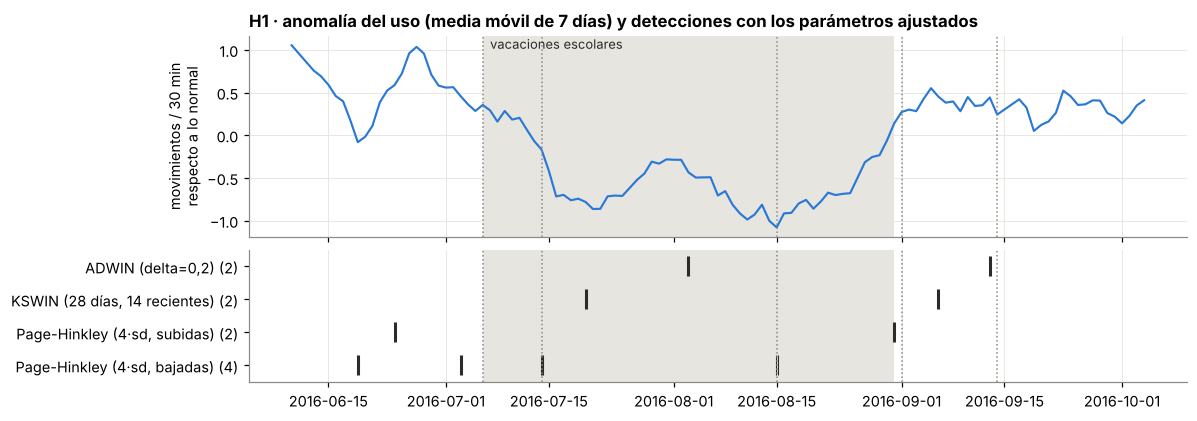

In [55]:
# Detecciones con los parámetros elegidos en el barrido
ELEGIDOS = {
    "ADWIN (delta=0,2)": ("ADWIN", "delta=0.2, clock=1, grace_period=7"),
    "KSWIN (28 días, 14 recientes)": ("KSWIN", "alpha=0.005, window_size=28, stat_size=14"),
    "Page-Hinkley (4·sd, subidas)": ("Page-Hinkley", "threshold=4·sd, mode=up"),
    "Page-Hinkley (4·sd, bajadas)": ("Page-Hinkley", "threshold=4·sd, mode=down"),
}
media_semanal = serie_h1.rolling(7, min_periods=4).mean()
dibujar_detecciones(media_semanal, {n: barrido[c] for n, c in ELEGIDOS.items()},
                    "H1 · anomalía del uso (media móvil de 7 días) y detecciones con los parámetros ajustados",
                    "movimientos / 30 min\nrespecto a lo normal")

**Conclusión (H1): confirmada.** La anomalía del uso baja a partir de mediados de julio (los colegios cierran el 6 de julio y el uso cae en las semanas siguientes), se mantiene baja en agosto y se recupera en los últimos días de agosto, justo antes de la vuelta a clase.

Con los parámetros ajustados:
- **KSWIN detecta los dos cambios en los momentos correctos** (20 de julio y 6 de septiembre);
- ADWIN los detecta con más retraso (3 de agosto y 13 de septiembre);
- Page-Hinkley detecta la recuperación (31 de agosto), pero confunde los festivos con cambios.

Para este flujo, **KSWIN sobre la anomalía diaria del uso** es el mejor detector de *data drift*. Detecta el cambio de comportamiento **sin necesitar etiquetas**, incluso cuando no afecta al modelo: en julio y agosto el uso baja, pero el error del ARF no sube.

**Limitación (para el análisis crítico):** los parámetros se han ajustado mirando el mismo periodo en el que se evalúan, conociendo ya las fechas de las vacaciones. En un sistema real habría que fijarlos con un periodo anterior (por ejemplo, el verano de otro año) y comprobar después que funcionan. Por otra parte, los resultados que dependen del modelo (apartado 4.5 y la parte del error de H4) se han repetido con 10 semillas, porque una sola ejecución puede llevar a conclusiones erróneas. Los de *data drift* no dependen del modelo y son siempre iguales.

## 4.7 *Concept drift* controlado y estrategias de adaptación

En el flujo real de *pomme* el *concept drift* es muy leve y el ARF online lo absorbe solo (apartado 4.5), así que con él no se puede:
1. medir el **retardo** y las **falsas alarmas** de cada detector frente a un cambio cuya fecha se conoce, ni
2. comparar **estrategias de adaptación** (reiniciar el modelo, modelo en segundo plano, árboles adaptativos…).

Para eso construimos un *concept drift* **fuerte y conocido con datos reales**: el sistema de alerta, que ha aprendido con *pomme*, empieza a recibir el **1 de agosto** los datos de otra estación de Toulouse, como si se desplegara en otro punto de la ciudad. A partir de ese momento cambia la relación entre las variables (hora, día, bicis, tiempo) y la probabilidad de quedarse sin bicis. Es el mismo planteamiento que los flujos sintéticos de los cuadernos del tema (cambio en una posición conocida), pero con datos reales.

### 4.7.1 Construcción del escenario

#### Flujo de cada estación

La función `construir_flujo` repite la construcción del apartado 4.1 (una instancia cada 30 minutos, mismas variables, etiqueta "2 bicis o menos dentro de 2 horas") para cualquier estación del dataset `Bikes`.

In [56]:
# Flujo regular de 30 minutos de cada una de las 5 estaciones (misma construcción que en 4.1)
crudo = pd.read_csv(dataset.path, parse_dates=["moment"]).drop_duplicates()

FESTIVOS = pd.to_datetime(["2016-07-14", "2016-08-15"])
METEO = {"temperature": "temperatura", "humidity": "humedad", "wind": "viento", "clouds": "nubes"}


def construir_flujo(estacion, inicio="2016-06-01"):
    """Flujo regular de 30 minutos de una estación (igual que en el apartado 4.1)."""
    serie = crudo[(crudo["station"] == estacion) & (crudo["moment"] >= inicio)].set_index("moment").sort_index()
    reg = serie.resample(FREQ, label="right", closed="right").last()
    hay_dato = serie["bikes"].resample(FREQ, label="right", closed="right").count() > 0
    f = pd.DataFrame(index=reg.index)
    f["bicis"] = reg["bikes"].where(hay_dato)
    f["tendencia_1h"] = f["bicis"] - f["bicis"].shift(2)
    f["hora"] = f.index.hour + f.index.minute / 60
    f["dia_semana"] = f.index.dayofweek
    f["es_finde"] = (f.index.dayofweek >= 5).astype(int)
    f["es_festivo"] = f.index.normalize().isin(FESTIVOS).astype(int)
    for original, nuevo in METEO.items():
        f[nuevo] = reg[original].where(hay_dato)
    f["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)
    f["movimientos_30min"] = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum().where(hay_dato)
    f["bicis_2h"] = f["bicis"].reindex(f.index + pd.Timedelta(HORIZONTE)).to_numpy()
    f["pocas_bicis_2h"] = (f["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(f["bicis_2h"].notna())
    f = f.dropna(subset=["bicis", "pocas_bicis_2h"])
    f.index.name = "momento"
    return f


flujos = {e: construir_flujo(e) for e in sorted(crudo["station"].unique())}
pd.DataFrame({e: {"instancias": len(f), "bicis medias": f["bicis"].mean(), "% alerta": 100 * f["pocas_bicis_2h"].mean()}
              for e, f in flujos.items()}).T.round(1)

,instancias,bicis medias,% alerta
metro-canal-du-midi,5715.0,10.1,16.3
place-des-carmes,5615.0,7.1,35.4
place-esquirol,5862.0,13.4,33.8
place-jeanne-darc,5631.0,5.9,34.9
pomme,5980.0,6.5,43.0


#### Evaluación *prequential* con retraso de la etiqueta

Mismo bucle que en el apartado 4.3: en cada instancia llegan primero las etiquetas de las predicciones de hace 2 horas (se evalúa, se actualiza el detector y el modelo aprende) y después se predice la instancia nueva. Se añade una opción para **reaccionar al drift**: cuando el detector salta, el modelo se reinicia (se sustituye por uno nuevo).

In [57]:
# Bucle prequential con opción de reiniciar el modelo cuando salta un detector o en una fecha fija
def prequential_cambio(fabrica_modelo, instancias, retraso=HORIZONTE, detector=None, reiniciar=False, reinicio_en=None):
    """Evaluación test-then-train con la etiqueta retrasada.
    detector: recibe el bit de error; si reiniciar=True, cada drift (desde INICIO_EVALUACION) sustituye el modelo por uno nuevo.
    reinicio_en: fecha en que el modelo se sustituye por uno nuevo (el 'oráculo' que sabe cuándo ocurre el cambio).
    Devuelve (registro por instancia, fechas de drift, fechas de warning)."""
    retraso = pd.Timedelta(retraso)
    modelo = fabrica_modelo()
    pendientes, registros, drifts, avisos = collections.deque(), [], [], []
    en_warning, reiniciado = False, False
    for x, y in instancias:
        t = x["momento"]
        if reinicio_en is not None and not reiniciado and t >= reinicio_en:
            modelo, reiniciado = fabrica_modelo(), True
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, error))
            if detector is not None:
                detector.update(error)
                if t >= INICIO_EVALUACION:
                    if detector.drift_detected:
                        drifts.append(t)
                        en_warning = False
                        if reiniciar:
                            modelo = fabrica_modelo()
                    elif getattr(detector, "warning_detected", False):
                        if not en_warning:
                            avisos.append(t)
                            en_warning = True
                    else:
                        en_warning = False
            modelo.learn_one(x0, y0)
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "error"]).set_index("momento")
    return registro, drifts, avisos


def instancias_de(tabla):
    """Recorre una tabla del flujo como pares (x, y), igual que iter_csv."""
    for t, fila in tabla.iterrows():
        x = {k: fila[k] for k in COLUMNAS_X if pd.notna(fila[k])}
        x["momento"] = t
        yield x, bool(fila["pocas_bicis_2h"])

#### ¿A qué estación se cambia?

Para elegir la estación, medimos cuánto empeora un modelo que ha aprendido con *pomme* cuando, el 1 de agosto, empieza a recibir los datos de cada una de las otras estaciones (`HoeffdingTreeClassifier`, que no es aleatorio). Se compara con un modelo que ha aprendido **solo** con la estación nueva desde junio: la diferencia es lo que "cuesta" haber aprendido otra cosa.

In [58]:
# ¿Cuánto cuesta pasar de pomme a cada una de las otras estaciones el 1 de agosto?
CAMBIO = pd.Timestamp("2016-08-01")
D = pd.Timedelta
filas = {}
for estacion in [e for e in flujos if e != "pomme"]:
    mezcla_e = pd.concat([flujos["pomme"][flujos["pomme"].index < CAMBIO], flujos[estacion][flujos[estacion].index >= CAMBIO]])
    reg_mezcla, _, _ = prequential_cambio(tree.HoeffdingTreeClassifier, instancias_de(mezcla_e))
    reg_solo, _, _ = prequential_cambio(tree.HoeffdingTreeClassifier, instancias_de(flujos[estacion]))
    filas[estacion] = {
        "error 2 semanas antes (pomme)": 100 * reg_mezcla["error"][CAMBIO - D("14D"):CAMBIO].mean(),
        "error 1ª semana tras el cambio": 100 * reg_mezcla["error"][CAMBIO:CAMBIO + D("7D")].mean(),
        "error ago-oct (viene de pomme)": 100 * reg_mezcla["error"][CAMBIO:].mean(),
        "error ago-oct (solo esa estación)": 100 * reg_solo["error"][CAMBIO:].mean(),
    }
tabla_estaciones = pd.DataFrame(filas).T.round(1)
tabla_estaciones["coste de venir de pomme (puntos)"] = (tabla_estaciones.iloc[:, 2] - tabla_estaciones.iloc[:, 3]).round(1)
tabla_estaciones

,error 2 semanas antes (pomme),error 1ª semana tras el cambio,error ago-oct (viene de pomme),error ago-oct (solo esa estación),coste de venir de pomme (puntos)
metro-canal-du-midi,18.1,12.2,18.6,16.5,2.1
place-des-carmes,18.1,21.8,22.4,23.6,-1.2
place-esquirol,18.3,14.4,17.2,18.8,-1.6
place-jeanne-darc,18.1,28.1,31.4,24.0,7.4


**Elección: *place-jeanne-darc*.** Es la única estación con la que hay un *concept drift* claro: el error salta del 18,1 % al 28,1 % la primera semana y, de agosto a octubre, el modelo que viene de *pomme* falla 7,4 puntos más que uno que ha aprendido solo con esa estación. Con las demás estaciones el cambio apenas cuesta (entre −1,6 y +2,1 puntos): lo aprendido en *pomme* sirve también allí.

#### El flujo con el cambio

Se guarda como CSV y se lee con `river.stream.iter_csv`, igual que el flujo de *pomme*.

In [59]:
# Flujo con el cambio: pomme hasta el 31 de julio y place-jeanne-darc desde el 1 de agosto
ESTACION_NUEVA = "place-jeanne-darc"
cambio = pd.concat([flujos["pomme"][flujos["pomme"].index < CAMBIO],
                    flujos[ESTACION_NUEVA][flujos[ESTACION_NUEVA].index >= CAMBIO]])
CSV_CAMBIO = "flujo_cambio_estacion.csv"
cambio.to_csv(CSV_CAMBIO, date_format="%Y-%m-%d %H:%M:%S")

def flujo_cambio(ruta=CSV_CAMBIO):
    for x, y in stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                                parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}, drop=["bicis_2h"]):
        yield {k: v for k, v in x.items() if v is not None}, y


print(f"{len(cambio):,} instancias: {(cambio.index < CAMBIO).sum():,} de pomme (1 jun-31 jul) y "
      f"{(cambio.index >= CAMBIO).sum():,} de {ESTACION_NUEVA} (1 ago-5 oct)")

5,795 instancias: 2,927 de pomme (1 jun-31 jul) y 2,868 de place-jeanne-darc (1 ago-5 oct)


### 4.7.2 Detectores de *concept drift* con un cambio conocido

Ahora sí sabemos dónde está el drift: el **1 de agosto a las 0:00**. Igual que en el cuaderno comparativo de la asignatura, para cada detector medimos:
- **% de ejecuciones que detectan el cambio** en las 2 semanas siguientes.
- **Retardo** (días desde el cambio hasta la primera detección en esas 2 semanas). Como la etiqueta llega 2 horas tarde, el retardo mínimo posible es de 2 horas.
- **Falsas alarmas antes del cambio** (del 15 de junio al 31 de julio, cuando no hay cambio), por mes.
- **Antelación del *warning***: cuánto antes del drift entra el detector en zona de *warning* (solo los binarios).

Se usan el Hoeffding Tree (determinista) y el ARF con 10 semillas: 11 flujos de errores.

In [60]:
# Flujos de errores del Hoeffding Tree y del ARF (10 semillas) sobre el flujo con el cambio
FABRICAS_DET = {"DDM": drift.binary.DDM, "EDDM": drift.binary.EDDM, "HDDM_A": drift.binary.HDDMA,
                "HDDM_W": drift.binary.HDDMW, "Page-Hinkley": lambda: drift.PageHinkley(mode="up"), "ADWIN": drift.ADWIN}
MODELOS_CAMBIO = {"Hoeffding Tree": tree.HoeffdingTreeClassifier,
           **{f"ARF semilla {s}": (lambda s=s: forest.ARFClassifier(n_models=10, seed=s)) for s in SEMILLAS}}

t0 = time.time()
flujos_error = {}
for nombre, fab in MODELOS_CAMBIO.items():
    reg, _, _ = prequential_cambio(fab, flujo_cambio())
    flujos_error[nombre] = reg
print(f"{len(flujos_error)} ejecuciones en {time.time() - t0:.0f} s")

11 ejecuciones en 99 s


In [61]:
# Detectores frente al cambio conocido: % que lo detectan, retardo, falsas alarmas y antelación del warning
VENTANA = (CAMBIO, CAMBIO + D("14D"))
meses_antes = (CAMBIO - INICIO_EVALUACION).days / 30.4


def vigilar_registro(detector, registro):
    """Bucle de los cuadernos del tema sobre el flujo de errores ya calculado."""
    drifts, avisos, en_warning = [], [], False
    for t, error in zip(registro["revelada"], registro["error"]):
        detector.update(error)
        if t < INICIO_EVALUACION:
            continue
        if detector.drift_detected:
            drifts.append(t)
            en_warning = False
        elif getattr(detector, "warning_detected", False):
            if not en_warning:
                avisos.append(t)
                en_warning = True
        else:
            en_warning = False
    return drifts, avisos


filas, detecciones = [], collections.defaultdict(dict)
for nombre_modelo, reg in flujos_error.items():
    for nombre_det, fab in FABRICAS_DET.items():
        drifts, avisos = vigilar_registro(fab(), reg)
        detecciones[nombre_det][nombre_modelo] = drifts
        dentro = [d for d in drifts if VENTANA[0] <= d < VENTANA[1]]
        antelacion = np.nan
        if dentro:
            previos = [a for a in avisos if CAMBIO <= a <= dentro[0]]
            antelacion = (dentro[0] - previos[0]).total_seconds() / 86400 if previos else np.nan
        filas.append({"detector": nombre_det, "modelo": nombre_modelo,
                      "detecta": bool(dentro),
                      "retardo_dias": (dentro[0] - CAMBIO).total_seconds() / 86400 if dentro else np.nan,
                      "falsas_alarmas_mes": len([d for d in drifts if d < CAMBIO]) / meses_antes,
                      "antelacion_warning_dias": antelacion})
res_det = pd.DataFrame(filas)
g = res_det.groupby("detector", sort=False)
tabla_detectores = pd.DataFrame({
    "% ejecuciones que detectan (2 semanas)": 100 * g["detecta"].mean(),
    "retardo mediano (días)": g["retardo_dias"].median(),
    "retardo mín.-máx. (días)": g["retardo_dias"].agg(lambda x: f"{x.min():.1f}-{x.max():.1f}" if x.notna().any() else "—"),
    "falsas alarmas antes del cambio (por mes)": g["falsas_alarmas_mes"].mean(),
    "antelación del warning (días, mediana)": g["antelacion_warning_dias"].median(),
}).round(1)
tabla_detectores

,% ejecuciones que detectan (2 semanas),retardo mediano (días),retardo mín.-máx. (días),falsas alarmas antes del cambio (por mes),"antelación del warning (días, mediana)"
detector,,,,,
DDM,72.7,7.8,4.8-10.7,1.5,3.3
EDDM,100.0,3.6,0.2-10.5,6.8,5.4
HDDM_A,100.0,2.9,0.2-4.9,2.1,0.0
HDDM_W,100.0,4.1,0.2-4.2,2.2,0.0
Page-Hinkley,90.9,10.5,6.8-10.9,0.0,NaN
ADWIN,100.0,5.5,1.1-11.6,0.1,NaN


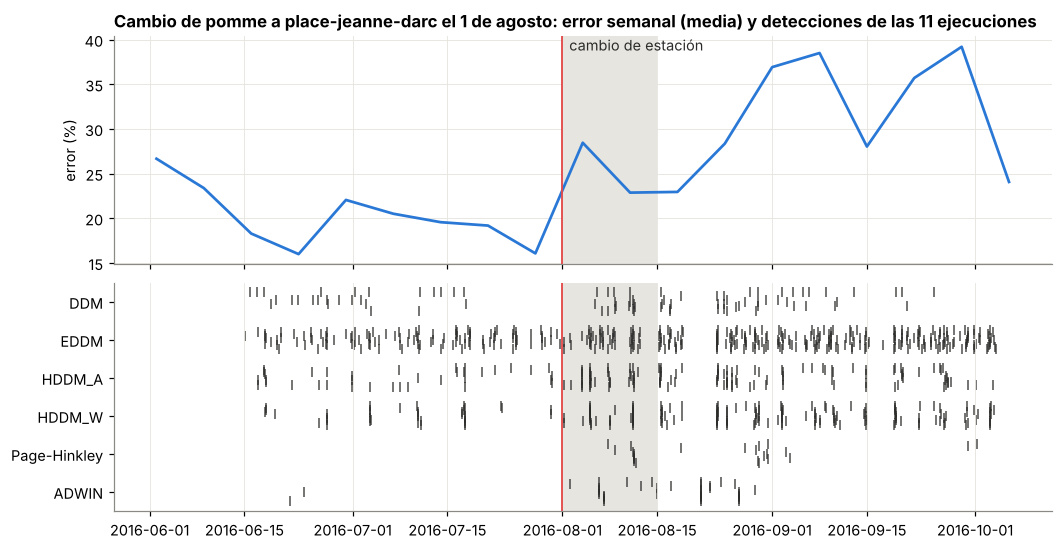

In [62]:
# Error semanal (media de las 11 ejecuciones) y detecciones de cada ejecución
semanas = pd.DataFrame({n: r["error"].resample("W-SUN").mean() for n, r in flujos_error.items()})
semanas.index = semanas.index - pd.Timedelta(days=3)
nombres = list(FABRICAS_DET)

fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 5.6), gridspec_kw={"height_ratios": [2.2, 2.2], "hspace": 0.08})
a1.plot(semanas.index, 100 * semanas.mean(axis=1), color=AZUL, lw=1.8)
a1.set_ylabel("error (%)")
a1.set_title(f"Cambio de pomme a {ESTACION_NUEVA} el 1 de agosto: error semanal (media) y detecciones de las 11 ejecuciones")
for j, nd in enumerate(nombres):
    for k, (nm, fechas) in enumerate(detecciones[nd].items()):
        a2.scatter(fechas, [j + (k - 5) * 0.05] * len(fechas), marker="|", s=40, lw=1.2, color=TINTA, alpha=0.7)
for ax in (a1, a2):
    ax.axvline(CAMBIO, color=ROJO, lw=1.2)
    ax.axvspan(*VENTANA, color=SOMBRA, lw=0, zorder=0)
a1.text(CAMBIO + D("1D"), a1.get_ylim()[1], "cambio de estación", va="top", color=TINTA)
a2.set_yticks(range(len(nombres)))
a2.set_yticklabels(nombres)
a2.set_ylim(len(nombres) - 0.5, -0.5)
a2.grid(axis="y", visible=False)
plt.show()

**Conclusión: con un cambio claro, los detectores se ordenan por el compromiso entre retardo y falsas alarmas.**

- **HDDM_A** es el más rápido con pocas falsas alarmas: detecta el cambio en todas las ejecuciones con un retardo mediano de 2,9 días, a cambio de unas 2 falsas alarmas al mes antes del cambio. HDDM_W es parecido (4,1 días; 2,2 falsas alarmas al mes).
- **ADWIN** es el más fiable: detecta el cambio en todas las ejecuciones (retardo mediano de 5,5 días) y casi no da falsas alarmas (0,1 al mes).
- **Page-Hinkley** no da ninguna falsa alarma, pero es el más lento (10,5 días) y no detecta el cambio en 1 de las 11 ejecuciones.
- **DDM** solo detecta el cambio en el 73 % de las ejecuciones y tarda 7,8 días: el error sube unos 10 puntos, y DDM necesita una subida mayor respecto a su mínimo histórico.
- **EDDM** detecta rápido (3,6 días), pero con 6,8 falsas alarmas al mes: no sirve para disparar acciones.
- **Warnings:** en DDM y EDDM la zona de *warning* llega de 3 a 5 días antes del drift, un margen para empezar a entrenar un modelo en segundo plano; en HDDM el *warning* coincide con el drift y no aporta.
- **Ningún detector reacciona en horas:** con una etiqueta que llega 2 horas tarde y un cambio de unos 10 puntos de error, todos necesitan **días** de evidencia. Además, después del cambio el error sigue subiendo (septiembre es mucho más difícil en *place-jeanne-darc*) y los detectores sensibles siguen saltando.

### 4.7.3 Estrategias de adaptación

Detectar solo sirve si después se hace algo. Comparamos las estrategias del tema:

| Estrategia | Qué hace | Estrategia del tema |
|---|---|---|
| Sin reacción | Hoeffding Tree que sigue aprendiendo online, sin detector | actualización incremental |
| Oráculo | se sustituye el modelo por uno nuevo **justo el 1 de agosto** (nadie sabe eso en la realidad: es la referencia de lo mejor que puede hacer un reinicio) | reentrenamiento completo |
| Reinicio con X | cuando el detector X salta, se sustituye el modelo por uno nuevo | detección + reentrenamiento completo |
| Modelo en segundo plano | `drift.DriftRetrainingClassifier` con DDM: en el *warning* empieza a entrenar un modelo nuevo y en el drift lo sustituye | detección + sustitución |
| Hoeffding Adaptive Tree | árbol con ADWIN en cada nodo: sustituye solo las ramas afectadas | sustitución parcial del modelo |
| ARF | bosque con un detector ADWIN por árbol: sustituye los árboles que empeoran | ensamblado dinámico |
| EFDT | árbol que reevalúa sus divisiones con los datos nuevos, sin detector de drift | adaptación implícita |

Las estrategias con Hoeffding Tree y el EFDT son deterministas; el Hoeffding Adaptive Tree y el ARF se repiten con 10 semillas.

Métricas: error **antes** del cambio (15 jun-31 jul: el coste de las falsas alarmas), en las **2 semanas siguientes** al cambio (la reacción), de **agosto a octubre** y **total**, y número de reinicios antes y después del cambio.

In [63]:
# Comparación de estrategias de adaptación ante el cambio de estación
def medir_estrategia(registro, drifts=()):
    e = registro["error"]
    return {"error antes (%)": 100 * e[INICIO_EVALUACION:CAMBIO].mean(),
            "error 2 semanas después (%)": 100 * e[CAMBIO:CAMBIO + D("14D")].mean(),
            "error ago-oct (%)": 100 * e[CAMBIO:].mean(),
            "error total (%)": 100 * e[INICIO_EVALUACION:].mean(),
            "reinicios antes": sum(d < CAMBIO for d in drifts),
            "reinicios después": sum(d >= CAMBIO for d in drifts)}


HT = tree.HoeffdingTreeClassifier
t0 = time.time()
estrategias, registros_estr = {}, {}

reg, _, _ = prequential_cambio(HT, flujo_cambio())
estrategias["Sin reacción (Hoeffding Tree)"], registros_estr["Sin reacción"] = medir_estrategia(reg), reg

reg, _, _ = prequential_cambio(HT, flujo_cambio(), reinicio_en=CAMBIO)
estrategias["Oráculo: reinicio el 1 de agosto"], registros_estr["Oráculo"] = medir_estrategia(reg), reg

for nombre_det, fab in FABRICAS_DET.items():
    reg, drifts, _ = prequential_cambio(HT, flujo_cambio(), detector=fab(), reiniciar=True)
    estrategias[f"Reinicio con {nombre_det}"] = medir_estrategia(reg, drifts)
    registros_estr[f"Reinicio con {nombre_det}"] = reg

reg, _, _ = prequential_cambio(lambda: drift.DriftRetrainingClassifier(model=tree.HoeffdingTreeClassifier(),
                                                                drift_detector=drift.binary.DDM()), flujo_cambio())
estrategias["Modelo en segundo plano (DDM)"] = medir_estrategia(reg)

reg, _, _ = prequential_cambio(tree.ExtremelyFastDecisionTreeClassifier, flujo_cambio())
estrategias["EFDT (adaptación implícita)"], registros_estr["EFDT"] = medir_estrategia(reg), reg

for nombre, fab in {"Hoeffding Adaptive Tree": lambda s: tree.HoeffdingAdaptiveTreeClassifier(seed=s),
                    "ARF": lambda s: forest.ARFClassifier(n_models=10, seed=s)}.items():
    regs = [flujos_error[f"ARF semilla {s}"] if nombre == "ARF" else prequential_cambio(lambda s=s: fab(s), flujo_cambio())[0]
            for s in SEMILLAS]
    medidas = pd.DataFrame([medir_estrategia(r) for r in regs])
    estrategias[f"{nombre} (media de 10 semillas)"] = medidas.mean().to_dict()
    registros_estr[nombre] = regs
print(f"{time.time() - t0:.0f} s")

tabla_estrategias = pd.DataFrame(estrategias).T.round(1)
tabla_estrategias

26 s


,error antes (%),error 2 semanas después (%),error ago-oct (%),error total (%),reinicios antes,reinicios después
Sin reacción (Hoeffding Tree),20.2,22.3,31.4,26.4,0.0,0.0
Oráculo: reinicio el 1 de agosto,20.2,23.7,29.9,25.6,0.0,0.0
Reinicio con DDM,25.9,29.2,32.2,29.4,2.0,15.0
Reinicio con EDDM,23.3,26.5,31.2,27.7,2.0,20.0
Reinicio con HDDM_A,24.4,22.7,30.3,27.7,9.0,20.0
Reinicio con HDDM_W,25.5,19.0,28.6,27.3,5.0,16.0
Reinicio con Page-Hinkley,20.2,25.8,30.4,25.9,0.0,2.0
Reinicio con ADWIN,20.2,22.9,29.6,25.4,0.0,4.0
Modelo en segundo plano (DDM),23.7,29.7,32.8,28.7,0.0,0.0
EFDT (adaptación implícita),20.0,22.1,31.1,26.2,0.0,0.0


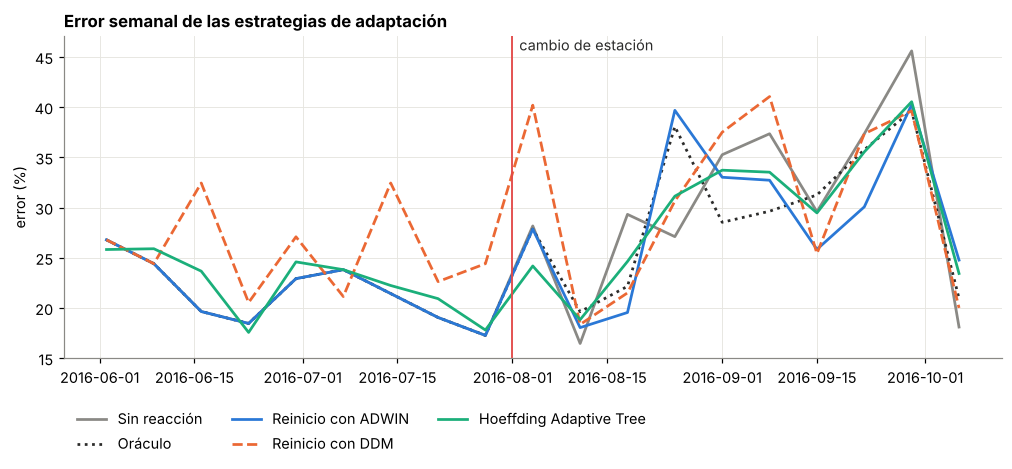

In [64]:
# Error semanal de algunas estrategias
def semanal(reg):
    if isinstance(reg, list):
        s = pd.DataFrame({i: r["error"].resample("W-SUN").mean() for i, r in enumerate(reg)}).mean(axis=1)
    else:
        s = reg["error"].resample("W-SUN").mean()
    s.index = s.index - pd.Timedelta(days=3)
    return 100 * s

fig, ax = plt.subplots(figsize=(11, 3.8))
for nombre, color, ls in [("Sin reacción", GRIS, "-"), ("Oráculo", TINTA, ":"), ("Reinicio con ADWIN", AZUL, "-"),
                          ("Reinicio con DDM", NARANJA, "--"), ("Hoeffding Adaptive Tree", VERDE, "-")]:
    s = semanal(registros_estr[nombre])
    ax.plot(s.index, s.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvline(CAMBIO, color=ROJO, lw=1.2)
ax.text(CAMBIO + D("1D"), ax.get_ylim()[1], "cambio de estación", va="top", color=TINTA)
ax.set_title("Error semanal de las estrategias de adaptación")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.show()

**Conclusión: reaccionar al drift ayuda poco, y reaccionar a falsas alarmas empeora el sistema.**

- **Reiniciar con ADWIN es la mejor estrategia:** 25,4 % de error total frente al 26,4 % de no reaccionar, y de agosto a octubre (29,6 %) iguala al oráculo que sabe cuándo ocurre el cambio (29,9 %). Combina detectar el cambio siempre y no dar falsas alarmas: no reinicia ninguna vez antes del cambio.
- **El Hoeffding Adaptive Tree** (sustitución parcial) y **el ARF** (ensamblado dinámico) quedan cerca sin detector externo (26,1 % y 25,6 % de error total). El ARF es el mejor antes del cambio (18,6 %) y el que peor reacciona (26,0 % en las 2 semanas siguientes): sustituye sus árboles poco a poco.
- **El EFDT** (adaptación implícita, sin detector) apenas mejora a no reaccionar (26,2 % frente a 26,4 % de error total; 31,1 % frente a 31,4 % de agosto a octubre). Reevalúa sus divisiones con los datos nuevos, pero lo hace poco a poco: como dice la tabla resumen del tema, se adapta bien a cambios **graduales**, y aquí el cambio es **brusco**.
- **Reiniciar con DDM, EDDM o HDDM es peor que no hacer nada** (27,3-29,4 % de error total). Sus falsas alarmas reinician el modelo antes del cambio (de 2 a 9 veces) y el error antes del cambio sube del 20,2 % hasta el 25,9 %. Después del cambio, el modelo recién reiniciado falla mucho mientras aprende, el detector vuelve a saltar y se encadenan los reinicios (de 15 a 20). HDDM_W consigue el mejor error de agosto a octubre (28,6 %), pero lo paga antes del cambio.
- **El modelo en segundo plano con DDM** tampoco ayuda (28,7 % de error total): sus avisos y drifts falsos sustituyen el modelo antes del cambio (el error antes del cambio sube del 20,2 % al 23,7 %).
- **Las ganancias son pequeñas** (como mucho 1 punto de error total): reiniciar también tira lo que sigue sirviendo (el ciclo diario es parecido en las dos estaciones), y septiembre en *place-jeanne-darc* es difícil para cualquier modelo (todas las estrategias superan el 35 % de error en algunas semanas).
- **Lección:** para disparar un reentrenamiento importa más **no dar falsas alarmas** que detectar rápido. Con un detector conservador (ADWIN, Page-Hinkley) reiniciar es seguro; con uno sensible (EDDM, HDDM, DDM) es mejor un modelo que se adapte solo (Hoeffding Adaptive Tree, ARF).

## 4.8 Flujo de avisos de usuarios: clasificación de texto online

La alerta del apartado 4.4 anticipa una parte de los problemas, pero los usuarios siguen escribiendo al operador: que no hay bicis, que no pueden devolver la suya, que un freno no funciona, que la aplicación no les deja pagar… Hoy alguien tiene que leer cada mensaje y enviarlo al equipo que corresponde:

| Categoría | Ejemplo | Equipo |
|---|---|---|
| `sin_bicis` | *"plus aucun vélo à Pomme, c'est la troisième fois cette semaine"* | redistribución |
| `estacion_llena` | *"impossible de rendre mon vélo, tout est plein"* | redistribución |
| `averia` | *"pneu crevé, vélo 214 inutilisable"* | taller |
| `averia_estacion` | *"la borne ne lit pas ma carte"* (solo existe desde el 1 de septiembre, ver 4.8.1) | mantenimiento de estaciones |
| `app_pago` | *"paiement refusé alors que ma carte marche"* | soporte técnico |
| `otro` | *"quels sont les tarifs pour un abonnement annuel ?"* | atención al cliente |

El subsistema 2 **clasifica cada aviso en cuanto llega** y aprende de la categoría que le pone el operador cuando lo atiende. Es un problema de **clasificación de texto multiclase en un flujo**, con los mismos retos que el flujo de sensores: la etiqueta llega tarde, el vocabulario cambia con el tiempo y las propias categorías pueden cambiar.

### 4.8.1 Origen del flujo: avisos generados a partir del estado real de la estación

**Por qué datos sintéticos.** No existen datos públicos de mensajes de usuarios de un sistema de bicicletas compartidas (y menos de Toulouse en 2016), y los avisos de clientes de una empresa no se publican por privacidad. El enunciado permite datos sintéticos procesados como flujo, y es lo que hacen los cuadernos del tema para evaluar detectores. Para que **no sean datos de juguete**, el generador cumple tres condiciones:

1. **Está ligado al flujo real de sensores.** En cada media hora del flujo de *pomme*, el número de avisos de cada tipo sigue una distribución de Poisson cuya intensidad depende del **estado real de la estación**: las quejas de `sin_bicis` aparecen sobre todo cuando *pomme* tiene realmente 0 bicis (y algo menos con 1-2 bicis), las de `estacion_llena` cuando tiene 17 bicis o más, y todas se multiplican por la **actividad real de la estación** a esa hora y ese tipo de día (movimientos medios). Así, el flujo de texto hereda los patrones reales del flujo de sensores.
2. **El texto es realista y ruidoso.** Los avisos están en **francés** (es Toulouse), con varias formas de decir lo mismo, saludos y coletillas, un 30 % en minúsculas, un 25 % sin tildes, un **20 % con erratas** (letras borradas, duplicadas o intercambiadas) y **palabras compartidas entre clases** ("borne" aparece en `sin_bicis`, `estacion_llena` y `averia_estacion`; "carte" en `app_pago` y `averia_estacion`). Además, el **3 % de las etiquetas está mal puesto**, como pasaría con un operador real.
3. **Incluye cambios con fecha conocida**, igual que los flujos sintéticos del tema, para poder medir el retardo y las falsas alarmas de los detectores:

| Fecha | Cambio | Tipo de drift |
|---|---|---|
| 6 jul - 31 ago | Vacaciones: llegan turistas y el **35 % de los avisos se escribe en inglés** (5 % el resto del año); también hay más consultas (`otro`) | *data drift* en el vocabulario (H5) |
| 21 jul | **Caída de la aplicación**: los avisos de `app_pago` se multiplican por 10 durante el día | *data drift* en la proporción de clases |
| 1 sep | **El operador reorganiza sus categorías**: separa las averías de la estación (borne, lector de tarjetas, anclajes) de las averías de las bicis. Los mismos textos que antes eran `averia` pasan a ser `averia_estacion` | ***concept drift***: cambia P(categoría \| texto) (H6) |
| 12-14 sep | **Avería de la borne de *pomme***: los avisos de `averia_estacion` se multiplican por 8 | aparición masiva de la clase nueva |

**Retraso de la etiqueta:** el operador atiende el aviso y le pone la categoría **1 hora después** de que llegue.

Como el flujo es sintético, **conocemos la verdad**: el objetivo no es descubrir si estos cambios existen, sino comprobar **si los métodos los detectan, con qué retardo y cómo responde cada modelo**.

In [65]:
# --- Plantillas de los avisos: francés (usuarios locales) e inglés (turistas) ---------------------------
ESTACION_FR = ["à Pomme", "station Pomme", "à la station Pomme", "rue de la Pomme", "à la station de la rue de la Pomme",
               "pomme", "à la station", ""]
ESTACION_EN = ["at Pomme", "at the Pomme station", "Pomme station", "at rue de la Pomme", ""]

PLANTILLAS_FR = {
    "sin_bicis": [
        "plus aucun vélo {est}", "aucun vélo disponible {est}", "station vide {est}", "il n'y a plus de vélos {est}",
        "pas un seul vélo {est}", "encore zéro vélo {est}", "toujours pas de vélo {est}", "la station est vide {est}",
        "impossible de trouver un vélo {est}", "plus de vélos dispo {est}", "aucun vélo, toutes les bornes sont libres {est}",
        "je voulais prendre un vélo {est} mais il n'y en avait aucun", "vélos introuvables {est}, station déserte",
        "j'ai dû marcher, pas de vélo {est}", "impossible de prendre un vélo {est}, il n'y en a plus",
    ],
    "estacion_llena": [
        "station pleine {est}", "impossible de rendre mon vélo {est}, tout est plein", "aucune place libre {est}",
        "plus de place pour déposer le vélo {est}", "la station est complète {est}", "je n'arrive pas à rendre le vélo {est}, c'est plein",
        "toutes les bornes sont occupées {est}", "pas de point d'attache libre {est}", "je tourne avec mon vélo, station saturée {est}",
        "où je pose le vélo ? {est} c'est plein", "impossible de rendre le vélo {est}, aucune borne libre",
    ],
    "averia": [
        "le frein du vélo ne marche pas", "chaîne cassée sur le vélo {num}", "pneu crevé, vélo {num} inutilisable",
        "la selle du vélo {num} est cassée", "le vélo {num} a un pneu à plat", "les freins sont morts sur le vélo {num}",
        "vélo {num} : la chaîne déraille sans arrêt", "le guidon du vélo {num} est tordu", "lumière du vélo {num} en panne",
        "le vélo {num} est cassé, je l'ai laissé {est}", "vélo abîmé {est}, la roue est voilée", "le vélo {num} fait un bruit bizarre, frein qui frotte",
    ],
    "averia_estacion": [
        "la borne {est} ne fonctionne pas", "l'écran de la borne {est} est noir", "le lecteur de carte de la borne {est} est en panne",
        "la borne {est} ne lit pas ma carte", "le point d'attache {est} est bloqué", "le vélo ne se décroche pas de la borne {est}",
        "terminal hors service {est}", "la borne {est} affiche une erreur", "impossible de libérer le vélo, la borne {est} est bloquée",
        "le cadenas de la borne {est} ne s'ouvre pas", "la borne de paiement {est} est cassée",
    ],
    "app_pago": [
        "l'application plante quand je veux payer", "paiement refusé alors que ma carte marche", "mon abonnement n'apparaît plus dans l'appli",
        "l'appli ne m'envoie pas le code", "on m'a débité deux fois", "impossible de me connecter à l'application",
        "ma carte bancaire est refusée sur l'appli", "l'application ne charge pas la carte des stations", "j'ai été prélevé sans raison",
        "le code de déverrouillage ne marche pas dans l'appli", "bug de l'appli, impossible de louer un vélo",
    ],
    "otro": [
        "quels sont les tarifs pour un abonnement annuel ?", "merci pour le service, très pratique", "est-ce que la station Pomme est ouverte la nuit ?",
        "il faudrait plus de stations dans le quartier", "comment ajouter un deuxième utilisateur à mon compte ?",
        "super service, je l'utilise tous les jours", "est-ce que je peux garder le vélo plus de 30 minutes ?",
        "proposition : mettre des vélos électriques", "à quelle heure passe le camion de redistribution ?", "bravo pour la nouvelle station",
    ],
}
PLANTILLAS_EN = {
    "sin_bicis": ["no bikes available {est}", "the station is empty {est}", "not a single bike {est}", "couldn't find any bike {est}",
                  "zero bikes {est}, had to walk", "empty station {est}, no bikes at all"],
    "estacion_llena": ["station full {est}, can't return my bike", "no free dock {est}", "can't drop off the bike {est}, all docks taken",
                       "where can I return the bike? {est} is full", "all docks are occupied {est}"],
    "averia": ["bike {num} has a flat tire", "the brakes don't work on bike {num}", "broken chain on bike {num}",
               "the seat of bike {num} is broken", "bike {num} is damaged, left it {est}"],
    "averia_estacion": ["the terminal {est} is not working", "the kiosk screen {est} is black", "the dock {est} won't release the bike",
                        "card reader broken {est}", "the terminal {est} shows an error"],
    "app_pago": ["the app crashes when I try to pay", "my card was declined in the app", "I was charged twice", "can't log in to the app",
                 "the app doesn't send the unlock code"],
    "otro": ["how much is a day pass?", "great service, thanks!", "is there a weekly pass for tourists?", "do you have bikes with child seats?",
             "where is the nearest station to the cathedral?"],
}
INICIO_FR = ["", "", "", "bonjour, ", "bonjour ", "salut, ", "bonsoir, ", "allô ? ", "svp, ", "encore une fois : "]
FIN_FR = ["", "", "", " merci", " !!", " ...", " svp", ", c'est pénible", ", je vais être en retard", " depuis 20 minutes",
          ", c'est la troisième fois cette semaine", " !", " vous faites quoi ?"]
INICIO_EN = ["", "", "hi, ", "hello, ", "excuse me, "]
FIN_EN = ["", "", " thanks", "!!", ", please help", " :("]

In [66]:
# Generador del flujo de avisos a partir del estado real de pomme
SEMILLA_AVISOS = 2016
VERANO = (pd.Timestamp("2016-07-06"), pd.Timestamp("2016-09-01"))     # turistas: más avisos en inglés
CAIDA_APP = pd.Timestamp("2016-07-21")                                  # la aplicación falla todo el día
REORGANIZACION = pd.Timestamp("2016-09-01")                             # el operador crea la categoría averia_estacion
AVERIA_BORNE = (pd.Timestamp("2016-09-12"), pd.Timestamp("2016-09-15"))  # la borne de pomme se estropea
RETRASO_AVISOS = pd.Timedelta("1h")                                     # el operador etiqueta el aviso 1 hora después


def con_erratas(texto, rng, p=0.2):
    """Con probabilidad p, borra, duplica o intercambia una letra de una palabra (errata de teclado)."""
    if rng.random() >= p:
        return texto
    palabras = texto.split(" ")
    largas = [i for i, w in enumerate(palabras) if len(w) > 4]
    if not largas:
        return texto
    i = rng.choice(largas)
    w, j = palabras[i], rng.integers(1, len(palabras[i]) - 1)
    op = rng.integers(3)
    palabras[i] = w[:j] + w[j + 1:] if op == 0 else w[:j] + w[j] + w[j:] if op == 1 else w[:j - 1] + w[j] + w[j - 1] + w[j + 1:]
    return " ".join(palabras)


def redactar(causa, ingles, rng):
    """Escribe un aviso de la causa indicada combinando plantilla, estación, saludo y coletilla, con ruido."""
    plantillas, est, ini, fin = ((PLANTILLAS_EN, ESTACION_EN, INICIO_EN, FIN_EN) if ingles
                                 else (PLANTILLAS_FR, ESTACION_FR, INICIO_FR, FIN_FR))
    t = rng.choice(plantillas[causa]).format(est=rng.choice(est), num=rng.integers(100, 999))
    t = (rng.choice(ini) + t + rng.choice(fin)).replace("  ", " ").strip()
    if rng.random() < 0.3:
        t = t.lower()
    if not ingles and rng.random() < 0.25:               # muchos usuarios escriben sin tildes
        for con, sin in [("é", "e"), ("è", "e"), ("ê", "e"), ("à", "a"), ("ç", "c"), ("ô", "o"), ("î", "i"), ("û", "u")]:
            t = t.replace(con, sin)
    return con_erratas(t, rng)


def generar_avisos(flujo, semilla=SEMILLA_AVISOS):
    """Genera los avisos de los usuarios a partir del estado REAL de pomme en cada media hora."""
    rng = np.random.default_rng(semilla)
    actividad = flujo.groupby(["hora", "es_finde"])["movimientos_30min"].mean()   # uso real por franja
    actividad = actividad / actividad.max()
    filas = []
    for t, f in flujo.iterrows():
        a = actividad.get((f["hora"], f["es_finde"]), 0.0)
        verano = VERANO[0] <= t < VERANO[1]
        intensidad = {                                   # avisos esperados en esta media hora (x2: volumen total)
            "sin_bicis": 2 * a * (1.0 if f["bicis"] == 0 else 0.35 if f["bicis"] <= 2 else 0.01),
            "estacion_llena": 2 * a * (0.7 if f["bicis"] >= 17 else 0.1 if f["bicis"] >= 15 else 0.0),
            "averia": 2 * 0.10 * a,
            "averia_estacion": 2 * 0.06 * a * (8 if AVERIA_BORNE[0] <= t < AVERIA_BORNE[1] else 1),
            "app_pago": 2 * 0.06 * a * (10 if t.normalize() == CAIDA_APP else 1),
            "otro": 2 * 0.05 * a * (2 if verano else 1),
        }
        for causa, lam in intensidad.items():
            for _ in range(rng.poisson(lam)):
                ingles = rng.random() < (0.35 if verano else 0.05)
                momento = t - pd.Timedelta(minutes=30) + pd.Timedelta(seconds=int(rng.integers(0, 1800)))
                # Categoría que pone el operador: antes de la reorganización, las averías de la estación son "averia"
                categoria = "averia" if causa == "averia_estacion" and momento < REORGANIZACION else causa
                filas.append((momento, redactar(causa, ingles, rng), "en" if ingles else "fr", causa, categoria))
    avisos = pd.DataFrame(filas, columns=["momento", "texto", "idioma", "causa", "categoria"])
    avisos = avisos.sort_values("momento", kind="stable").reset_index(drop=True)
    # El operador se equivoca en el 3 % de las etiquetas
    ruido = rng.random(len(avisos)) < 0.03
    antes = ["sin_bicis", "estacion_llena", "averia", "app_pago", "otro"]
    avisos.loc[ruido, "categoria"] = [rng.choice(antes + (["averia_estacion"] if m >= REORGANIZACION else []))
                                      for m in avisos.loc[ruido, "momento"]]
    return avisos


avisos = generar_avisos(flujo)
CSV_AVISOS = "avisos_pomme.csv"
avisos.to_csv(CSV_AVISOS, index=False, date_format="%Y-%m-%d %H:%M:%S")
print(f"Guardado {CSV_AVISOS}: {len(avisos):,} avisos del {avisos['momento'].min():%d-%m} al {avisos['momento'].max():%d-%m}")
avisos.sample(12, random_state=3)[["momento", "texto", "idioma", "categoria"]].sort_values("momento")

Guardado avisos_pomme.csv: 2,523 avisos del 01-06 al 04-10


,momento,texto,idioma,categoria
229,2016-06-11 14:27:00,encore une fois : la station est complète à la station de la rue de la Pomme vous faites quoi ?,fr,estacion_llena
355,2016-06-16 15:36:12,bonjour où je pose le vélo ? station Pomme c'est plein,fr,estacion_llena
361,2016-06-16 17:28:30,bonjour toutes les bornes sont occupees a la station pomme,fr,estacion_llena
410,2016-06-19 21:39:18,"salut, pas de point d'attache libre rue de la pomme, c'est la troisième fois cette semaine",fr,estacion_llena
472,2016-06-23 02:46:47,il n'y a plus de vélos pomme !,fr,sin_bicis
533,2016-06-26 08:24:54,"vélos introuvables , station déserte !",fr,sin_bicis
748,2016-07-06 17:51:52,"impossible de rendre le velo a la station de la rue de la Pomme, aucune borne libre",fr,estacion_llena
770,2016-07-07 12:24:27,"encore une fois : je tourne avec mon velo, station saturee a la station",fr,estacion_llena
1055,2016-07-21 12:50:23,"hello, no free dock pomme station",en,estacion_llena
1145,2016-07-25 15:08:52,"bonsoir, vélo abîmé à la station, la roue est voilée !",fr,averia


Como el flujo de sensores, el de avisos se recorre con `river.stream.iter_csv`, que lo lee **fila a fila**. Cada instancia es un diccionario con el texto (`x["texto"]`) y el momento de llegada, que solo se usa para el retraso de la etiqueta. Las columnas `idioma` y `causa` son la verdad del generador: **el modelo nunca las ve**; solo sirven para analizar los resultados.

In [67]:
# Lector del flujo de avisos con river.stream.iter_csv
def flujo_avisos(ruta=CSV_AVISOS, delay=0.0):
    """Simula la llegada de los avisos uno a uno. Devuelve (x, y) con x = {"texto", "momento", "idioma", "causa"}."""
    for x, y in stream.iter_csv(ruta, target="categoria", parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}):
        yield x, y
        time.sleep(delay)


for x, y in islice(flujo_avisos(), 3):
    print(f"{x['momento']:%d-%m %H:%M} | {x['texto']!r} -> {y}")

01-06 00:37 | 'plus aucun velo a la station pome ...' -> sin_bicis
01-06 00:47 | 'allô ? pas un seul vélo à la station Pomme' -> sin_bicis
01-06 02:05 | "le velo 965 est casse, je l'ai laisse station Pomme, c'est la troisieme fois cette semaine" -> averia


### 4.8.2 Comportamiento del flujo de avisos

Antes de modelar comprobamos que el flujo se comporta como esperamos: volumen por categoría, relación con el estado real de la estación y evolución del idioma.

In [68]:
# Avisos por categoría y mes, y % de avisos en inglés
mes = avisos["momento"].dt.month.map({6: "jun", 7: "jul", 8: "ago", 9: "sep", 10: "oct"})
resumen_avisos = pd.crosstab(avisos["categoria"], mes)[["jun", "jul", "ago", "sep", "oct"]]
resumen_avisos["total"] = resumen_avisos.sum(axis=1)
resumen_avisos.loc["% en inglés"] = (100 * avisos.assign(m=mes).groupby("m")["idioma"].apply(lambda s: (s == "en").mean())
                                     ).reindex(["jun", "jul", "ago", "sep", "oct"]).round(1).tolist() + [round(100 * (avisos["idioma"] == "en").mean(), 1)]
print(f"Avisos por día: {avisos.groupby(avisos['momento'].dt.date).size().mean():.1f} de media")
resumen_avisos

Avisos por día: 20.0 de media


momento,jun,jul,ago,sep,oct,total
categoria,,,,,,
app_pago,59.0,76.0,65.0,54.0,9.0,263.0
averia,150.0,152.0,160.0,104.0,10.0,576.0
averia_estacion,0.0,0.0,0.0,115.0,13.0,128.0
estacion_llena,148.0,182.0,147.0,93.0,20.0,590.0
otro,56.0,101.0,114.0,38.0,7.0,316.0
sin_bicis,216.0,143.0,93.0,180.0,18.0,650.0
% en inglés,4.8,28.6,35.4,5.5,1.3,18.0


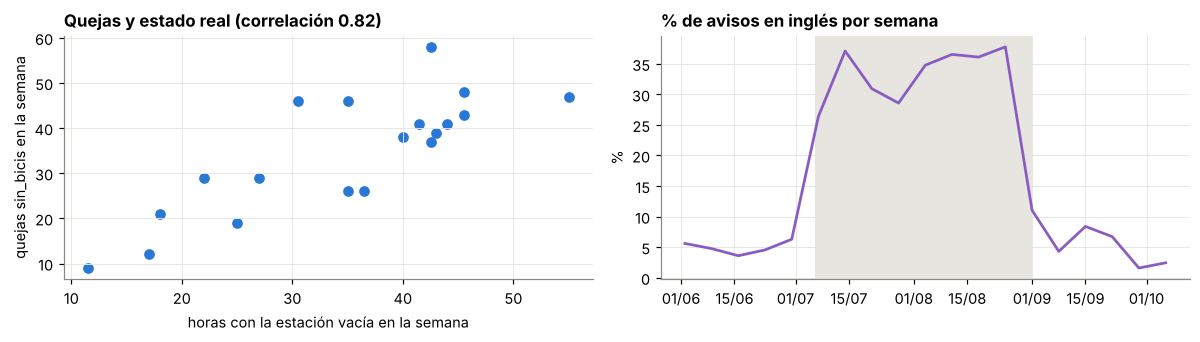

In [69]:
# ¿Siguen las quejas al estado real de la estación? Quejas de sin_bicis por semana frente a horas con la estación vacía
semana = lambda s: s.resample("W-SUN").sum()
quejas_sin = semana(avisos.set_index("momento")["causa"].eq("sin_bicis").astype(int))
horas_vacia = semana((flujo["bicis"] == 0).astype(float) * 0.5)
ingles = avisos.set_index("momento")["idioma"].eq("en").resample("W-SUN").mean() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
a1.scatter(horas_vacia.reindex(quejas_sin.index), quejas_sin, color=AZUL)
a1.set_xlabel("horas con la estación vacía en la semana")
a1.set_ylabel("quejas sin_bicis en la semana")
a1.set_title(f"Quejas y estado real (correlación {np.corrcoef(horas_vacia.reindex(quejas_sin.index).fillna(0), quejas_sin)[0, 1]:.2f})")
a2.plot(ingles.index - pd.Timedelta(days=3), ingles.values, color=MORADO, lw=1.8)
a2.axvspan(*VERANO, color=SOMBRA, lw=0, zorder=0)
a2.set_title("% de avisos en inglés por semana")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
a2.set_ylabel("%")
plt.tight_layout()
plt.show()

**Qué muestra el flujo de avisos:**
- **2.523 avisos, unos 20 al día.** Las clases están **desequilibradas**: `sin_bicis` (650), `estacion_llena` (590) y `averia` (576) son las más frecuentes; `averia_estacion` solo existe desde septiembre (128 avisos, casi la mitad durante la avería de la borne).
- **Las quejas siguen al estado real de la estación:** la correlación entre las quejas semanales por falta de bicis y las horas con *pomme* vacía es de **0,82**. Por meses, las quejas `sin_bicis` bajan en agosto (93) y suben en septiembre (180), igual que las alertas del flujo de sensores (del 33 % al 50 % del día, apartado 4.2). El flujo de texto hereda así los cambios reales de uso.
- **Idioma:** los avisos en inglés pasan del 5 % en junio al 29 % en julio y el 35 % en agosto, y vuelven al 5 % en septiembre. Es un *data drift* en el vocabulario que el modelo tendrá que absorber (H5).
- Las dos últimas hipótesis del apartado 2 salen de aquí: **H5** (el cambio de idioma se puede detectar sin etiquetas) y **H6** (la reorganización de categorías del 1 de septiembre es un *concept drift* al que un Naive Bayes sin olvido no se adapta).

### 4.8.3 Estrategia de evaluación del subsistema 2

- **Evaluación *prequential* con retraso:** el aviso se clasifica en cuanto llega y el modelo aprende de él cuando el operador le pone la categoría, **1 hora después**. Es el mismo esquema que en el flujo de sensores (apartado 4.3), con la función `prequential_texto`.
- **Métricas:** *accuracy* y, sobre todo, **F1 macro**: las clases están desequilibradas (`averia_estacion` es muy minoritaria) y la macro da el mismo peso a todas, de modo que un modelo que ignore la clase nueva queda penalizado. También el **error en los avisos de la borne después del 1 de septiembre**, que mide directamente la adaptación al *concept drift*.
- ***Baselines*:**
  - **Clase mayoritaria** (sin aprendizaje).
  - **Reglas de palabras clave**: lo que haría un operador sin aprendizaje automático. Las reglas se escriben con el vocabulario de junio (en francés e inglés) y **no se actualizan**: son el punto de referencia para saber si el aprendizaje online aporta algo.
- **Elección de hiperparámetros solo con junio** (el primer mes), para no usar información del futuro: así se elige la tasa de aprendizaje de la regresión logística.

In [70]:
# Baselines (reglas de palabras clave y clase mayoritaria) y bucle prequential de los avisos
def normalizar(texto):
    """Minúsculas y sin tildes (igual que hacen por defecto BagOfWords y TFIDF de River)."""
    return "".join(c for c in unicodedata.normalize("NFKD", texto.lower()) if not unicodedata.combining(c))


class ReglasPalabrasClave:
    """Baseline sin aprendizaje: reglas escritas con el vocabulario de junio, en orden de prioridad."""
    REGLAS = [
        ("estacion_llena", r"plein|complete|place libre|sature|full|free dock|docks|deposer|rendre"),
        ("sin_bicis", r"aucun velo|plus de velo|pas de velo|zero velo|vide|no bikes|empty|any bike|single bike|introuvable|aucun"),
        ("averia", r"borne|terminal|ecran|lecteur|cadenas|kiosk|card reader|attache|decroche|frein|chaine|pneu|selle|guidon|roue"
                   r"|lumiere|brake|tire|chain|seat|damaged|casse|abime"),
        ("app_pago", r"appli|application|paiement|carte|debite|preleve|code|connecter|\bapp\b|charged|declined|log in"),
    ]

    def predict_one(self, x):
        t = normalizar(x["texto"])
        return next((clase for clase, patron in self.REGLAS if re.search(patron, t)), "otro")

    def learn_one(self, x, y):
        pass


class Mayoritaria:
    def __init__(self):
        self.conteo = collections.Counter()

    def predict_one(self, x):
        return self.conteo.most_common(1)[0][0] if self.conteo else None

    def learn_one(self, x, y):
        self.conteo[y] += 1


def prequential_texto(modelo, avisos=None, retraso=RETRASO_AVISOS, detector=None, reiniciar=None, desde=pd.Timestamp("2016-06-15")):
    """Evaluación test-then-train de los avisos con la etiqueta retrasada `retraso`.
    detector: recibe el bit de error; si salta (desde la fecha `desde`) y `reiniciar` es una función, el modelo se sustituye.
    Devuelve (registro por aviso, fechas de drift)."""
    pendientes, registros, drifts = collections.deque(), [], []
    for x, y in (avisos if avisos is not None else flujo_avisos()):
        t = x["momento"]
        while pendientes and pendientes[0][0] + retraso <= t:          # 1) llegan las categorías de hace 1 hora
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, x0["idioma"], x0["causa"], y0, p0, error))
            if detector is not None:
                detector.update(error)
                if detector.drift_detected and t >= desde:
                    drifts.append(t)
                    if reiniciar is not None:
                        modelo = reiniciar()
            modelo.learn_one({"texto": x0["texto"]}, y0)
        xm = {"texto": x["texto"]}                                       # 2) llega un aviso: se clasifica
        pendientes.append((t, x, y, modelo.predict_one(xm)))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "idioma", "causa", "y", "y_pred", "error"])
    return registro.set_index("momento"), drifts


def resumen_texto(registro):
    acc, f1 = metrics.Accuracy(), metrics.MacroF1()
    for y, p in zip(registro["y"], registro["y_pred"]):
        acc.update(y, p if p is not None else "ninguna")
        f1.update(y, p if p is not None else "ninguna")
    despues = registro[registro.index >= REORGANIZACION]
    return {"accuracy (%)": round(100 * acc.get(), 1), "F1 macro (%)": round(100 * f1.get(), 1),
            "error antes del 1-sep (%)": round(100 * registro[registro.index < REORGANIZACION]["error"].mean(), 1),
            "error desde el 1-sep (%)": round(100 * despues["error"].mean(), 1),
            "error en avisos de la borne desde el 1-sep (%)": round(100 * despues[despues["causa"] == "averia_estacion"]["error"].mean(), 1)}

### 4.8.4 Elección razonada del clasificador de avisos

Igual que en el apartado 4.4, no probamos todos los clasificadores del tema: deducimos de las características del flujo cuál debería funcionar mejor y lo comprobamos.

**Qué exige el problema** (apartados 4.8.1 y 4.8.2):

| Característica del flujo | Qué exige al clasificador |
|---|---|
| Avisos cortos, con vocabulario reducido, erratas y a menudo sin tildes | representar el texto por sus **palabras**, normalizadas (minúsculas y sin tildes) |
| Unos 20 avisos al día: pocos ejemplos, sobre todo de las clases pequeñas | **aprender rápido**, aviso a aviso |
| Las categorías las decide el operador y **pueden cambiar** (en un servicio real aparecen tipos de incidencia nuevos o se reorganizan) | **olvidar** lo antiguo y **admitir clases nuevas** sin reentrenar desde cero |
| 6 clases desequilibradas | evaluar con **F1 macro**, no solo con *accuracy* |

**Candidatos del tema y razonamiento:**
- **Naive Bayes multinomial con bolsa de palabras.** Es la referencia clásica para texto [17] y la que propone el tema: aprende sumando conteos, así que es rápido y funciona con pocos datos. Va con **bolsa de palabras** porque interpreta los valores como conteos de palabras. Su punto débil, que el propio tema señala, es el tercer requisito: **no olvida**. Sus conteos acumulan todo el pasado, así que si una categoría cambia de significado seguirá decidiendo con la definición antigua. Las otras variantes del tema (Bernoulli, complementario) comparten esa limitación, así que no cambian el razonamiento.
- **Regresión logística One-vs-Rest con TF-IDF.** Cumple los tres requisitos: aprende aviso a aviso; el descenso por gradiente da más peso a los avisos recientes (**olvido implícito**); y `OneVsRestClassifier` **crea un clasificador nuevo** en cuanto aparece una categoría nueva. Va con **TF-IDF** porque, como todo modelo lineal entrenado por gradiente, necesita variables en una escala comparable (en los cuadernos del tema se usa `StandardScaler` por la misma razón), y TF-IDF normaliza cada aviso y da más peso a las palabras específicas.

**Hipótesis:** la regresión logística será el mejor clasificador, sobre todo después de que cambien las categorías; el Naive Bayes será competitivo mientras no haya cambios, pero necesitará un mecanismo de olvido (lo comprobamos en 4.8.6). Los dos deberían superar con claridad a las reglas de palabras clave.

**Cómo funcionan:**
- **De texto a variables.** `BagOfWords` convierte cada aviso en un diccionario {palabra: número de veces}. `TFIDF` da a cada palabra el valor tf · idf, donde tf es su frecuencia relativa en el aviso e idf = ln((1 + *N*) / (1 + *df*)) + 1, con *N* el número de avisos vistos y *df* en cuántos aparece la palabra: las palabras que salen en muchos avisos ("vélo", "station") pesan menos que las específicas ("pneu", "borne"). Después normaliza el vector para que su longitud sea 1. Ambos se actualizan aviso a aviso (el vocabulario y los *df* crecen con el flujo).
- **Naive Bayes multinomial.** Elige la categoría *c* que maximiza P(*c*) · Π P(*w* \| *c*)<sup>*n<sub>w</sub>*</sup>, donde *n<sub>w</sub>* es el número de veces que aparece la palabra *w*. Las probabilidades salen de **contadores** (avisos por categoría y palabras por categoría, con suavizado de Laplace `alpha=1` para las palabras no vistas). Aprender un aviso es sumar sus conteos: por eso es muy rápido y, también por eso, **no olvida** (4.8.6).
- **Regresión logística One-vs-Rest.** Un clasificador binario por categoría ("¿es `sin_bicis` o no?"), cada uno con un peso por palabra; se elige la categoría con mayor probabilidad. Los pesos se corrigen con **descenso por gradiente** en cada aviso: *w* ← *w* − η · (*p* − *y*) · *x*, donde η es la tasa de aprendizaje. Cuanto mayor es η, más pesa cada aviso nuevo frente a lo aprendido antes.

**Tasa de aprendizaje de la regresión logística, elegida solo con junio.** Con la tasa por defecto (0,01) la regresión logística aprende demasiado despacio para un flujo de unos 20 avisos al día. Probamos varias tasas y nos quedamos con la que tiene menos error **en junio**, sin mirar el resto del flujo:

In [71]:
# Tasa de aprendizaje de la regresión logística elegida SOLO con los avisos de junio
def regresion_logistica(lr):
    return (feature_extraction.TFIDF(on="texto")
            | multiclass.OneVsRestClassifier(linear_model.LogisticRegression(optimizer=optim.SGD(lr))))


junio = [(x, y) for x, y in flujo_avisos() if x["momento"] < pd.Timestamp("2016-07-01")]
error_junio = {}
for lr in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    reg, _ = prequential_texto(regresion_logistica(lr), junio)
    error_junio[lr] = round(100 * reg["error"].mean(), 1)
LR_ELEGIDA = min(error_junio, key=error_junio.get)
print("Error en junio según la tasa de aprendizaje (%):", error_junio)
print("Tasa elegida:", LR_ELEGIDA)

Error en junio según la tasa de aprendizaje (%): {0.01: np.float64(67.2), 0.1: np.float64(43.9), 0.5: np.float64(21.2), 1.0: np.float64(15.9), 2.0: np.float64(13.4), 5.0: np.float64(11.1), 10.0: np.float64(11.9)}
Tasa elegida: 5.0


**Qué vemos:** con la tasa por defecto (0,01) la regresión logística falla el 67 % de los avisos de junio: aprende demasiado despacio. El error baja hasta una tasa de 5 (11,1 %) y vuelve a subir con 10, así que elegimos **5**. Como la elección solo usa junio, el resto del flujo sigue siendo una evaluación limpia.

In [72]:
# Comprobación de la hipótesis: baselines, Naive Bayes multinomial y regresión logística (accuracy, F1 macro, error antes y después del cambio, tiempo y memoria)
MODELOS_TEXTO = {
    "Clase mayoritaria (baseline)": Mayoritaria,
    "Reglas de palabras clave (baseline)": ReglasPalabrasClave,
    "BagOfWords + MultinomialNB": lambda: feature_extraction.BagOfWords(on="texto") | naive_bayes.MultinomialNB(),
    f"TFIDF + regresión logística OvR (lr={LR_ELEGIDA})": lambda: regresion_logistica(LR_ELEGIDA),
}
registros_texto, filas = {}, {}
for nombre, fab in MODELOS_TEXTO.items():
    t0 = time.time()
    modelo = fab()
    registros_texto[nombre], _ = prequential_texto(modelo)
    filas[nombre] = {**resumen_texto(registros_texto[nombre]),
                     "ms/aviso": round(1000 * (time.time() - t0) / len(registros_texto[nombre]), 2),
                     "memoria (KB)": memoria_kb(modelo)}
tabla_texto = pd.DataFrame(filas).T
tabla_texto

,accuracy (%),F1 macro (%),error antes del 1-sep (%),error desde el 1-sep (%),error en avisos de la borne desde el 1-sep (%),ms/aviso,memoria (KB)
Clase mayoritaria (baseline),25.4,8.6,74.8,74.2,99.2,0.11,NaN
Reglas de palabras clave (baseline),80.5,69.8,14.9,32.7,98.5,0.13,NaN
BagOfWords + MultinomialNB,89.3,71.1,8.6,16.6,72.3,0.48,213.9
TFIDF + regresión logística OvR (lr=5.0),94.1,80.0,5.9,5.9,16.2,0.27,34.0


In [73]:
# F1 por clase de los dos clasificadores y de las reglas
def f1_clases(registro):
    """F1 de cada categoría (uno contra el resto) sobre todo el flujo."""
    salida = {}
    for c in ["sin_bicis", "estacion_llena", "averia", "averia_estacion", "app_pago", "otro"]:
        vp = ((registro["y"] == c) & (registro["y_pred"] == c)).sum()
        fp = ((registro["y"] != c) & (registro["y_pred"] == c)).sum()
        fn = ((registro["y"] == c) & (registro["y_pred"] != c)).sum()
        salida[c] = round(100 * 2 * vp / (2 * vp + fp + fn), 1) if vp + fp + fn else np.nan
    return salida


NB_TEXTO = "BagOfWords + MultinomialNB"
LR_TEXTO = f"TFIDF + regresión logística OvR (lr={LR_ELEGIDA})"
pd.DataFrame({n: f1_clases(registros_texto[n]) for n in ["Reglas de palabras clave (baseline)", NB_TEXTO, LR_TEXTO]})

,Reglas de palabras clave (baseline),BagOfWords + MultinomialNB,TFIDF + regresión logística OvR (lr=5.0)
sin_bicis,84.1,93.1,95.5
estacion_llena,83.7,92.4,95.0
averia,78.6,86.0,93.9
averia_estacion,0.0,42.7,89.7
app_pago,95.6,91.6,93.5
otro,76.7,92.1,92.3


**Conclusión: se confirma la hipótesis. La regresión logística es el mejor clasificador y el Naive Bayes no se adapta al cambio de categorías.**
- **Los dos modelos superan claramente a las reglas** (80,5 %, F1 macro 69,8 %). Las reglas funcionan con lo que tiene un vocabulario muy característico (`app_pago`, 95,6 % de F1, mejor incluso que los modelos), pero no aprenden: siguen enviando la borne a `averia` después del 1 de septiembre (F1 de `averia_estacion` = 0) y su error pasa del 14,9 % al 32,7 %.
- **Regresión logística con TF-IDF: 94,1 % y F1 macro 80,0 %.** Es mejor que el Naive Bayes en todas las clases, y la diferencia está donde predecía el razonamiento: en los avisos de la borne después de la reorganización solo falla el 16,2 %, y su error global es el mismo antes y después del 1 de septiembre (5,9 %). Además es la más ligera (34 KB) y la más rápida (0,26 ms por aviso).
- **Naive Bayes multinomial: 89,3 % y F1 macro 71,1 %.** Antes del cambio es competitivo (8,6 % de error), pero después sigue enviando a `averia` el **72,3 %** de los avisos de la borne (F1 de `averia_estacion` = 42,7 %): es justo la limitación de no olvidar que anticipábamos. En 4.8.6 comprobamos si un mecanismo de olvido lo arregla.
- La F1 macro no pasa del 80 % en ningún modelo: el 3 % de etiquetas mal puestas, los textos ambiguos ("borne" aparece en varias clases) y la clase nueva, con pocos ejemplos, ponen un techo.

### 4.8.5 *Data drift* en los avisos (H5): detectarlo sin etiquetas

Las categorías llegan con retraso y, en un sistema real, no siempre (muchos avisos nunca se etiquetan). Por eso interesa vigilar **señales que no necesitan etiquetas**, igual que en el apartado 4.6:

1. **Idioma de los avisos.** Un indicador por aviso (1 = inglés), calculado con una regla simple: el aviso tiene más palabras vacías inglesas (*the, is, my…*) que francesas (*le, la, de…*). No usa la columna `idioma` del generador. Se vigila con **ADWIN** (cambios en la media) y **Page-Hinkley** (subidas y bajadas).
2. **Proporción de avisos clasificados como `app_pago`.** Un indicador por aviso con la **predicción** del modelo (no la etiqueta): una subida brusca indica un problema técnico, y detectarlo sin esperar a que el operador lea los avisos permite reaccionar antes. Se vigila con ADWIN.

In [74]:
# H5: señales sin etiquetas (idioma de cada aviso y proporción de avisos clasificados como app_pago) vigiladas con detectores
PALABRAS_EN = {"the", "is", "no", "not", "my", "i", "at", "to", "any", "was", "where", "how", "please", "thanks",
               "can't", "couldn't", "won't", "don't", "doesn't", "all", "a", "had", "there", "it", "in", "for", "you"}
PALABRAS_FR = {"le", "la", "les", "de", "du", "des", "je", "pas", "plus", "est", "a", "une", "un", "il", "mon", "ma",
               "sur", "pour", "ne", "que", "en", "et", "c'est", "j'ai", "on", "ce", "se", "au"}


def parece_ingles(texto):
    """Detector de idioma sin etiquetas: ¿más palabras vacías inglesas que francesas?"""
    palabras = re.findall(r"[a-z']+", normalizar(texto))
    return int(sum(w in PALABRAS_EN for w in palabras) > sum(w in PALABRAS_FR for w in palabras))


senal_idioma = pd.Series([parece_ingles(x["texto"]) for x, _ in flujo_avisos()], index=avisos["momento"])
print(f"La regla acierta el idioma en el {100 * (senal_idioma.values == (avisos['idioma'] == 'en').values).mean():.1f} % de los avisos")

def detectar(detector, serie):
    """Pasa una serie por un detector y devuelve los momentos en que detecta un cambio."""
    fechas = []
    for t, v in serie.items():
        detector.update(v)
        if detector.drift_detected:
            fechas.append(t)
    return fechas


detecciones_idioma = {"ADWIN": detectar(drift.ADWIN(), senal_idioma),
                      "Page-Hinkley (both)": detectar(drift.PageHinkley(mode="both"), senal_idioma)}
for nombre, fechas in detecciones_idioma.items():
    print(f"{nombre:20s}: " + ", ".join(f"{t:%d-%m %H:%M}" for t in fechas))

# Proporción de avisos clasificados como app_pago por el modelo (sin etiqueta)
reg_lr = registros_texto[LR_TEXTO]
senal_app = (reg_lr["y_pred"] == "app_pago").astype(int)
detecciones_app = detectar(drift.ADWIN(), senal_app)
print("ADWIN sobre la proporción de avisos clasificados como app_pago: " + ", ".join(f"{t:%d-%m %H:%M}" for t in detecciones_app))

La regla acierta el idioma en el 98.9 % de los avisos
ADWIN               : 08-07 16:35, 06-09 21:55
Page-Hinkley (both) : 12-07 18:52, 11-09 00:36
ADWIN sobre la proporción de avisos clasificados como app_pago: 21-07 23:32


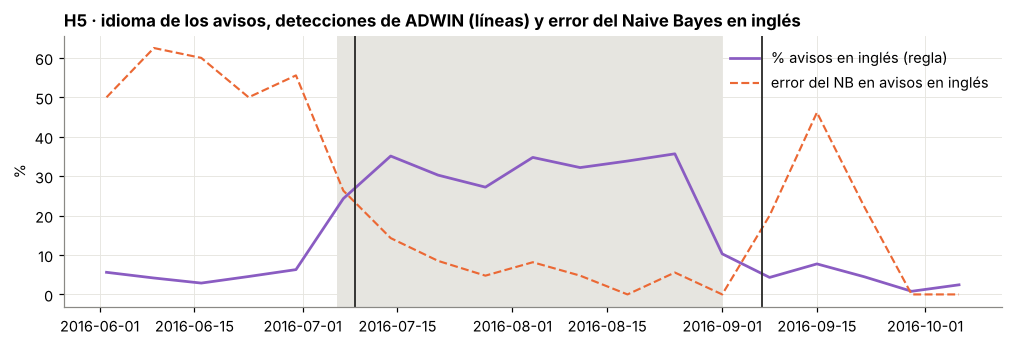

BagOfWords + MultinomialNB       TFIDF + regresión logística OvR (lr=5.0)      avisos en inglés
idioma                         en    fr                                       en   fr                n
jun                          56.7  13.0                                     43.3  9.5               30
jul                          13.9   4.1                                      5.3  2.8              187
ago                           4.4   3.2                                      3.4  2.7              205
sep                          28.1  17.2                                     21.9  5.1               32
oct                           0.0   6.8                                      0.0  5.5                1

In [75]:
# ¿Afecta el inglés a los modelos? Error por idioma y mes
error_idioma = pd.concat({n: registros_texto[n].groupby([registros_texto[n].index.month, "idioma"])["error"].mean().unstack() * 100
                          for n in [NB_TEXTO, LR_TEXTO]}, axis=1).round(1)
error_idioma.index = ["jun", "jul", "ago", "sep", "oct"]
n_ingles = avisos[avisos["idioma"] == "en"].groupby(avisos["momento"].dt.month).size()
error_idioma[("avisos en inglés", "n")] = n_ingles.values

fig, ax = plt.subplots(figsize=(11, 3.2))
semanal_en = senal_idioma.resample("W-SUN").mean() * 100
ax.plot(semanal_en.index - pd.Timedelta(days=3), semanal_en.values, color=MORADO, lw=1.8, label="% avisos en inglés (regla)")
err_en = registros_texto[NB_TEXTO].query("idioma == 'en'")["error"].resample("W-SUN").mean() * 100
ax.plot(err_en.index - pd.Timedelta(days=3), err_en.values, color=NARANJA, lw=1.4, ls="--", label="error del NB en avisos en inglés")
for t in detecciones_idioma["ADWIN"]:
    ax.axvline(t, color=TINTA, lw=1.2)
ax.axvspan(*VERANO, color=SOMBRA, lw=0, zorder=0)
ax.set_title("H5 · idioma de los avisos, detecciones de ADWIN (líneas) y error del Naive Bayes en inglés")
ax.set_ylabel("%")
ax.legend(frameon=False, loc="upper right")
plt.show()
error_idioma

**Conclusión (H5): confirmada.** El cambio de idioma se detecta **sin ninguna etiqueta**:
- La regla de palabras vacías acierta el idioma en el 98,9 % de los avisos. Sobre ella, **ADWIN detecta la llegada de los turistas el 8 de julio** (2 días después del inicio de las vacaciones) y **su marcha el 6 de septiembre** (5 días después), sin falsas alarmas. Page-Hinkley detecta lo mismo, pero más tarde (12 de julio y 11 de septiembre).
- **El *data drift* no obliga a reentrenar:** con los pocos avisos en inglés de junio el Naive Bayes falla el 57 % (30 avisos), pero cuando llegan en volumen aprende solo: su error en inglés baja al 14 % en julio y al 4 % en agosto (la regresión logística, al 5 % y al 3 %). Como en el flujo de sensores (apartado 4.6), el detector de *data drift* sirve para **avisar de un cambio de comportamiento** (por ejemplo, para activar respuestas en inglés), no para reentrenar.
- **Caída de la aplicación (21 de julio):** ADWIN sobre la proporción de avisos que el modelo clasifica como `app_pago` la detecta **el mismo día sin esperar a las etiquetas**, pero a las 23:32, cuando la caída llevaba horas: ADWIN necesita acumular evidencia en una señal con solo ~20 avisos al día. Para incidencias así sería mejor vigilar el número de avisos de cada tipo por hora (lo dejamos como mejora).

### 4.8.6 *Concept drift* en los avisos (H6): la reorganización de categorías

Desde el 1 de septiembre los avisos sobre la borne, el lector de tarjetas o los anclajes pasan a ser `averia_estacion`. Los textos son los mismos de siempre: lo que cambia es **la categoría que les corresponde**. Para un Naive Bayes, que acumula conteos desde junio, "borne" lleva tres meses asociado a `averia`, y su memoria no se borra sola: el tema lo indica expresamente (*"no olvida automáticamente datos viejos, a menos que se usen mecanismos de olvido"*, que en River hay que programar).

**Detectores sobre el error del Naive Bayes.** Igual que en el apartado 4.7, medimos cuándo salta cada detector y cuántas falsas alarmas da antes del cambio.

In [76]:
# H6: detectores de concept drift sobre el error del Naive Bayes
reg_nb = registros_texto[NB_TEXTO]
errores_nb = list(zip(reg_nb["revelada"], reg_nb["error"]))
borne = avisos[avisos["causa"] == "averia_estacion"]["momento"]
print(f"Avisos de averías de la estación entre el 1 y el 11 de septiembre: {((borne >= REORGANIZACION) & (borne < AVERIA_BORNE[0])).sum()}; "
      f"durante la avería de la borne (12-14 sep): {((borne >= AVERIA_BORNE[0]) & (borne < AVERIA_BORNE[1])).sum()}")
FABRICAS_DET_TEXTO = {"DDM": drift.binary.DDM, "EDDM": drift.binary.EDDM, "HDDM_A": drift.binary.HDDMA,
                      "HDDM_W": drift.binary.HDDMW, "Page-Hinkley": lambda: drift.PageHinkley(mode="up"), "ADWIN": drift.ADWIN}
meses_antes_texto = (REORGANIZACION - pd.Timestamp("2016-06-15")).days / 30.4
filas = {}
for nombre, fab in FABRICAS_DET_TEXTO.items():
    det, fechas = fab(), []
    for t, e in errores_nb:
        det.update(e)
        if det.drift_detected and t >= pd.Timestamp("2016-06-15"):
            fechas.append(t)
    despues = [t for t in fechas if t >= REORGANIZACION]
    filas[nombre] = {"falsas alarmas antes del 1-sep (por mes)": round(len([t for t in fechas if t < REORGANIZACION]) / meses_antes_texto, 1),
                     "primera detección desde el 1-sep": f"{despues[0]:%d-%m %H:%M}" if despues else "—",
                     "retardo (días)": round((despues[0] - REORGANIZACION).total_seconds() / 86400, 1) if despues else np.nan,
                     "todas las detecciones": ", ".join(f"{t:%d-%m}" for t in fechas) or "—"}
pd.DataFrame(filas).T

Avisos de averías de la estación entre el 1 y el 11 de septiembre: 30; durante la avería de la borne (12-14 sep): 56


,falsas alarmas antes del 1-sep (por mes),primera detección desde el 1-sep,retardo (días),todas las detecciones
DDM,0.0,12-09 19:30,11.8,12-09
EDDM,0.0,12-09 13:44,11.6,12-09
HDDM_A,0.0,12-09 19:00,11.8,12-09
HDDM_W,0.0,12-09 18:10,11.8,12-09
Page-Hinkley,0.0,14-09 13:29,13.6,14-09
ADWIN,0.4,12-09 15:29,11.6,"20-06, 12-09, 21-09"


**Qué vemos:** entre el 1 y el 11 de septiembre llegan solo 30 avisos de la clase que cambia (unos 3 al día entre 20), y durante la avería de la borne, 56 en tres días. Todos los detectores saltan el **12 de septiembre**, cuando llega la avalancha, y no antes; casi no dan falsas alarmas. Lo analizamos en la conclusión de este apartado.

**Estrategias de adaptación para el Naive Bayes.** Además de no hacer nada, probamos los mecanismos de olvido del tema:
- **Reinicio con un detector:** cuando el detector salta, el modelo se sustituye por uno nuevo (con ADWIN y con HDDM_A).
- **Factor de olvido (*fading factor*), programado por nosotros** (conteo ← λ · conteo antes de sumar cada aviso nuevo, así que un aviso visto hace *k* avisos pesa λ<sup>*k*</sup>): antes de aprender cada aviso, todos los conteos del Naive Bayes se multiplican por λ < 1, de modo que los avisos antiguos pesan cada vez menos. Con λ = 0,998 la "memoria" efectiva es de unos 1 / (1 − λ) = 500 avisos, unas **3-4 semanas** con nuestro volumen: suficiente para no olvidar las clases poco frecuentes y a la vez reaccionar en semanas. Mostramos también la sensibilidad a λ.
- **Oráculo:** el modelo se reinicia justo el 1 de septiembre (referencia de lo mejor que puede hacer un reinicio; en la realidad no se conoce la fecha… aunque aquí el operador sí sabría cuándo reorganiza sus categorías, lo que comentamos en las conclusiones).
- **Regresión logística (olvido implícito):** el descenso por gradiente corrige los pesos con cada aviso nuevo, así que lo reciente pesa más sin necesidad de programar nada.

In [77]:
# H6: estrategias de adaptación del Naive Bayes (reinicio, factor de olvido, oráculo) y regresión logística
class MultinomialNBConOlvido(naive_bayes.MultinomialNB):
    """MultinomialNB con factor de olvido: antes de aprender cada aviso, todos los conteos se multiplican por `olvido`."""

    def __init__(self, alpha=1.0, olvido=0.998):
        super().__init__(alpha=alpha)
        self.olvido = olvido

    def learn_one(self, x, y):
        for conteos in (self.class_counts, self.class_totals, *self.feature_counts.values()):
            for clase in conteos:
                conteos[clase] *= self.olvido
        super().learn_one(x, y)


def nb_texto():
    return feature_extraction.BagOfWords(on="texto") | naive_bayes.MultinomialNB()


def prequential_oraculo():
    """Como prequential_texto, pero el modelo se sustituye por uno nuevo el 1 de septiembre."""
    modelo, filas_o, pendientes, hecho = nb_texto(), [], collections.deque(), False
    for x, y in flujo_avisos():
        t = x["momento"]
        if not hecho and t >= REORGANIZACION:
            modelo, hecho = nb_texto(), True
        while pendientes and pendientes[0][0] + RETRASO_AVISOS <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            filas_o.append((t0, t, x0["idioma"], x0["causa"], y0, p0, int(p0 != y0)))
            modelo.learn_one({"texto": x0["texto"]}, y0)
        pendientes.append((t, x, y, modelo.predict_one({"texto": x["texto"]})))
    return pd.DataFrame(filas_o, columns=["momento", "revelada", "idioma", "causa", "y", "y_pred", "error"]).set_index("momento")


estrategias_texto, registros_estr_texto = {}, {}
estrategias_texto["Naive Bayes sin olvido"], registros_estr_texto["sin olvido"] = resumen_texto(reg_nb), reg_nb
for nombre, fab in {"ADWIN": drift.ADWIN, "HDDM_A": drift.binary.HDDMA}.items():
    reg, fechas = prequential_texto(nb_texto(), detector=fab(), reiniciar=nb_texto)
    estrategias_texto[f"Naive Bayes + reinicio con {nombre}"] = {**resumen_texto(reg), "reinicios": len(fechas)}
    registros_estr_texto[f"reinicio {nombre}"] = reg
for olvido in [0.999, 0.998, 0.995, 0.99]:
    reg, _ = prequential_texto(feature_extraction.BagOfWords(on="texto") | MultinomialNBConOlvido(olvido=olvido))
    estrategias_texto[f"Naive Bayes + factor de olvido λ={olvido}"] = resumen_texto(reg)
    registros_estr_texto[f"olvido {olvido}"] = reg
reg = prequential_oraculo()
estrategias_texto["Naive Bayes + oráculo (reinicio el 1-sep)"], registros_estr_texto["oráculo"] = resumen_texto(reg), reg
estrategias_texto[f"Regresión logística OvR (lr={LR_ELEGIDA})"], registros_estr_texto["regresión logística"] = resumen_texto(reg_lr), reg_lr
tabla_estrategias_texto = pd.DataFrame(estrategias_texto).T
tabla_estrategias_texto

,accuracy (%),F1 macro (%),error antes del 1-sep (%),error desde el 1-sep (%),error en avisos de la borne desde el 1-sep (%),reinicios
Naive Bayes sin olvido,89.3,71.1,8.6,16.6,72.3,NaN
Naive Bayes + reinicio con ADWIN,79.3,67.4,22.0,17.0,36.9,5.0
Naive Bayes + reinicio con HDDM_A,87.8,72.6,8.6,22.2,41.5,1.0
Naive Bayes + factor de olvido λ=0.999,89.4,73.3,9.6,13.5,53.8,NaN
Naive Bayes + factor de olvido λ=0.998,88.7,74.2,10.4,13.7,40.0,NaN
Naive Bayes + factor de olvido λ=0.995,81.9,69.0,16.9,21.6,29.2,NaN
Naive Bayes + factor de olvido λ=0.99,72.0,60.2,26.1,33.3,36.2,NaN
Naive Bayes + oráculo (reinicio el 1-sep),89.1,75.9,8.6,17.2,16.2,NaN
Regresión logística OvR (lr=5.0),94.1,80.0,5.9,5.9,16.2,NaN


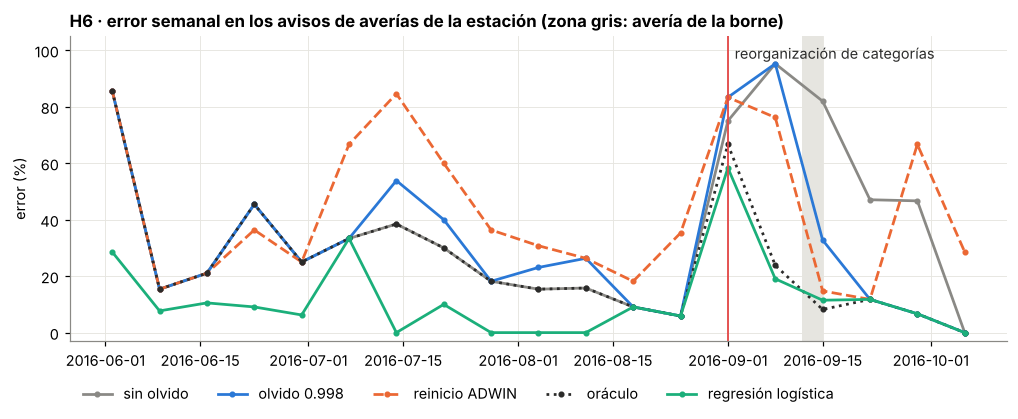

In [78]:
# Error semanal en los avisos de averías de la estación con cada estrategia
fig, ax = plt.subplots(figsize=(11, 3.6))
for nombre, color, ls in [("sin olvido", GRIS, "-"), ("olvido 0.998", AZUL, "-"), ("reinicio ADWIN", NARANJA, "--"),
                          ("oráculo", TINTA, ":"), ("regresión logística", VERDE, "-")]:
    r = registros_estr_texto[nombre]
    s = r[r["causa"] == "averia_estacion"]["error"].resample("W-SUN").mean() * 100
    ax.plot(s.index - pd.Timedelta(days=3), s.values, color=color, ls=ls, lw=1.8, marker="o", ms=3, label=nombre)
ax.axvline(REORGANIZACION, color=ROJO, lw=1.2)
ax.axvspan(*AVERIA_BORNE, color=SOMBRA, lw=0, zorder=0)
ax.text(REORGANIZACION + pd.Timedelta(days=1), 102, "reorganización de categorías", color=TINTA, va="top")
ax.set_ylim(-3, 105)
ax.set_title("H6 · error semanal en los avisos de averías de la estación (zona gris: avería de la borne)")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, ncol=5, loc="upper left", bbox_to_anchor=(0, -0.1))
plt.show()

**Conclusión (H6): confirmada, y la regresión logística es la que mejor se adapta.**
- **El Naive Bayes sin olvido no se adapta:** después del 1 de septiembre sigue enviando a `averia` el **72 %** de los avisos de la borne. Tres meses de conteos asocian "borne", "lecteur" o "écran" a `averia`, y los 30 avisos con la categoría nueva que llegan del 1 al 11 de septiembre no bastan para cambiarlo.
- **Los detectores llegan tarde, y no por ser malos:** todos detectan el cambio el **12 de septiembre** (11,6-11,8 días después; Page-Hinkley, el 14), justo cuando empieza la avería de la borne y llegan 56 avisos de la clase nueva en tres días. Antes, con unos 3 avisos afectados al día entre 20, el error global apenas sube. **Un *concept drift* que afecta a una clase minoritaria se ve tarde en el error global.** Ninguno da falsas alarmas, salvo ADWIN el 20 de junio, al principio del flujo.
- **Reiniciar el Naive Bayes es caro:** el reinicio con ADWIN se dispara ya el 20 de junio (5 reinicios en total) y deja la *accuracy* en el 79,3 %, por debajo de no hacer nada. Incluso el **oráculo**, que reinicia justo el 1 de septiembre, empeora el error global después del cambio (17,2 % frente al 16,6 %): al reiniciar olvida **todas** las clases, no solo la que ha cambiado.
- **El factor de olvido (λ = 0,998) es el mejor compromiso para el Naive Bayes:** baja el error en la borne del 72 % al 40 % y sube la F1 macro de 71,1 % a 74,2 %, a cambio de 1,8 puntos más de error antes del cambio (olvida algo de las clases poco frecuentes). La sensibilidad confirma la elección: con λ = 0,999 olvida demasiado despacio (54 % de error en la borne) y con 0,995 o 0,99 olvida demasiado (el error antes del cambio sube al 17 % y al 26 %).
- **La regresión logística se adapta sola:** falla el 16,2 % de los avisos de la borne (como el oráculo) sin detector ni olvido programado, y sin perder nada en el resto (5,9 % de error después del cambio). El descenso por gradiente corrige los pesos con cada aviso (el pasado pesa cada vez menos: un olvido implícito), y `OneVsRestClassifier` crea el clasificador de la clase nueva en cuanto aparece.

### 4.8.7 Elección del clasificador de avisos

Se confirma la hipótesis del apartado 4.8.4: elegimos **TF-IDF + regresión logística One-vs-Rest** (tasa de aprendizaje 5, elegida solo con junio) como clasificador de avisos:
- es el más preciso (94,1 %, F1 macro 80,0 %) y supera a las reglas en 13,6 puntos;
- se adapta a la reorganización de categorías **sin detector ni reinicio**, que era el requisito que descartaba al Naive Bayes;
- es el más ligero (34 KB) y el más rápido (0,26 ms por aviso).

Junto a él dejamos dos vigilantes **sin etiquetas**: ADWIN sobre el idioma de los avisos (cambio de público) y ADWIN sobre la proporción de avisos de `app_pago` (incidencias técnicas). Si se prefiriera un Naive Bayes, por ser más interpretable y no necesitar ajustar la tasa de aprendizaje, debería llevar **factor de olvido** (λ ≈ 0,998), no reinicios con detector.

## 4.9 Unión de los dos subsistemas: ¿llega la alerta antes que las quejas?

La *accuracy* del apartado 4.4 trata igual todas las medias horas, también las de madrugada, cuando nadie usa la estación. Pero lo que importa al operador es **lo que sufren los usuarios**. El flujo de avisos permite medirlo: para cada **queja por falta de bicis**, comprobamos si el sistema de alerta había emitido la alerta **2 horas antes** para esa media hora, es decir, si el operador habría tenido margen para reponer bicis antes de que el usuario llegara.

Se usa la causa real de cada aviso (la verdad del generador). Comparamos el ARF (10 semillas, apartado 4.4) con la persistencia.

In [79]:
# Unión de los dos flujos: ¿cuántas quejas por falta de bicis llegan con la alerta emitida 2 horas antes?
quejas = avisos[(avisos["causa"] == "sin_bicis")].copy()
quejas["media_hora"] = quejas["momento"].dt.ceil("30min")                      # instancia del flujo de sensores
quejas["prediccion_hecha"] = quejas["media_hora"] - HORIZONTE                  # alerta emitida 2 h antes para esa media hora
quejas = quejas[quejas["prediccion_hecha"] >= INICIO_EVALUACION]


def cobertura(registro):
    """% de quejas que llegan con la alerta emitida 2 horas antes, y alertas emitidas por día."""
    alerta = registro["y_pred"].astype(bool)
    avisadas = alerta.reindex(quejas["prediccion_hecha"]).fillna(False).values
    dias = (registro.index.max() - INICIO_EVALUACION).days
    return 100 * avisadas.mean(), alerta[alerta.index >= INICIO_EVALUACION].sum() / dias, avisadas


cob_arf = {s: cobertura(r) for s, r in reg_semillas.items()}
cob_pers = cobertura(registros["Persistencia"])
tabla_cobertura = pd.DataFrame({
    "ARF (media de 10 semillas)": {"% de quejas con alerta 2 h antes": np.mean([c[0] for c in cob_arf.values()]),
                                   "alertas emitidas por día (medias horas)": np.mean([c[1] for c in cob_arf.values()])},
    "Persistencia": {"% de quejas con alerta 2 h antes": cob_pers[0], "alertas emitidas por día (medias horas)": cob_pers[1]},
}).T.round(1)
print(f"{len(quejas)} quejas por falta de bicis desde el 15 de junio")
tabla_cobertura

533 quejas por falta de bicis desde el 15 de junio


,% de quejas con alerta 2 h antes,alertas emitidas por día (medias horas)
ARF (media de 10 semillas),53.4,19.0
Persistencia,49.7,20.0


In [80]:
# ¿Cuándo llegan las quejas que no se anticipan?
quejas["avisada_arf"] = np.mean([c[2] for c in cob_arf.values()], axis=0) >= 0.5
quejas["franja"] = pd.cut(quejas["momento"].dt.hour, [0, 7, 10, 14, 18, 24], right=False,
                          labels=["0-7 h", "7-10 h", "10-14 h", "14-18 h", "18-24 h"])
quejas["bicis 2 h antes"] = flujo["bicis"].reindex(quejas["prediccion_hecha"]).values
por_franja = quejas.groupby("franja", observed=True).agg(quejas=("texto", "size"),
                                                          pct_con_alerta=("avisada_arf", lambda s: round(100 * s.mean(), 1)),
                                                          bicis_medias_2h_antes=("bicis 2 h antes", lambda s: round(s.mean(), 1)))
por_franja

,quejas,pct_con_alerta,bicis_medias_2h_antes
franja,,,
0-7 h,189,96.8,1.9
7-10 h,53,71.7,0.8
10-14 h,41,12.2,4.4
14-18 h,51,2.0,7.9
18-24 h,199,30.2,9.0


**¿Se puede anticipar más quejas?** El ARF emite la alerta cuando la probabilidad de quedarse con 2 bicis o menos supera 0,5. Pero para el operador no cuesta lo mismo una alerta de más (un desplazamiento del camión que quizá no hacía falta) que una de menos (usuarios sin bici). Bajar el umbral de decisión anticipa más quejas a cambio de más alertas. Lo medimos con las probabilidades del ARF (10 semillas):

In [81]:
# Efecto del umbral de decisión del ARF sobre las quejas anticipadas y el número de alertas
def prequential_probabilidad(modelo, instancias, retraso=HORIZONTE):
    """Como prequential, pero guarda la probabilidad de alerta que da el modelo en lugar de la clase."""
    pendientes, filas_p = collections.deque(), []
    for x, y in instancias:
        t = x["momento"]
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            filas_p.append((t0, y0, p0))
            modelo.learn_one(x0, y0)
        xm = variables_modelo(x)
        pendientes.append((t, xm, y, modelo.predict_proba_one(xm).get(True, 0.0)))
    return pd.DataFrame(filas_p, columns=["momento", "y", "proba"]).set_index("momento")


t0 = time.time()
probas_arf = {s: prequential_probabilidad(forest.ARFClassifier(n_models=10, seed=s), flujo_bicis()) for s in SEMILLAS}
filas = {}
for umbral in [0.5, 0.4, 0.3, 0.2]:
    medidas = []
    for r in probas_arf.values():
        pred = r["proba"] >= umbral
        cob, alertas_dia, _ = cobertura(pd.DataFrame({"y_pred": pred}, index=r.index))
        medidas.append((cob, alertas_dia, 100 * (pred == r["y"].astype(bool)).mean()))
    filas[f"ARF, umbral {umbral}"] = dict(zip(["% de quejas con alerta 2 h antes", "alertas emitidas por día (medias horas)",
                                               "accuracy (%)"], np.mean(medidas, axis=0)))
filas["Persistencia"] = {**tabla_cobertura.loc["Persistencia"].to_dict(),
                         "accuracy (%)": 100 * (1 - registros["Persistencia"]["error"].mean())}
print(f"{time.time() - t0:.0f} s")
tabla_umbral = pd.DataFrame(filas).T.round(1)
tabla_umbral

116 s


,% de quejas con alerta 2 h antes,alertas emitidas por día (medias horas),accuracy (%)
"ARF, umbral 0.5",53.4,19.0,82.2
"ARF, umbral 0.4",66.0,22.7,80.8
"ARF, umbral 0.3",77.8,27.1,77.1
"ARF, umbral 0.2",87.7,32.1,70.9
Persistencia,49.7,20.0,75.3


**Conclusión: el sistema de alerta anticipa la mitad de las quejas, y no las que más importan.**
- De las 533 quejas por falta de bicis desde el 15 de junio, **el ARF había emitido la alerta 2 horas antes en el 53,4 %**, y la persistencia en el 49,7 %. Los 7 puntos de *accuracy* que el ARF saca a la persistencia se quedan en **3,7 puntos en los momentos en que hay usuarios afectados**.
- **Por franjas:** las quejas de madrugada (0-7 h) se anticipan casi siempre (97 %), porque la estación lleva toda la noche vacía; las de 7-10 h, el 72 %. Pero las de **10-14 h (12 %) y 14-18 h (2 %) casi nunca**: son vaciados inesperados durante el día, cuando 2 horas antes había de 4 a 8 bicis. El modelo aprende el comportamiento medio, y en el apartado 4.2 vimos que las alertas casi desaparecen entre las 7:30 y las 17:00, así que esos vaciados son situaciones poco frecuentes.
- **El umbral de decisión es una decisión de negocio.** Con el umbral por defecto (0,5) el ARF da 19 medias horas de alerta al día. Bajándolo a **0,3**, anticipa el **78 %** de las quejas a cambio de un 42 % más de alertas (27 al día), y su *accuracy* (77,1 %) sigue por encima de la persistencia. Con 0,2 llegaría al 88 %, pero con 32 alertas al día y una *accuracy* peor que la persistencia. Para el operador recomendamos **0,3**: una alerta de más cuesta un desplazamiento del camión, y una de menos, usuarios sin bici.
- **Lo que enseña la unión de los dos flujos:** la *accuracy* trata igual todas las medias horas, también las de madrugada sin usuarios. Medida desde los usuarios, la calidad del sistema es otra, y el umbral que conviene no es el que maximiza la *accuracy*. Sin el flujo de avisos esta conclusión no se podría sacar.
- **Cautela:** las quejas son sintéticas, aunque se generan a partir del estado real de la estación; las cifras absolutas dependen de las intensidades supuestas, pero el patrón por franjas lo marca el flujo real de sensores. Además, el umbral de 0,3 se ha elegido mirando todo el periodo: en un sistema real habría que fijarlo con un periodo anterior.

# 5. Resultados

### 5.1 Subsistema 1: alerta de estación sin bicis (flujo real de sensores)

| Pregunta | Resultado |
|---|---|
| ¿El flujo está bien construido? | Sí: 5.980 instancias regulares de 30 minutos, sin fugas del futuro. Con las lecturas tal cual, DDM daba 165 falsas alarmas en 4 meses; con el flujo regular, 1 |
| ¿Qué horizonte? | 2 horas: a 30 minutos ningún modelo supera a la persistencia (−0,5 puntos); a 2 horas, el ARF le saca 7 |
| ¿Importa el retraso de la etiqueta? | Sí: ignorarlo infla la *accuracy* en 1,8 puntos |
| Modelo elegido | **ARF**, elegido razonando sobre el problema (no linealidad, adaptación, estabilidad, probabilidades) y confirmado: **82,2 % de *accuracy*** (media de 10 semillas; 78,8 % de F1) frente al 80,3 % del Hoeffding Tree, el 80,0 % de la regresión logística y el 75,3 % de la persistencia |
| Coste | ARF: unos 2 ms por instancia y 24 MB de memoria; Hoeffding Tree: 0,2 ms y 0,3 MB |
| *Concept drift* en el flujo real | Muy leve, solo en agosto (+1,2 puntos de error del modelo congelado); el ARF online lo absorbe y ningún detector lo detecta de forma fiable |
| *Data drift* en el flujo real | El uso baja en vacaciones y se recupera en septiembre: KSWIN lo detecta el 20 de julio y el 6 de septiembre, pero solo desestacionalizando, agregando por día y ajustando parámetros |
| Detectores ante un cambio conocido | HDDM_A el más rápido (2,9 días, 2,1 falsas alarmas al mes); ADWIN el más fiable (5,5 días, 0,1 falsas alarmas al mes); EDDM inservible (6,8 falsas alarmas al mes) |
| Mejor estrategia de adaptación | Reiniciar el modelo cuando salta ADWIN: 25,4 % de error total, igual que el oráculo de agosto a octubre. Reiniciar con detectores sensibles es peor que no reaccionar |

### 5.2 Subsistema 2: clasificación de avisos (flujo de texto)

| Pregunta | Resultado |
|---|---|
| ¿Aporta el aprendizaje online? | Sí: todos los modelos superan a las reglas de palabras clave (80,5 %, F1 macro 69,8 %) |
| Modelo elegido | **TF-IDF + regresión logística OvR**, elegida porque olvida y admite clases nuevas, y confirmada: **94,1 % de *accuracy*, F1 macro 80,0 %**, 34 KB y 0,26 ms por aviso, frente al 89,3 % del Naive Bayes multinomial con bolsa de palabras |
| *Data drift* (turistas) | ADWIN sobre el idioma lo detecta sin etiquetas 2 días después de empezar y 5 después de acabar; los modelos lo absorben solos |
| Caída de la aplicación | ADWIN sobre las predicciones de `app_pago` la detecta el mismo día, sin etiquetas |
| *Concept drift* (reorganización) | Naive Bayes sin olvido: 72 % de error en la clase afectada. Todos los detectores tardan 11-13 días (la clase afectada es minoritaria) |
| Mejor adaptación | Regresión logística (olvido implícito): 16 % de error en la clase afectada, sin perder nada en el resto. Para Naive Bayes, factor de olvido λ = 0,998 (40 %) mejor que reiniciar |

### 5.3 Los dos subsistemas juntos

| Pregunta | Resultado |
|---|---|
| ¿Qué parte de las quejas por falta de bicis llega con la alerta ya emitida (2 h antes)? | ARF: **53,4 %** (persistencia: 49,7 %). 97 % de madrugada, pero solo el 2-12 % entre las 10 y las 18 h |
| ¿Se puede mejorar? | Con un umbral de decisión de 0,3: **78 %** de las quejas anticipadas, con un 42 % más de alertas y una *accuracy* (77,1 %) aún mejor que la persistencia |

### 5.4 Hipótesis

| | Hipótesis | Resultado | Evidencia |
|---|---|---|---|
| **H1** | *Data drift* en el uso con las vacaciones y la vuelta a clase | **Confirmada** | La anomalía del uso pasa de +0,56 (junio) a −0,57 (agosto) y vuelve a +0,34 (septiembre); KSWIN la detecta el 20 de julio y el 6 de septiembre, solo con parámetros ajustados |
| **H2** | Ese cambio degrada el modelo (*concept drift*) | **No se confirma** | El modelo congelado falla 1,2 puntos más en agosto (10 de 10 semillas) y solo 0,2 en septiembre (6 de 10); el ARF online lo absorbe |
| **H3** | El ciclo diario no debería disparar alarmas | **Confirmada** (es un problema real) | Entre 10 y 45 alarmas al mes sobre las señales de 30 minutos tal cual; hay que desestacionalizar y agregar por día |
| **H4** | La bajada de temperatura es *data drift* sin efecto en el modelo | **Confirmada** | KSWIN la detecta el 23 de septiembre; el error sube igual o más en el modelo que no ve la temperatura |
| **H5** | Los turistas cambian el vocabulario de los avisos, y se puede detectar sin etiquetas | **Confirmada** | ADWIN sobre el idioma: 8 de julio y 6 de septiembre. El error en inglés baja solo del 57 % al 4 % |
| **H6** | La reorganización de categorías es un *concept drift* al que un Naive Bayes sin olvido no se adapta | **Confirmada** | 72 % de error en la clase afectada; con factor de olvido, 40 %; con regresión logística, 16 % |

# 6. Análisis crítico y conclusiones

### 6.1 Conclusiones

1. **Un flujo real hay que construirlo antes de usarlo.** Las lecturas tal como llegan (irregulares, con cortes y mezclando estaciones) producen 165 falsas alarmas de DDM en 4 meses; el flujo regular de 30 minutos, una. Las decisiones de construcción (frecuencia, horizonte, retraso de la etiqueta) cambian más los resultados que la elección del modelo.
2. **El modelo se elige razonando sobre el problema, y después se comprueba.** De las características de cada flujo dedujimos qué modelo debía funcionar (el ARF para la alerta, por las interacciones, el ruido y los cambios; la regresión logística para los avisos, porque olvida y admite clases nuevas) y lo confirmamos frente a los *baselines* y a una alternativa que pone a prueba cada parte del razonamiento.
3. **Hay que compararse siempre con un *baseline* sin aprendizaje, y medir donde importa.** A 30 minutos ningún modelo supera a la persistencia; a 2 horas el ARF la mejora en 7 puntos de *accuracy*, pero solo en 3,7 puntos en las quejas reales de los usuarios. En el flujo de avisos, el aprendizaje online sí supera con claridad a las reglas (+13,6 puntos).
4. ***Data drift* y *concept drift* son distintos y complementarios.** En los dos flujos cambian los datos (uso en vacaciones, temperatura, idioma) sin que el modelo empeore: el aprendizaje online lo absorbe, y los detectores de *data drift* sirven para **avisar**, no para reentrenar. Cuando cambia el concepto (reorganización de categorías), la clave es **cómo olvida el modelo**.
5. **Antes de vigilar una variable real hay que quitarle la estacionalidad** y elegir la escala temporal del cambio buscado; si no, los detectores encuentran el ciclo diario. Y los **parámetros por defecto no son universales**: con 115 días y cambios pequeños, ADWIN y Page-Hinkley no ven nada hasta ajustarlos.
6. **Para disparar un reinicio importa más no dar falsas alarmas que detectar rápido.** En el flujo de sensores, reiniciar con ADWIN iguala al oráculo, y reiniciar con EDDM, HDDM o DDM es peor que no hacer nada. En el de avisos, una sola falsa alarma de ADWIN en junio basta para que el reinicio sea la peor estrategia.
7. **Un *concept drift* que afecta a una clase minoritaria se detecta tarde en el error global:** los detectores tardaron 12 días en ver la reorganización de categorías, y solo cuando llegó una avalancha de avisos de la clase nueva.
8. **Olvidar bien es mejor que reiniciar.** El modelo que mejor se adapta en el flujo de texto es el que olvida de forma implícita (la regresión logística con descenso por gradiente), y para el Naive Bayes un factor de olvido programado supera a reiniciar, porque el reinicio también olvida lo que sigue sirviendo.
9. **Una sola ejecución no basta.** Las fechas de detección cambian de una semilla a otra; la conclusión inicial de que ADWIN detectaba la vuelta a clase solo se cumplía en 4 de 10 ejecuciones.

### 6.2 Grado de cumplimiento del objetivo

| Objetivo específico | Cumplimiento |
|---|---|
| 1. Construir los flujos y comprobarlos | Cumplido: flujo regular de sensores sin fugas; flujo de avisos ligado al estado real (correlación 0,82 entre quejas y horas con la estación vacía) |
| 2. Predecir mejor que la persistencia con la etiqueta retrasada | Cumplido en *accuracy* (+7 puntos), pero con una mejora pequeña donde hay usuarios afectados (+3,7 puntos) |
| 3. Detectar *data drift* sin etiquetas | Cumplido en los dos flujos (uso, temperatura, idioma, caída de la aplicación), con parámetros ajustados en el de sensores |
| 4. Detectar *concept drift* y comparar detectores | Cumplido con cambios conocidos (retardo y falsas alarmas de cada detector); en el flujo real el *concept drift* es demasiado leve para detectarlo |
| 5. Comparar estrategias de adaptación | Cumplido: reinicio con detector, modelo en segundo plano, árboles adaptativos, ensembles, factor de olvido y olvido implícito |
| 6. Clasificar los avisos mejor que las reglas y medir el valor conjunto | Cumplido: +13,6 puntos sobre las reglas; la alerta anticipa el 53 % de las quejas (78 % con umbral 0,3) |

### 6.3 Limitaciones

- **El flujo de avisos es sintético.** Se genera a partir del estado real de la estación, pero las plantillas, las intensidades, el ruido y los cambios los hemos decidido nosotros. Las cifras absolutas del subsistema 2 (sobre todo la *accuracy*) serían más bajas con mensajes reales, más variados; lo que se puede extrapolar son las comparaciones (reglas frente a aprendizaje, olvido frente a reinicio) y el comportamiento de los detectores.
- **Parámetros ajustados con el mismo periodo que se evalúa:** los de los detectores de *data drift* del apartado 4.6 y el umbral de decisión de 0,3 se eligieron conociendo todo el periodo. En un sistema real habría que fijarlos con un periodo anterior (por ejemplo, el verano de otro año). Sí se evitó en la tasa de aprendizaje de la regresión logística (elegida con junio) y en el factor de olvido (elegido *a priori*).
- **No se han probado todos los modelos del tema:** se descartaron por razonamiento los que no cumplían los requisitos de cada problema. Es una decisión deliberada (el objetivo era justificar la elección, no buscar el mejor por fuerza bruta), pero significa que no podemos afirmar que ningún otro modelo lo habría hecho mejor.
- **Pocos datos:** 4 meses de una sola estación y un solo verano; no se pueden estudiar cambios anuales ni comprobar que los resultados se repiten en otras estaciones.
- **Escenario controlado artificial:** el cambio de estación del apartado 4.7 es un drift real en los datos, pero un sistema no se traslada así a otra estación; además, *place-jeanne-darc* es intrínsecamente más difícil en septiembre, lo que reduce las diferencias entre estrategias.
- **Calidad de los datos:** la temperatura tiene picos falsos y el 2 de junio la estación parece fuera de servicio; se documentaron, pero no se corrigieron.
- **Decisiones fijas:** el umbral de 2 bicis y el horizonte de 2 horas no se combinaron con otras opciones.

### 6.4 Trabajo futuro

- **Usar los avisos como entrada del modelo de alerta:** las quejas de "no hay bicis" llegan antes que la etiqueta y podrían avisar de los vaciados inesperados de mediodía, justo donde la alerta falla.
- **Vigilar el error por clase** en el clasificador de avisos, para detectar antes los *concept drifts* que afectan a clases minoritarias, y contar los avisos de cada tipo por hora para detectar incidencias técnicas en minutos.
- **Validar con mensajes reales** (por ejemplo, de las redes sociales del operador) y con varias estaciones a la vez, con la estación como variable del modelo.
- **Fijar umbrales y parámetros con un periodo de calibración** separado y elegir el umbral de decisión con los costes reales del operador (camión frente a usuario sin bici).
- Plantear la alerta como **regresión** (número de bicis dentro de 2 horas) y vigilar su error con Page-Hinkley o ADWIN.

# 7. Referencias

[1] S. Wang, T. He, D. Zhang, Y. Shu, Y. Liu, Y. Gu, C. Liu, H. Lee y S. H. Son, "BRAVO: Improving the rebalancing operation in bike sharing with rebalancing range prediction", *Proc. ACM Interactive, Mobile, Wearable and Ubiquitous Technologies*, vol. 2, n.º 1, pp. 1-22, 2018.

[2] J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy y A. Bouchachia, "A survey on concept drift adaptation", *ACM Computing Surveys*, vol. 46, n.º 4, 2014.

[3] M. Halford, "A short introduction and conclusion to the OpenBikes 2016 Challenge", 2017. https://maxhalford.github.io/blog/openbikes-challenge/

[4] J. Montiel, M. Halford, S. M. Mastelini, G. Bolmier, R. Sourty, R. Vaysse, A. Zouitine, H. M. Gomes, J. Read, T. Abdessalem y A. Bifet, "River: machine learning for streaming data in Python", *Journal of Machine Learning Research*, vol. 22, n.º 110, pp. 1-8, 2021.

[5] P. Domingos y G. Hulten, "Mining high-speed data streams", en *Proc. 6th ACM SIGKDD*, pp. 71-80, 2000.

[6] A. Bifet y R. Gavaldà, "Adaptive learning from evolving data streams", en *Advances in Intelligent Data Analysis VIII (IDA 2009)*, Springer, pp. 249-260, 2009.

[7] C. Manapragada, G. I. Webb y M. Salehi, "Extremely Fast Decision Tree", en *Proc. 24th ACM SIGKDD*, pp. 1953-1962, 2018.

[8] H. M. Gomes, A. Bifet, J. Read, J. P. Barddal, F. Enembreck, B. Pfahringer, G. Holmes y T. Abdessalem, "Adaptive random forests for evolving data stream classification", *Machine Learning*, vol. 106, pp. 1469-1495, 2017.

[9] J. Gama, P. Medas, G. Castillo y P. Rodrigues, "Learning with drift detection", en *Advances in Artificial Intelligence - SBIA 2004*, Springer, pp. 286-295, 2004.

[10] M. Baena-García, J. del Campo-Ávila, R. Fidalgo, A. Bifet, R. Gavaldà y R. Morales-Bueno, "Early drift detection method", en *4th Int. Workshop on Knowledge Discovery from Data Streams*, 2006.

[11] I. Frías-Blanco, J. del Campo-Ávila, G. Ramos-Jiménez, R. Morales-Bueno, A. Ortiz-Díaz y Y. Caballero-Mota, "Online and non-parametric drift detection methods based on Hoeffding's bounds", *IEEE Trans. Knowledge and Data Engineering*, vol. 27, n.º 3, pp. 810-823, 2015.

[12] E. S. Page, "Continuous inspection schemes", *Biometrika*, vol. 41, n.º 1/2, pp. 100-115, 1954.

[13] A. Bifet y R. Gavaldà, "Learning from time-changing data with adaptive windowing", en *Proc. 2007 SIAM Int. Conf. on Data Mining*, pp. 443-448, 2007.

[14] C. Raab, M. Heusinger y F.-M. Schleif, "Reactive soft prototype computing for concept drift streams", *Neurocomputing*, 2020.

[15] A. P. Dawid, "Present position and potential developments: some personal views. Statistical theory: the prequential approach", *Journal of the Royal Statistical Society, Series A*, vol. 147, n.º 2, pp. 278-292, 1984.

[16] J. Gama, R. Sebastião y P. P. Rodrigues, "On evaluating stream learning algorithms", *Machine Learning*, vol. 90, n.º 3, pp. 317-346, 2013.

[17] A. McCallum y K. Nigam, "A comparison of event models for naive Bayes text classification", en *AAAI-98 Workshop on Learning for Text Categorization*, 1998.

[18] J. D. M. Rennie, L. Shih, J. Teevan y D. R. Karger, "Tackling the poor assumptions of naive Bayes text classifiers", en *Proc. 20th Int. Conf. on Machine Learning (ICML)*, 2003.

[19] I. Katakis, G. Tsoumakas y I. Vlahavas, "Tracking recurring contexts using ensemble classifiers: an application to email filtering", *Knowledge and Information Systems*, vol. 22, n.º 3, pp. 371-391, 2010.

[20] G. Anand, A. Gautam, P. Mathur, D. Mahata, R. R. Shah y R. Sawhney, "An iterative approach for identifying complaint based tweets in social media platforms", *AAAI-20 Student Abstract*, 2020. arXiv:2001.09215.